In [1]:
import onnxruntime as ort
import numpy as np
import json
import uproot
import pandas as pd
import matplotlib.pyplot as plt
import mplhep
from sklearn import metrics
from scipy.integrate import simpson
from scipy.integrate import trapezoid
from scipy.stats import distributions
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import KFold
from scipy.stats import chisquare
import xgboost 
import pickle
import json
from scipy.stats import chisquare
import warnings
from collections import defaultdict #for feature imp avg
import seaborn as sns
from pprint import pprint
from matplotlib.ticker import FuncFormatter  #for y-axis scaling for histograms
import matplotlib.ticker as mtick

In [2]:
# uproot -> 4.3.7
# pandas -> 1.5.3
# numpy -> 1.23.5

In [3]:
uproot.__version__

'4.3.7'

In [4]:
pd.__version__

'1.5.3'

In [5]:
np.__version__

'1.23.5'

In [ ]:
# No need to re-run
import sys
!{sys.executable} -m pip install --upgrade --user shap

In [6]:
import sys, site, os
site.addsitedir(os.path.expanduser(
    f"~/.local/lib/python{sys.version_info.major}.{sys.version_info.minor}/site-packages"))


In [7]:
import shap          


In [8]:
shap.__version__ #(0.48.0)

'0.48.0'

In [9]:
# Initialize the counter
if 'execution_count' not in globals():
    execution_count = 0


In [10]:
# Not needed
mplhep.style.use('ATLAS')
nbins = 10

In [10]:
# KS Test
def ks_weighted(data1, data2, wei1, wei2, alternative='two-sided'):
    data1 = np.array(data1)
    data2 = np.array(data2)
    wei1 = np.array(wei1)
    wei2 = np.array(wei2)
    
    ix1 = np.argsort(data1)
    ix2 = np.argsort(data2)
    data1 = data1[ix1]
    data2 = data2[ix2]
    wei1 = wei1[ix1]
    wei2 = wei2[ix2]
    data = np.concatenate([data1, data2])
    cwei1 = np.hstack([0, np.cumsum(wei1)/sum(wei1)])
    cwei2 = np.hstack([0, np.cumsum(wei2)/sum(wei2)])
    cdf1we = cwei1[np.searchsorted(data1, data, side='right')]
    cdf2we = cwei2[np.searchsorted(data2, data, side='right')]
    d = np.max(np.abs(cdf1we - cdf2we))
    # calculate p-value
    n1 = data1.shape[0]
    n2 = data2.shape[0]
    m, n = sorted([float(n1), float(n2)], reverse=True)
    en = m * n / (m + n)
    if alternative == 'two-sided':
        prob = distributions.kstwo.sf(d, np.round(en))
    else:
        z = np.sqrt(en) * d
        # Use Hodges' suggested approximation Eqn 5.3
        # Requires m to be the larger of (n1, n2)
        expt = -2 * z**2 - 2 * z * (m + 2*n)/np.sqrt(m*n*(m+n))/3.0
        prob = np.exp(expt)
    return d, prob

In [11]:


feature_cols = ['jet_pt[:,0]',
                'jet_pt[:,1]', 
                #'jet_pt[:,2]', 
                #'jet_pt[:,3]',
                #'jet_e[:,0]',
                #'jet_e[:,1]', 
                #'jet_e[:,2]', 
                #'jet_e[:,3]', 
                'met_met',
                # 'met_phi',
                'ph_eta[:,0]', 
                'ph_eta[:,1]',
                'ph_pt[:,0]', 
                'ph_pt[:,1]',
                #'ph_e[:,0]', 
                #'ph_e[:,1]', 
                #'ph_phi[:,0]', 
                #'ph_phi[:,1]',
                'ph_mlph_closest[:,0]', 
                'ph_mlph_closest[:,1]',
                'diph_M', 
                #'event_njets',
                #'event_HT', 
                #'event_ST', 
                'event_nbjets70', 
                'dr_lep_ph0', 
                'dr_lep_ph1',
                #'ph_conversion_type[:,1]', 
                'ph_conversion_type[:,0]',
                'ph_mphb70_closest[:,0]',
                'ph_mphb70_closest[:,1]',
                #'ph_drphb77_leading_pt[:,0]', 
                #'ph_drphb77_leading_pt[:,1]',
                'm_AllObjects',
                #'m_ph_bjet', 
                 #'dr_lep_bjetscore', 
                #'jet_DL1r_bjetscore',
                'jet_tagWeightBin_DL1r_Continuous_Max',
                'dr_ph'
                  ]
                  


# Update the counter
global execution_count
execution_count += 1
print(f"This cell has been run {execution_count} times.")


This cell has been run 1 times.


In [12]:
len(feature_cols)

19

In [13]:
cols = feature_cols+['eventNumber','weight']
aliases = {'weight':'event_norm * weight_mc * weight_pileup * weight_leptonSF * weight_photonSF * weight_jvt * weight_bTagSF_DL1r_Continuous * event_lumi'} # * hfakeSF[0] * hfakeSF[1] * efakeSF[0] * efakeSF[1]'}

In [14]:
df_sig = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)
df_bkg = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*Vyy*.root:nominal'],expressions=cols,cut='(event_nbjets70>=1)',library="pd",aliases=aliases)


In [47]:
df_sig['ph_conversion_type[:,0]'], df_bkg['ph_conversion_type[:,0]']

(entry
 0         0
 1         3
 2         0
 3         0
 4         0
          ..
 344938    0
 344939    0
 344940    0
 344941    0
 344942    0
 Name: ph_conversion_type[:,0], Length: 323900, dtype: int32,
 entry
 0       3
 1       3
 2       0
 3       3
 4       0
        ..
 4552    0
 4553    0
 4554    3
 4557    2
 4558    0
 Name: ph_conversion_type[:,0], Length: 3959, dtype: int32)

In [15]:
type(df_sig)

pandas.core.frame.DataFrame

In [22]:
#df_bkg['ph_conversion_type[:,1]'] = df_bkg['ph_conversion_type[:,1]'].apply(lambda x: 1 if x > 0 else 0)
#df_bkg['ph_conversion_type[:,0]'] = df_bkg['ph_conversion_type[:,0]'].apply(lambda x: 1 if x > 0 else 0)


#df_sig['ph_conversion_type[:,1]'] = df_sig['ph_conversion_type[:,1]'].apply(lambda x: 1 if x > 0 else 0)
#df_sig['ph_conversion_type[:,0]'] = df_sig['ph_conversion_type[:,0]'].apply(lambda x: 1 if x > 0 else 0)

In [16]:
# using np.where: BEWARE -> remove either this or ABOVE
df_bkg['ph_conversion_type[:,0]'] = np.where(df_bkg['ph_conversion_type[:,0]'] > 0, 1,0)

df_sig['ph_conversion_type[:,0]'] = np.where(df_sig['ph_conversion_type[:,0]'] > 0, 1,0)


In [17]:
df_sig['ph_conversion_type[:,0]'], df_bkg['ph_conversion_type[:,0]']

(entry
 0         0
 1         1
 2         0
 3         0
 4         0
          ..
 344938    0
 344939    0
 344940    0
 344941    0
 344942    0
 Name: ph_conversion_type[:,0], Length: 323900, dtype: int64,
 entry
 0       1
 1       1
 2       0
 3       1
 4       0
        ..
 4552    0
 4553    0
 4554    1
 4557    1
 4558    0
 Name: ph_conversion_type[:,0], Length: 3959, dtype: int64)

In [18]:
n_estimators = 100

In [19]:
# SINGLE MODEL  : Using XGB Classifier
models = []
nfolds = 4
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    X_sig_train = df_sig[feature_cols][df_sig['eventNumber']%nfolds != fold]
    w_sig_train = df_sig['weight'][df_sig['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig[feature_cols][df_sig['eventNumber']%nfolds == fold]
    w_sig_test = df_sig['weight'][df_sig['eventNumber']%nfolds == fold]
    
    X_bkg_train = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds != fold]
    w_bkg_train = df_bkg['weight'][df_bkg['eventNumber']%nfolds != fold]

    X_bkg_test = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds == fold]
    w_bkg_test = df_bkg['weight'][df_bkg['eventNumber']%nfolds == fold]
    
    y_train =  np.concatenate([np.ones_like(w_sig_train),np.zeros_like(w_bkg_train)])
    X_train =  np.concatenate([X_sig_train,X_bkg_train])
    w_train =  np.concatenate([w_sig_train,w_bkg_train])
    y_test  =  np.concatenate([np.ones_like(w_sig_test),np.zeros_like(w_bkg_test)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test])
    
    #model = XGBClassifier(tree_method="hist",device = "cuda", n_estimators=80, verbosity=2) #, learning_rate=0.18, n_estimators=240, max_depth=3)
    model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models.append(model)
    scores_train.append(model.score(X_train,y_train,sample_weight=w_train))
    scores_test.append(model.score(X_test,y_test,sample_weight=w_test))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
       
    n_boosters = len(models[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters)
    for i in range(n_boosters):
        ypred = models[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=w_train)
        trainloss[fold].append(loss)
        
        ypred = models[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=w_test)
        testloss[fold].append(loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_WP70_PhConvBothBinned_Fold{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    

Train scores 0: [0.6910657193654117]
Test scores 0:  [0.6057467805794825]
100
Train scores 1: [0.6910657193654117, 0.6862800285751776]
Test scores 1:  [0.6057467805794825, 0.6362731988870602]
100
Train scores 2: [0.6910657193654117, 0.6862800285751776, 0.7044604925123923]
Test scores 2:  [0.6057467805794825, 0.6362731988870602, 0.6005605267505619]
100
Train scores 3: [0.6910657193654117, 0.6862800285751776, 0.7044604925123923, 0.6978873580167235]
Test scores 3:  [0.6057467805794825, 0.6362731988870602, 0.6005605267505619, 0.6188060517772606]
100


In [39]:

# Set Matplotlib to use LaTeX for text rendering
plt.rcParams.update({
    "text.usetex": True,
    #"font.family": "serif",
    #"font.serif": ["Computer Modern Roman"],
    "font.size": 16 # Adjust overall font size for better readability
})

feature_display_names = {
    'jet_pt[:,0]': r'$p_T(\mathrm{leading~jet})$',
    'jet_pt[:,1]': r'$p_T(\mathrm{subleading~jet})$',
    'met_met': r'$E_T^{\mathrm{miss}}$', # Corrected to \mathrm{miss}
    'ph_eta[:,0]': r'$\eta(\mathrm{leading~}\gamma)$',
    'ph_eta[:,1]': r'$\eta(\mathrm{subleading~}\gamma)$',
    'ph_pt[:,0]': r'$p_T(\mathrm{leading~}\gamma)$',
    'ph_pt[:,1]': r'$p_T(\mathrm{subleading~}\gamma)$',
    'ph_mlph_closest[:,0]': r'$m_{l,\mathrm{leading}~\gamma}$',
    'ph_mlph_closest[:,1]': r'$m_{l, \mathrm{subleading}~\gamma}$',
    'diph_M': r'$m_{\mathrm{leading}~\gamma, \mathrm{subleading}~\gamma}$',
    'event_nbjets70': r'$N_{b\mathrm{-jets}}$ ($\mathrm{70\%~Working~point}$)',
    'dr_lep_ph0': r'$\Delta R(l, \mathrm{leading}~\gamma)$',
    'dr_lep_ph1': r'$\Delta R(l, \mathrm{subleading}~\gamma)$',
    # 'Conversion Type' is outside math mode. 'leading gamma' inside uses \mathrm{}
    'ph_conversion_type[:,0]': r'Photon Conversion Type $(\mathrm{leading~}\gamma)$',
    'ph_mphb70_closest[:,0]': r'$m_{\mathrm{leading}~\gamma, \mathrm{closest~b-jet}}$',
    'ph_mphb70_closest[:,1]': r'$m_{\mathrm{subleading}~\gamma, \mathrm{closest~b-jet}}$',
    'm_AllObjects': r'$m_{\mathrm{jets,photons,leptons}}$',
    # This is pure text, no math mode here, so no \mathrm{} needed
    'jet_tagWeightBin_DL1r_Continuous_Max': r'Highest Jet DL1r Score',
    'dr_ph': r'$\Delta R(\mathrm{leading}~\gamma, \mathrm{subleading}~\gamma)$',
}

# SHAP tests

In [45]:
# 1. Build a reference matrix: 1 000 mixed events, same column order
X_ref = pd.concat([df_sig[feature_cols], df_bkg[feature_cols]], ignore_index=True).sample(1000, random_state=42)   

In [46]:
type(X_ref)

pandas.core.frame.DataFrame

In [47]:
X_ref

,"jet_pt[:,0]","jet_pt[:,1]",met_met,"ph_eta[:,0]","ph_eta[:,1]","ph_pt[:,0]","ph_pt[:,1]","ph_mlph_closest[:,0]","ph_mlph_closest[:,1]",diph_M,event_nbjets70,dr_lep_ph0,dr_lep_ph1,"ph_conversion_type[:,0]","ph_mphb70_closest[:,0]","ph_mphb70_closest[:,1]",m_AllObjects,jet_tagWeightBin_DL1r_Continuous_Max,dr_ph
156794,135171.218750,74066.757812,113418.203125,1.603642,1.295979,117363.664062,23436.750000,296595.093750,145405.484375,103647.121625,1,2.141069,3.074042,1,101593.601562,48098.472656,9.926066e+05,4,2.719812
13491,114806.210938,61958.492188,61276.023438,1.217903,2.122917,109599.421875,20226.605469,117791.406250,32917.304688,100342.154261,1,2.091798,1.091430,0,148619.046875,134107.718750,5.658752e+05,5,2.710304
156791,122704.640625,41571.062500,11229.726562,0.477768,-0.375576,99564.562500,90887.531250,183708.437500,164379.578125,197785.255629,1,3.145191,1.853581,0,101777.460938,93583.703125,6.615427e+05,5,2.601052
283672,139573.500000,128718.585938,276318.125000,-0.717960,2.306284,367389.437500,117514.484375,502360.437500,858980.187500,951030.278483,2,2.973569,4.042855,0,308477.875000,172770.953125,2.344080e+06,5,3.485420
250506,53733.171875,27024.099609,38786.480469,-1.291881,-0.839242,60365.128906,32735.382812,58621.097656,29174.015625,27910.789991,1,1.171303,0.825348,1,105104.789062,83311.914062,5.318566e+05,5,0.627416
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
229818,117742.187500,99889.296875,29655.574219,-0.188618,-2.308033,86387.812500,49456.453125,168809.625000,208459.203125,177221.407857,1,2.867260,3.260734,1,34696.894531,139164.093750,9.512020e+05,5,2.339791
243102,130250.718750,80272.765625,84485.187500,-0.534025,-0.501945,61584.921875,49874.109375,99162.835938,65151.726562,87106.853330,1,2.860628,1.617253,0,114627.398438,132826.375000,5.639370e+05,5,1.807940
69677,59214.410156,45245.328125,72098.085938,0.798989,-1.024958,264941.843750,47760.972656,497276.218750,380535.625000,276700.054406,1,2.980446,3.116747,0,191898.828125,108212.398438,1.166689e+06,5,2.309466
270632,176742.437500,48223.210938,75691.328125,0.509613,0.416342,45530.355469,35115.031250,96716.429688,28462.357422,59934.128950,1,1.745731,0.516271,0,82253.195312,41201.433594,5.911723e+05,5,1.692672


In [ ]:
# NOT NEEDED
import re

# 1. Build a parallel list of safe labels
safe_names = [re.sub(r'[\[\]]', '', s)   # drop [ and ]
              for s in feature_cols]     # keeps : and , (they are allowed)

In [48]:
# NOT NEEDED

# 2. A cosmetic DataFrame copy just for plotting
X_ref_safe = X_ref.copy()
X_ref_safe.columns = safe_names         # values stay the same, only headers change

In [49]:
X_ref_safe

,"jet_pt:,0","jet_pt:,1",met_met,"ph_eta:,0","ph_eta:,1","ph_pt:,0","ph_pt:,1","ph_mlph_closest:,0","ph_mlph_closest:,1",diph_M,event_nbjets70,dr_lep_ph0,dr_lep_ph1,"ph_conversion_type:,0","ph_mphb70_closest:,0","ph_mphb70_closest:,1",m_AllObjects,jet_tagWeightBin_DL1r_Continuous_Max,dr_ph
156794,135171.218750,74066.757812,113418.203125,1.603642,1.295979,117363.664062,23436.750000,296595.093750,145405.484375,103647.121625,1,2.141069,3.074042,1,101593.601562,48098.472656,9.926066e+05,4,2.719812
13491,114806.210938,61958.492188,61276.023438,1.217903,2.122917,109599.421875,20226.605469,117791.406250,32917.304688,100342.154261,1,2.091798,1.091430,0,148619.046875,134107.718750,5.658752e+05,5,2.710304
156791,122704.640625,41571.062500,11229.726562,0.477768,-0.375576,99564.562500,90887.531250,183708.437500,164379.578125,197785.255629,1,3.145191,1.853581,0,101777.460938,93583.703125,6.615427e+05,5,2.601052
283672,139573.500000,128718.585938,276318.125000,-0.717960,2.306284,367389.437500,117514.484375,502360.437500,858980.187500,951030.278483,2,2.973569,4.042855,0,308477.875000,172770.953125,2.344080e+06,5,3.485420
250506,53733.171875,27024.099609,38786.480469,-1.291881,-0.839242,60365.128906,32735.382812,58621.097656,29174.015625,27910.789991,1,1.171303,0.825348,1,105104.789062,83311.914062,5.318566e+05,5,0.627416
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
229818,117742.187500,99889.296875,29655.574219,-0.188618,-2.308033,86387.812500,49456.453125,168809.625000,208459.203125,177221.407857,1,2.867260,3.260734,1,34696.894531,139164.093750,9.512020e+05,5,2.339791
243102,130250.718750,80272.765625,84485.187500,-0.534025,-0.501945,61584.921875,49874.109375,99162.835938,65151.726562,87106.853330,1,2.860628,1.617253,0,114627.398438,132826.375000,5.639370e+05,5,1.807940
69677,59214.410156,45245.328125,72098.085938,0.798989,-1.024958,264941.843750,47760.972656,497276.218750,380535.625000,276700.054406,1,2.980446,3.116747,0,191898.828125,108212.398438,1.166689e+06,5,2.309466
270632,176742.437500,48223.210938,75691.328125,0.509613,0.416342,45530.355469,35115.031250,96716.429688,28462.357422,59934.128950,1,1.745731,0.516271,0,82253.195312,41201.433594,5.911723e+05,5,1.692672


In [32]:
plt.rcParams.update({"figure.dpi": 120})          # nicer resolution in notebooks

In [51]:
models[0]

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, random_state=None, ...)

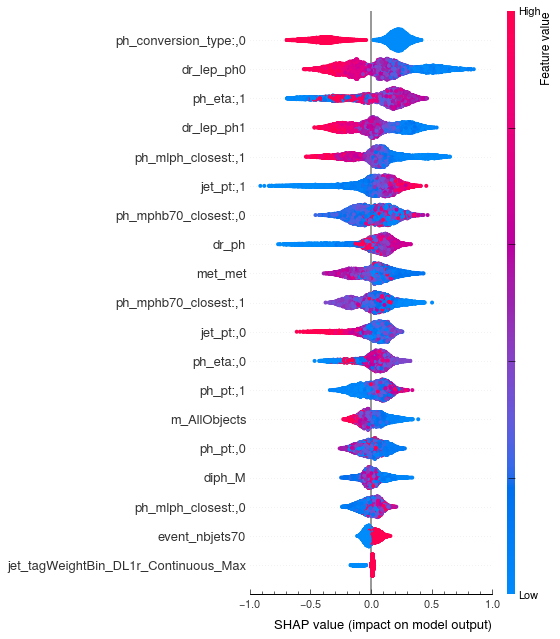

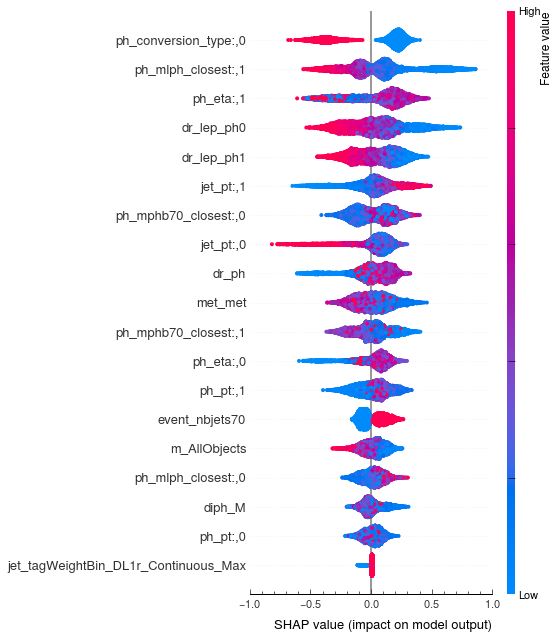

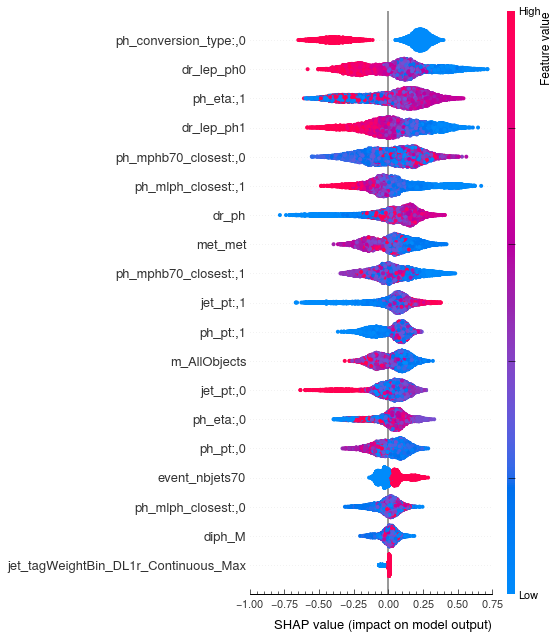

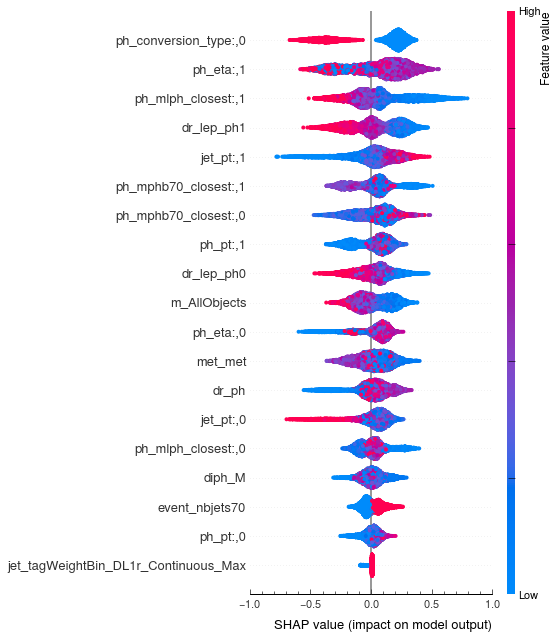

In [96]:
# NOT NEEDED 
# 1. Per-fold “beeswarm” summaries
for idx, model in enumerate(models, start=1):
    explainer   = shap.TreeExplainer(model)
    shap_values = explainer(X_ref_safe)                # shap.Explanation object

    shap.summary_plot(
        shap_values.values,
        X_ref_safe,
        feature_names=safe_names,
        show=True
    )
    plt.title(f"SHAP summary – fold {idx}")
    plt.tight_layout()
    #plt.savefig(f"shap_summary_fold{idx}.png")    # one PNG per fold
    plt.close()

In [53]:
# Latex and [,] for SHAP:
import re

def sanitize(name: str) -> str:
    # drop [ and ] only (':' and ',' are allowed)
    return re.sub(r'[\[\]]', '', name)

feature_display_names_san = {sanitize(k): v for k, v in feature_display_names.items()}


In [54]:
X_ref_san = X_ref.copy()
X_ref_san.columns = [sanitize(c) for c in X_ref_san.columns]


In [55]:
X_plot = X_ref_san.copy()
X_plot.columns = [feature_display_names_san.get(c, c) for c in X_ref_san.columns]


In [51]:
#pretty_cols = [feature_display_names.get(c, c) for c in X_ref_safe.columns]

In [67]:
#X_plot = X_ref_safe.copy()
#X_plot.columns = pretty_cols  # rename only for plotting

for i, model in enumerate(models, start=1):
    explainer = shap.TreeExplainer(model)
    sv = explainer(X_ref_san)          # compute on the original matrix
    shap.summary_plot(
        sv.values,                      # SHAP values array
        X_plot,                         # data with pretty column names
        show=False
    )
    ax = plt.gca()
    ax.set_title(f"SHAP summary – Fold {i}")
    ax.set_xlabel("SHAP Value (Impact on BDT Output)")
    plt.tight_layout()
    #plt.show()
    plt.savefig(f"shap_summary_fold{i}.pdf") 
    plt.close()

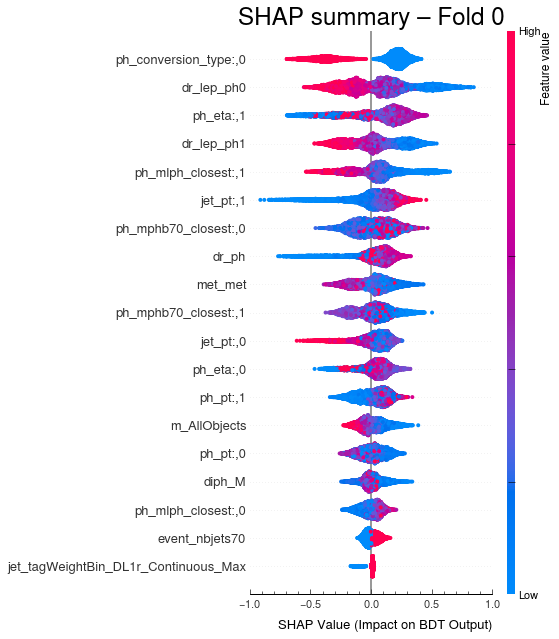

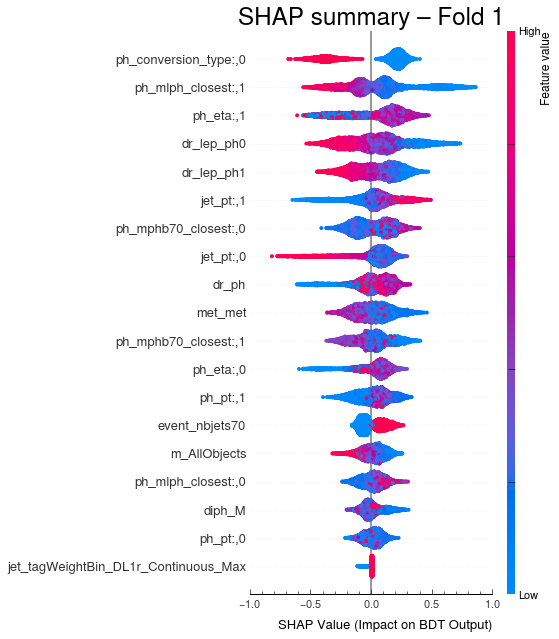

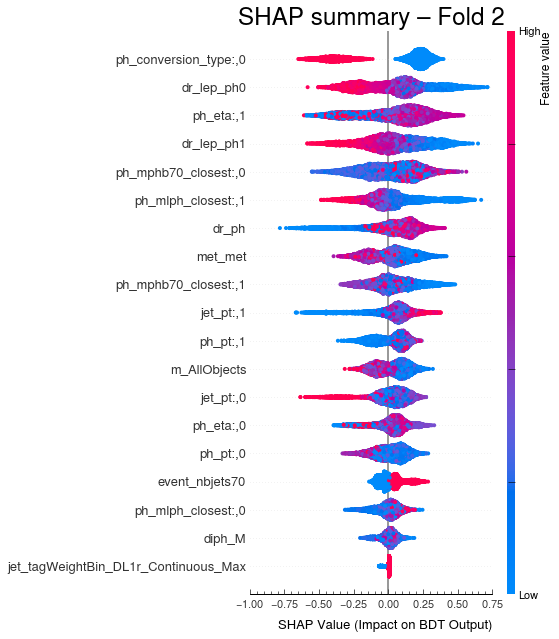

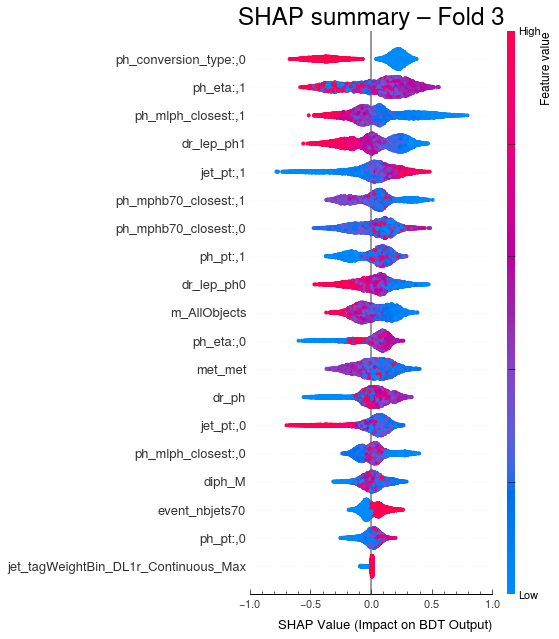

In [105]:
# 1. Per-fold “beeswarm” summaries
for idx, model in enumerate(models, start=0):
    explainer = shap.TreeExplainer(model)
    shap_values = explainer(X_ref_safe) # shap.Explanation object

    # Call summary_plot with show=False to prepare the plot without immediate display
    shap.summary_plot(
        shap_values.values,
        X_ref_safe,
        feature_names=safe_names,
        show=False # <--- MODIFIED: Prevent automatic display by SHAP
    )

    # Get the current Axes object to apply modifications
    ax = plt.gca()

    # Set the title directly on the Axes object
    ax.set_title(f"SHAP summary – Fold {idx}") # <--- MODIFIED: Use set_title on Axes

    # Set the custom x-label directly on the Axes object
    ax.set_xlabel("SHAP Value (Impact on BDT Output)") # <--- ADDED: Custom x-label

    plt.tight_layout()
    #plt.savefig(f"shap_summary_fold{idx}.pdf") # one PNG per fold (uncomment if needed)
    
    plt.show() # <--- ADDED: Explicitly show the plot after modifications
    plt.close() # Close the figure for the next iteration

In [75]:
print(plt.rcParams['text.usetex'])

True


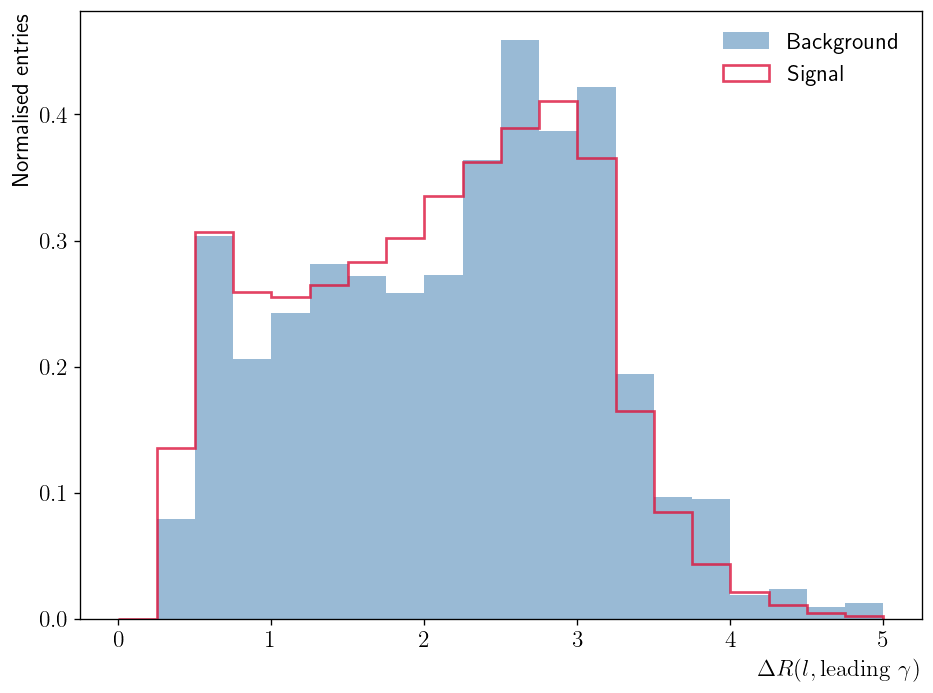

In [85]:
# From above, one can say that the lower values of delta R (l,y) tend to be more signal like -> This is true when one sees the histogram below. 
# If the DR is more, that means that event is more likely to be a background than signal

bins = np.linspace(0.0, 5.0, 21)          # 40 equal-width bins from 0 to 5
plt.figure(figsize=(8,6))
plt.rcParams['font.size'] = 14  # Set default font size to 12

plt.hist(
    df_bkg["dr_lep_ph0"],
    bins=bins,
    weights=df_bkg["weight"],              # omit if you have no event weights
    histtype="stepfilled",
    alpha=0.55,
    color="steelblue",
    density=True,
    label="Background",
)
# 3. overlay the signal (open step line)
plt.hist(
    df_sig["dr_lep_ph0"],
    bins=bins,
    weights=df_sig["weight"],
    histtype="step",
    linewidth=1.6,
    alpha=0.8,
    color="crimson",
    density=True,
    label="Signal",
)

# ------------------------------------------------------------------
# 4. cosmetics
plt.xlabel(r"$\Delta R(l,\mathrm{leading}~\gamma)$", loc='right')
plt.ylabel("Normalised entries", loc='top')
plt.legend(frameon=False)
plt.savefig("delta_R_ly0.pdf")
plt.tight_layout()
plt.show()

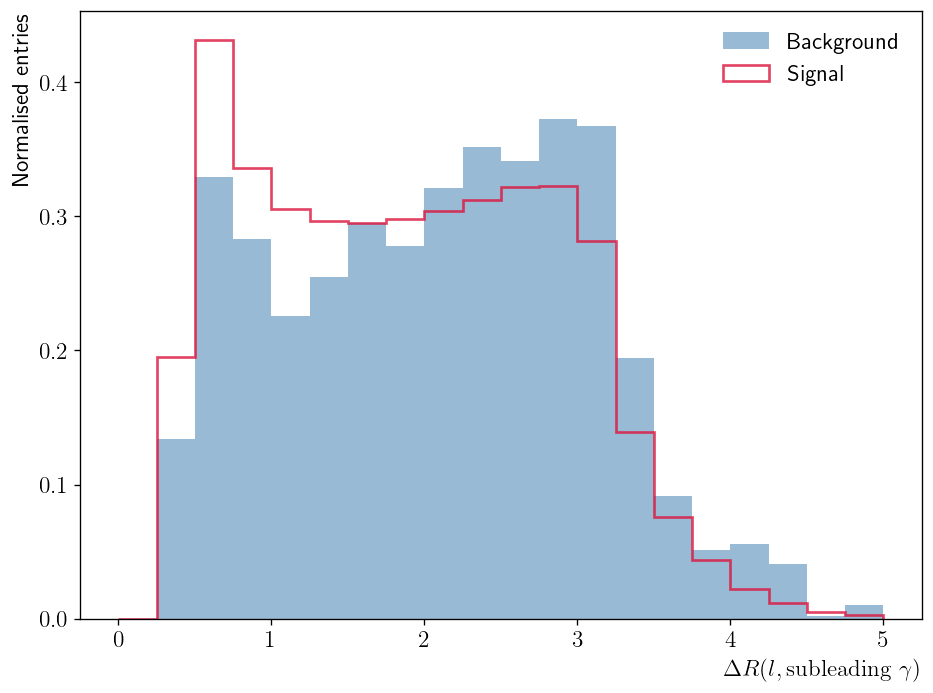

In [84]:
# From above, one can say that the lower values of delta R (l,y) tend to be more signal like -> This is true when one sees the histogram below. 
# If the DR is more, that means that event is more likely to be a background than signal

bins = np.linspace(0.0, 5.0, 21)          # 40 equal-width bins from 0 to 5
plt.figure(figsize=(8,6))

plt.hist(
    df_bkg["dr_lep_ph1"],
    bins=bins,
    weights=df_bkg["weight"],              # omit if you have no event weights
    histtype="stepfilled",
    alpha=0.55,
    color="steelblue",
    density=True,
    label="Background",
)
plt.rcParams['font.size'] = 14  # Set default font size to 12
# 3. overlay the signal (open step line)
plt.hist(
    df_sig["dr_lep_ph1"],
    bins=bins,
    weights=df_sig["weight"],
    histtype="step",
    linewidth=1.6,
    alpha=0.8,
    color="crimson",
    density=True,
    label="Signal",
)

# ------------------------------------------------------------------
# 4. cosmetics
plt.xlabel(r"$\Delta R(l,\mathrm{subleading}~\gamma)$", loc='right')
plt.ylabel("Normalised entries", loc='top')
plt.legend(frameon=False)
plt.savefig("delta_R_ly_1.pdf")
plt.tight_layout()
plt.show()

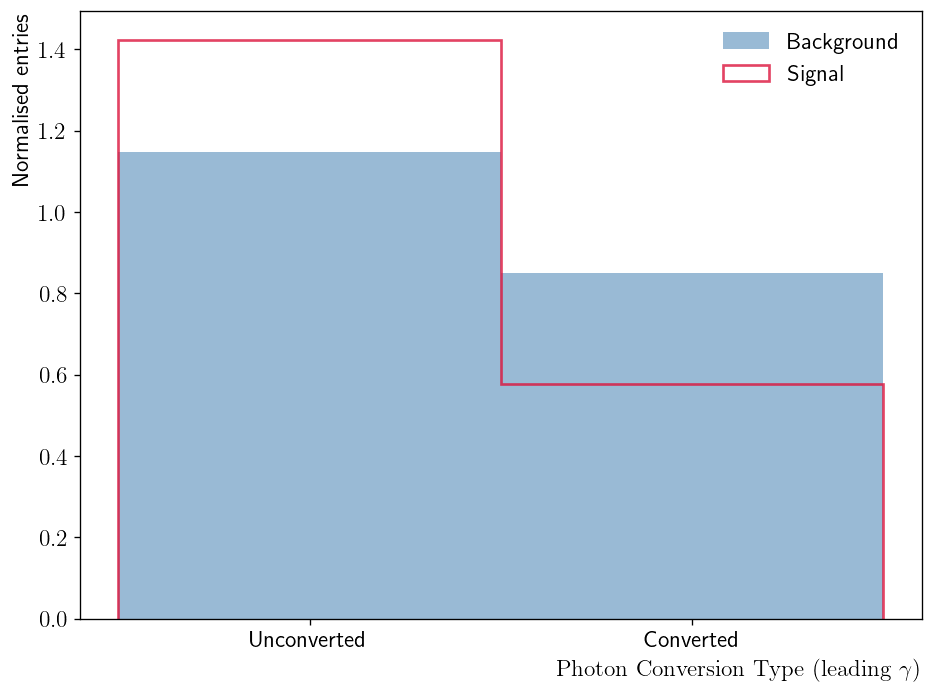

In [82]:
# So signal has more unconverted photons than background.

bins = [0,0.5,1]          # covers 0 and 1 cleanly
plt.figure(figsize=(8,6))
plt.hist(
    df_bkg["ph_conversion_type[:,0]"],
    bins=bins,
    weights=df_bkg["weight"],              # omit if you have no event weights
    histtype="stepfilled",
    alpha=0.55,
    color="steelblue",
    density=True,
    label="Background",
)
plt.rcParams['font.size'] = 14  # Set default font size to 12
# 3. overlay the signal (open step line)
plt.hist(
    df_sig["ph_conversion_type[:,0]"],
    bins=bins,
    weights=df_sig["weight"],
    histtype="step",
    linewidth=1.6,
    alpha=0.8,
    color="crimson",
    density=True,
    label="Signal",
)

# ------------------------------------------------------------------
# 4. cosmetics
plt.xlabel(r"$\mathrm{Photon~Conversion~Type}~(\mathrm{leading}~\gamma)$", loc='right')
plt.ylabel("Normalised entries", loc='top')
plt.xticks([0.25, 0.75], labels=["Unconverted", "Converted"])
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig("ph_conv.pdf")
plt.show()

In [69]:
df_bkg["ph_mlph_closest[:,1]"]

entry
0       114974.125000
1        37401.484375
2        36545.527344
3        15878.922852
4       103400.445312
            ...      
4552    226708.296875
4553     18245.861328
4554    151862.468750
4557     25621.505859
4558     51669.945312
Name: ph_mlph_closest[:,1], Length: 3959, dtype: float32

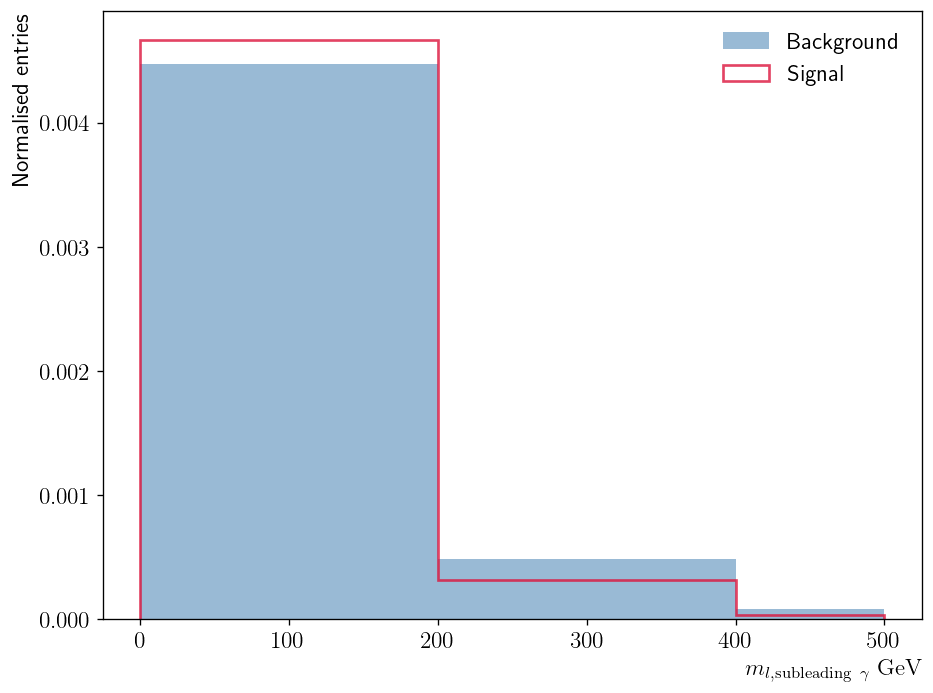

In [83]:
# So signal has more unconverted photons than background.

bins = [0, 200, 400, 500]          # covers 0 and 1 cleanly
plt.figure(figsize=(8,6))
plt.hist(
    df_bkg["ph_mlph_closest[:,1]"]/1000,
    bins=bins,
    weights=df_bkg["weight"],              # omit if you have no event weights
    histtype="stepfilled",
    alpha=0.55,
    color="steelblue",
    density=True,
    label="Background",
)
plt.rcParams['font.size'] = 14  # Set default font size to 12
# 3. overlay the signal (open step line)
plt.hist(
    df_sig["ph_mlph_closest[:,1]"]/1000,
    bins=bins,
    weights=df_sig["weight"],
    histtype="step",
    linewidth=1.6,
    alpha=0.8,
    color="crimson",
    density=True,
    label="Signal",
)

# ------------------------------------------------------------------
# 4. cosmetics
plt.xlabel(r"$m_{l,\mathrm{subleading}~\gamma}\;\mathrm{GeV}$", loc='right')
plt.ylabel("Normalised entries", loc='top')
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig("m_lph.pdf")
plt.show()

Text(0.5, 1.0, 'Feature importance (ensemble average)')

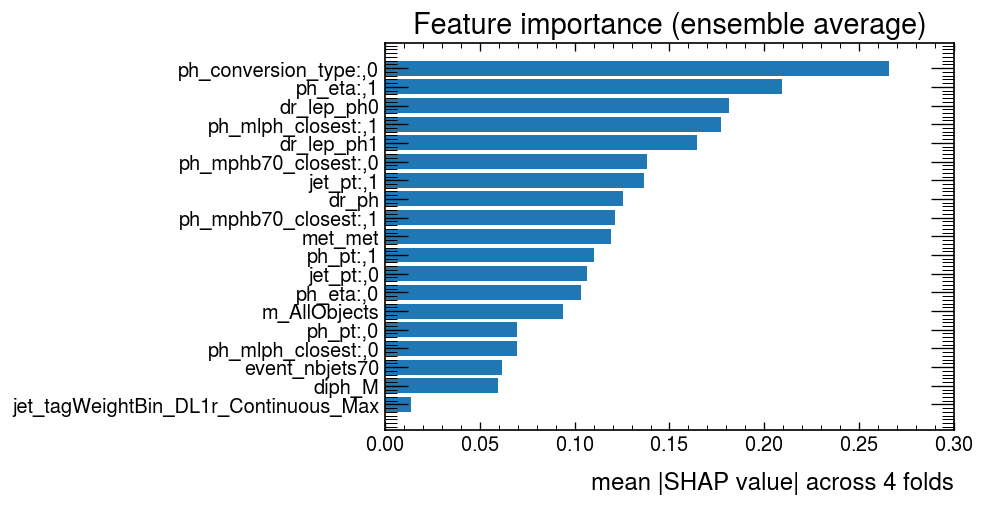

In [55]:
# 2. Aggregate importance over all four folds
abs_vals = np.vstack([
    np.abs(shap.TreeExplainer(m)(X_ref_safe).values)   # |SHAP| per event, per model
    for m in models
])
mean_abs = abs_vals.mean(axis=0)                  # length = n_features
order    = np.argsort(mean_abs)[::-1]

plt.barh(np.array(safe_names)[order][::-1], mean_abs[order][::-1])
plt.xlabel("mean |SHAP value| across 4 folds")
plt.title("Feature importance (ensemble average)")
#plt.tight_layout()
#plt.savefig("shap_bar_ensemble.png")
#plt.close()

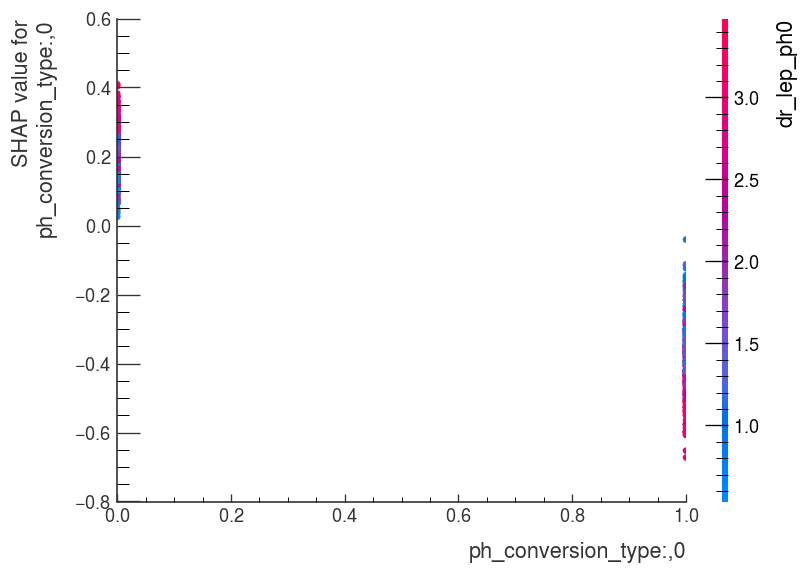

Text(0.5, 1.0, 'ph_conversion_type:,0: SHAP vs raw feature')

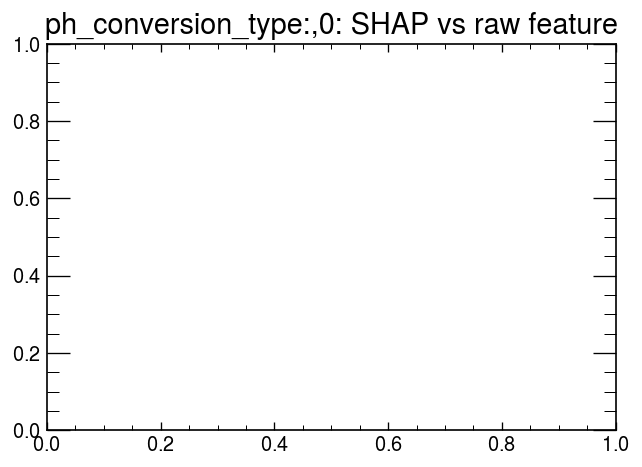

In [56]:
# 3. A dependence plot for the top variable (optional)
top_feature = safe_names[order[0]]
explainer   = shap.TreeExplainer(models[0])       # any one fold is fine here
shap_vals   = explainer(X_ref_safe)

shap.dependence_plot(
    top_feature,
    shap_vals.values,
    X_ref_safe,
    feature_names=safe_names,
    show=True
)
plt.title(f"{top_feature}: SHAP vs raw feature")
#plt.tight_layout()
#plt.savefig(f"shap_depend_{top_feature}.png")
#plt.close()

ph_conversion_type:,0 × ph_mphb70_closest:,0  → 0.039
dr_lep_ph0 × ph_conversion_type:,0  → 0.029
ph_eta:,1 × ph_conversion_type:,0  → 0.027
ph_mlph_closest:,1 × ph_conversion_type:,0  → 0.025
jet_pt:,0 × met_met  → 0.023
dr_lep_ph0 × ph_mphb70_closest:,0  → 0.022
ph_eta:,1 × ph_mphb70_closest:,1  → 0.020
jet_pt:,0 × ph_pt:,1  → 0.019
dr_lep_ph0 × dr_lep_ph1  → 0.018
met_met × ph_pt:,1  → 0.018


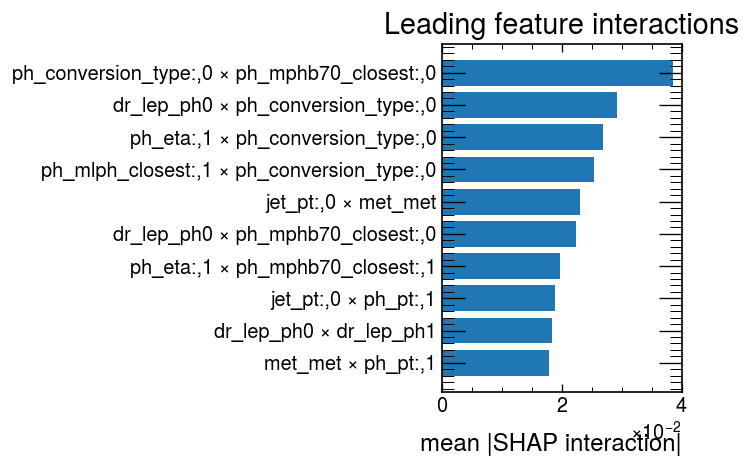

In [60]:
# for one fold; wrap in a loop if you like
expl = shap.TreeExplainer(models[0])
inter = expl.shap_interaction_values(X_ref_safe)    # ndarray [n_events, n_feat, n_feat]

# aggregate absolute values over events
mean_abs_inter = np.abs(inter).mean(axis=0)

# show the top-10 pairs
pairs = np.dstack(np.triu_indices_from(mean_abs_inter, k=1)).reshape(-1, 2)
scores = mean_abs_inter[pairs[:,0], pairs[:,1]]
top = scores.argsort()[::-1][:10]

for (i, j), s in zip(pairs[top], scores[top]):
    print(f"{safe_names[i]} × {safe_names[j]}  → {s:.3f}")
    
    
pairs_txt = [f"{safe_names[i]} × {safe_names[j]}" for (i,j) in pairs[top]]
plt.barh(pairs_txt[::-1], scores[top][::-1])
plt.xlabel("mean |SHAP interaction|")
plt.title("Leading feature interactions")
plt.tight_layout()


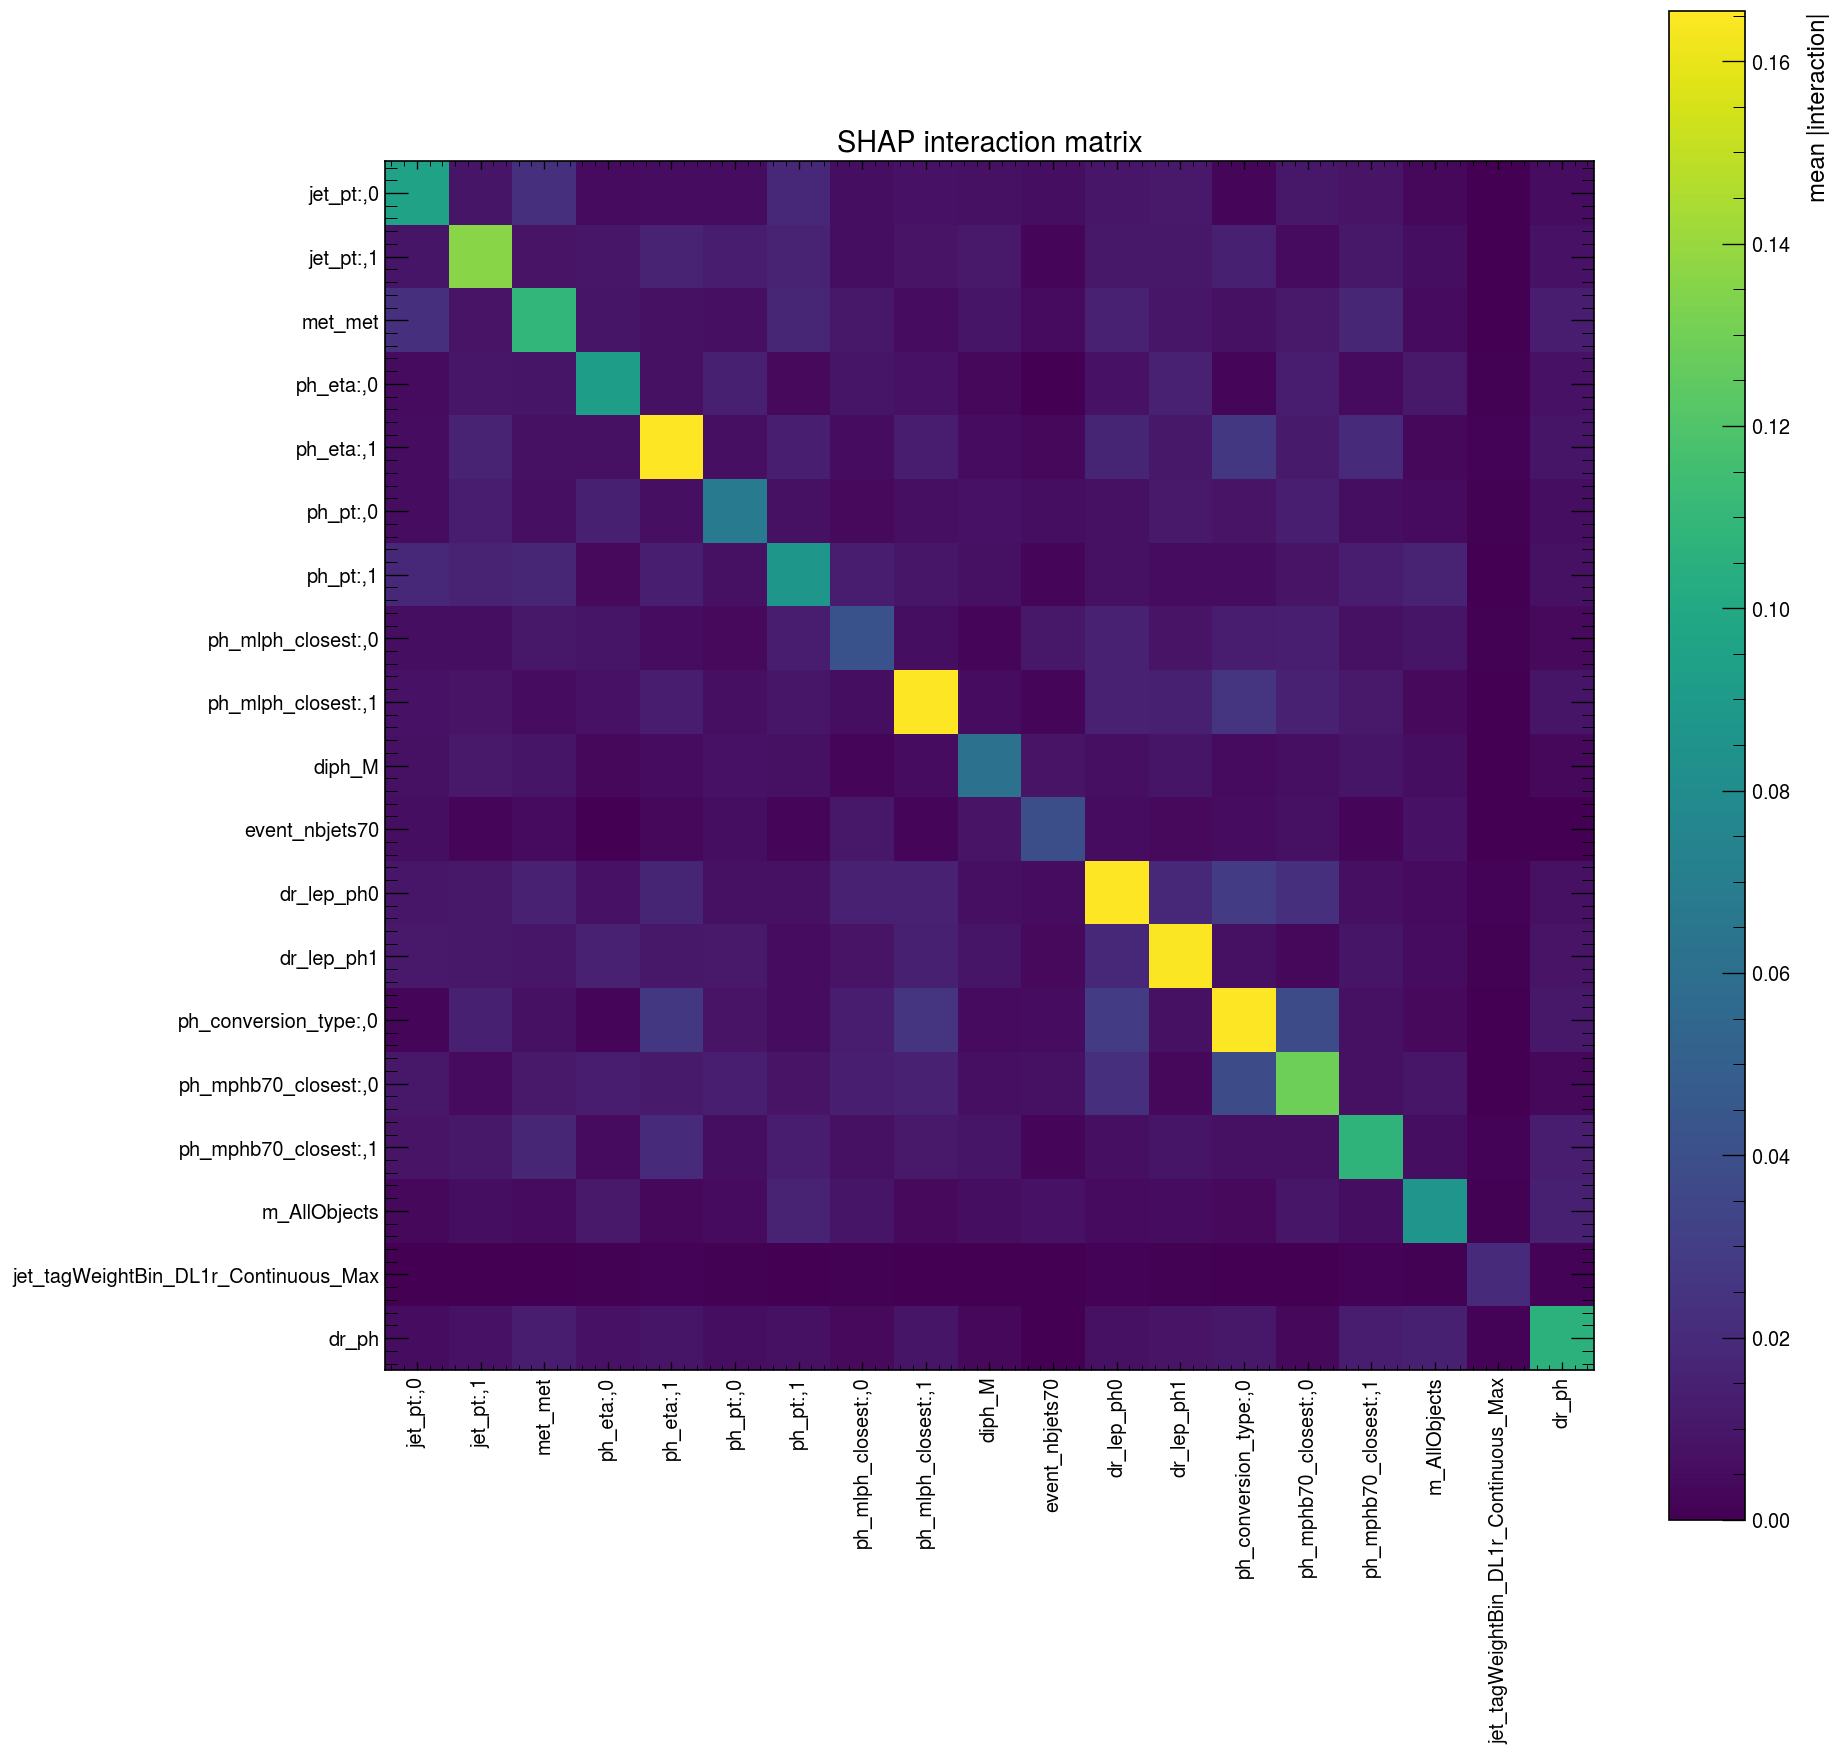

In [62]:
fig, ax = plt.subplots(figsize=(16,15))
im = ax.imshow(mean_abs_inter, cmap="viridis",
               vmin=0, vmax=np.percentile(mean_abs_inter, 99))
ax.set_xticks(range(len(safe_names))); ax.set_xticklabels(safe_names, rotation=90)
ax.set_yticks(range(len(safe_names))); ax.set_yticklabels(safe_names)
fig.colorbar(im, ax=ax, label="mean |interaction|")
plt.title("SHAP interaction matrix"); plt.tight_layout()

In [111]:
expl = shap.TreeExplainer(models[0])
sv   = expl(X_ref_safe)

idx = np.argsort(-model.predict_proba(X_ref_safe)[:,1])
plt.figure(figsize=(12, 8)) # Example: 7 inches wide, 5 inches tall (adjust as needed)

shap.decision_plot(
    expl.expected_value,
    sv.values[idx],
    safe_names,
    feature_display_range=slice(0, 10),  
    ignore_warnings=True,
    show=False
)
# Get the current axes object after shap.decision_plot has drawn on it
ax = plt.gca() # <--- ADDED: Define 'ax' here

ax.set_xlabel("Model output (raw)") # Set the x-axis label
plt.tight_layout() 

# Save the plot
#plt.savefig("shap_tree_model0_10Ksample_10vars.pdf")
# Close the figure to free up memory (good practice, especially in loops)
plt.close()

In [112]:
expl = shap.TreeExplainer(models[0])
sv   = expl(X_ref_safe)

idx = np.argsort(-model.predict_proba(X_ref_safe)[:,1])
plt.figure(figsize=(12, 8)) # Example: 7 inches wide, 5 inches tall (adjust as needed)

shap.decision_plot(
    expl.expected_value,
    sv.values[idx],
    safe_names,
    feature_display_range=slice(0, 19),  
    ignore_warnings=True,
    show=False
)
# Get the current axes object after shap.decision_plot has drawn on it
ax = plt.gca() # <--- ADDED: Define 'ax' here

ax.set_xlabel("Model output (raw)") # Set the x-axis label
plt.tight_layout() 

# Save the plot
plt.savefig("shap_tree_model0_10Ksample_19vars.pdf")
# Close the figure to free up memory (good practice, especially in loops)
plt.close()

In [72]:
# With changed column names
pretty_cols = [feature_display_names_san.get(c, c) for c in X_ref_san.columns]

shap.decision_plot(
    expl.expected_value,
    sv.values,
    feature_names=pretty_cols,           # override with LaTeX-friendly labels
    feature_display_range=slice(0, 10),  # For 10 variables
    show=False

)

# Get the current axes object after shap.decision_plot has drawn on it
ax = plt.gca() # <--- ADDED: Define 'ax' here

ax.set_xlabel("Model output (raw)") # Set the x-axis label
plt.tight_layout() 

# Save the plot
plt.savefig("shap_tree_model0_1Ksample_10vars.pdf")
# Close the figure to free up memory (good practice, especially in loops)
plt.close()

In [71]:
# With changed column names
pretty_cols = [feature_display_names_san.get(c, c) for c in X_ref_san.columns]

shap.decision_plot(
    expl.expected_value,
    sv.values,
    feature_names=pretty_cols,           # override with LaTeX-friendly labels
    feature_display_range=slice(0, 19),  # For 19 variables
    show=False
)

# Get the current axes object after shap.decision_plot has drawn on it
ax = plt.gca() # <--- ADDED: Define 'ax' here

ax.set_xlabel("Model output (raw)") # Set the x-axis label
plt.tight_layout() 

# Save the plot
plt.savefig("shap_tree_model0_1Ksample_19vars.pdf")
# Close the figure to free up memory (good practice, especially in loops)
plt.close()

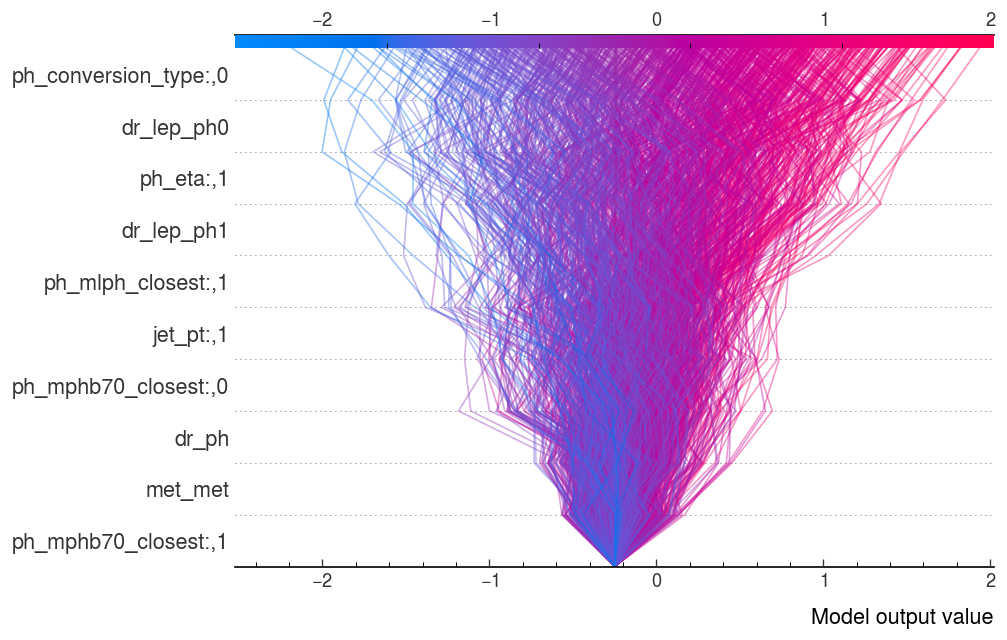

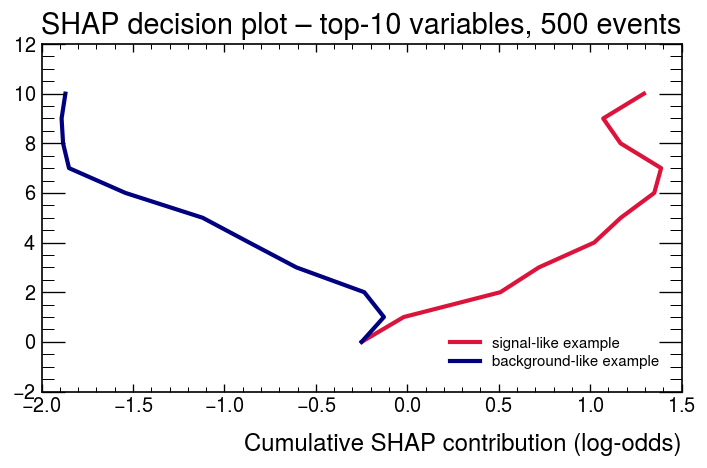

In [77]:
# -----------------------------------------------------
# 0. imports & baseline objects (same as before)
expl      = shap.TreeExplainer(models[0])
sv        = expl(X_ref_safe)                  # shap.Explanation
log_odds  = models[0].predict_proba(X_ref_safe)[:, 1]      # signal proba
# -----------------------------------------------------

# 1. pick a modest sample of events, sorted by final score
n_events  = 1000                               # 400 lines is legible; tune to taste
idx_score = np.argsort(-log_odds)             # high-score → first
rows      = idx_score[:n_events]              # top-N signal-like and gradually bkg-like

# 2. keep only the K most influential features
K = 10                                         # show top-8 variables
top_feats = np.argsort(np.abs(sv.values).mean(axis=0))[::-1][:K]
feat_names_top = np.array(safe_names)[top_feats]

# 3. create the decision plot
shap.decision_plot(
    expl.expected_value,
    sv.values[rows][:, top_feats],            # rows × cols subset
    feature_names=feat_names_top,
    link='identity',                          # keep log-odds scale
    highlight=None,                           # we will colour manually below
    return_objects=True,                       # gives us (fig, ax) to customise
    alpha=0.4
)

# 4. post-process for clarity  (Matplotlib handle)
fig = plt.gcf(); ax = plt.gca()

#   a) fade the many trajectories
for line in ax.get_lines():
    line.set_alpha(0.2)                      # transparent spaghetti

#   b) highlight 1 prototype signal & 1 background event
sig_example = idx_score[  0]                  # highest score
bkg_example = idx_score[-1]                  # lowest score

ax.plot(                                     # bright red
    np.cumsum( np.hstack([expl.expected_value,
                          sv.values[sig_example, top_feats]]) ),
    np.arange(K+1), lw=2.5, color='crimson', label='signal-like example'
)
ax.plot(                                     # bright blue
    np.cumsum( np.hstack([expl.expected_value,
                          sv.values[bkg_example, top_feats]]) ),
    np.arange(K+1), lw=2.5, color='navy',    label='background-like example'
)

#   c) cosmetic adjustments
ax.legend(loc='lower right', frameon=False, fontsize=9)
ax.set_title("SHAP decision plot – top-10 variables, 1000 events")
ax.set_xlabel("Cumulative SHAP contribution (log-odds)")
fig.tight_layout()

# 5. save if needed
# fig.savefig("decision_plot_clean.png", dpi=300)


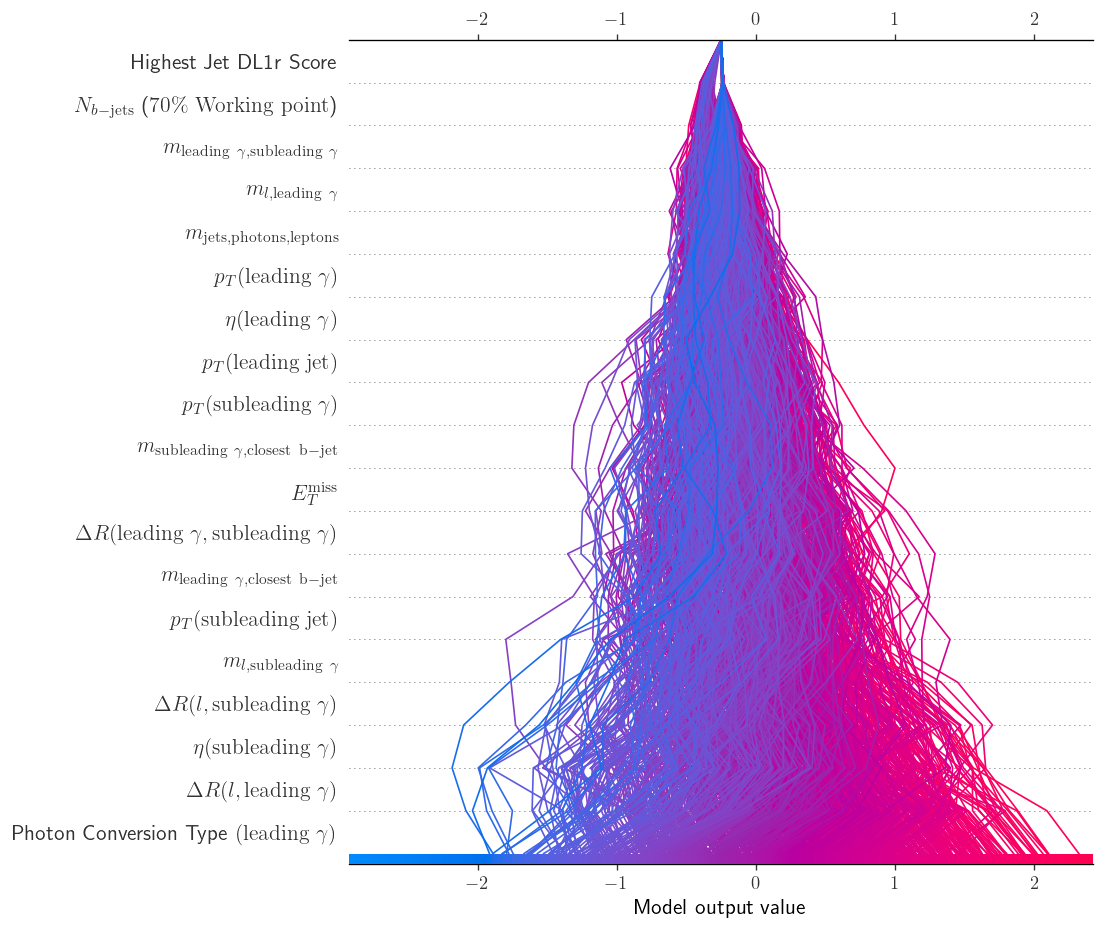

In [62]:
# Assumes you already have:
# - X_ref_san  (sanitized data given to the model/SHAP)
# - feature_display_names_san  (sanitized -> pretty LaTeX labels dict)
# - models     (list of trained models)

# 1) Choose the model and compute SHAP on the sanitized matrix
model = models[0]
expl  = shap.TreeExplainer(model)
sv    = expl(X_ref_san)

# 2) Sort by model score for class 1 (keep the same matrix used for SHAP)
idx = np.argsort(-model.predict_proba(X_ref_san)[:, 1])

# 3) Build pretty labels in the *same order* as X_ref_san.columns
pretty_cols = [feature_display_names_san.get(c, c) for c in X_ref_san.columns]

# 4) Pick the correct expected value (class 1 if array-like)
exp_val = expl.expected_value
if np.ndim(exp_val) > 0 and len(exp_val) > 1:
    exp_val = exp_val[1]  # class-1 baseline

# 5) Plot
plt.figure(figsize=(12, 8))
shap.decision_plot(
    exp_val,
    sv.values[idx],
    feature_names=pretty_cols,          # <-- use LaTeX-friendly labels
    feature_display_range=slice(0, 19),
    ignore_warnings=True,
   # show=False
)
ax = plt.gca()
ax.set_xlabel("Model output (raw)")
plt.tight_layout()
#plt.savefig("shap_tree_model0_10Ksample_19vars.pdf")
plt.close()


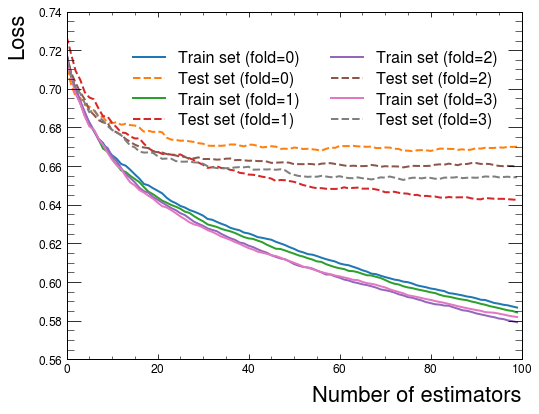

In [40]:
    
    
# Plotting the results
fig, ax = plt.subplots(figsize=(8,6))
for fold in range(nfolds):
    #estimators = range(0, 100)
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train set ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test set ({fold=})', linestyle='--')

ax.legend(title=' ',ncols=2, fontsize=16)
ax.set_title('')
#mplhep.atlas.label('Loss', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Number of estimators', fontsize=22)
ax.set_ylabel('Loss', fontsize=22)
plt.savefig(f'loss_curve_bdt.pdf')

plt.show()

In [24]:
model.classes_

array([0, 1])

In [23]:
X_sig = df_sig[feature_cols].to_numpy().astype(np.float32) 
X_bkg = df_bkg[feature_cols].to_numpy().astype(np.float32) 

results_sig_list = [model.predict_proba(X_sig)[:,1] for model in models]   #array of bdt scores
results_bkg_list = [model.predict_proba(X_bkg)[:,1] for model in models]   #array of bdt scores

print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))

# Separate into folds
condlist_sig = [df_sig['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg = [df_bkg['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg = np.select(condlist_bkg, results_bkg_list)

print('Fold separated arrays for BDT scroes:')
results_sig, results_bkg
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg))

Arrays for BDT scroes:
Sig:  [array([0.38470507, 0.6107897 , 0.74128175, ..., 0.6996987 , 0.7840011 ,
       0.4232085 ], dtype=float32), array([0.38084346, 0.64491856, 0.8281398 , ..., 0.64656556, 0.6466758 ,
       0.49305916], dtype=float32), array([0.47967094, 0.66673714, 0.77038604, ..., 0.75205654, 0.7570192 ,
       0.46313927], dtype=float32), array([0.38402313, 0.59649116, 0.7411056 , ..., 0.6643472 , 0.7881384 ,
       0.46128938], dtype=float32)]
Bkg:  [array([0.39310488, 0.5937471 , 0.6949709 , ..., 0.62826705, 0.21447209,
       0.69513667], dtype=float32), array([0.34290212, 0.58381194, 0.64769024, ..., 0.09591258, 0.34787187,
       0.7234801 ], dtype=float32), array([0.611714  , 0.5618843 , 0.54959637, ..., 0.12623632, 0.22885133,
       0.6532288 ], dtype=float32), array([0.43033057, 0.7204953 , 0.6963612 , ..., 0.1260042 , 0.459312  ,
       0.66360044], dtype=float32)]
Length:  4
Fold separated arrays for BDT scroes:
Length sig:  323900
Length bkg:  3959


In [30]:

def make_edges(x_sig, x_bkg, n_bins):
    """
    Build bin edges by quantiles of the combined signal+background distribution,
    with a tiny padding to avoid zero‐width bins.
    """
    all_vals = np.concatenate([x_sig, x_bkg])
    qs = np.linspace(0, 1, n_bins + 1)
    edges = np.quantile(all_vals, qs)
    edges[0]  -= 1e-8
    edges[-1] += 1e-8
    return edges

def separation_power(x_sig, w_sig, x_bkg, w_bkg, n_bins=40):
    """
    Compute the TMVA‐style separation power, expressed as a fraction.
    """
    edges = make_edges(x_sig, x_bkg, n_bins)
    # normalized densities
    s_counts, _ = np.histogram(x_sig, bins=edges, weights=w_sig, density=True)
    b_counts, _ = np.histogram(x_bkg, bins=edges, weights=w_bkg, density=True)
    widths = np.diff(edges)

    # compute (s - b)^2 / (s + b), safely handling zeros
    with np.errstate(divide='ignore', invalid='ignore'):
        num  = (s_counts - b_counts)**2
        den  = (s_counts + b_counts)
        frac = np.nan_to_num(num / den)  # zero where den==0
    return 0.5 * np.sum(frac * widths)

# --- USAGE EXAMPLE ---

# Assume you have:
#   df_sig: pandas DataFrame of signal events, with columns=feature_cols + 'weight'
#   df_bkg: pandas DataFrame of background events, with columns=feature_cols + 'weight'
#   feature_cols: list of the feature‐column names

w_sig = df_sig['weight'].to_numpy()
w_bkg = df_bkg['weight'].to_numpy()

separations = {}
for feat in feature_cols:
    x_sig = df_sig[feat].to_numpy()
    x_bkg = df_bkg[feat].to_numpy()
    S_frac = separation_power(x_sig, w_sig, x_bkg, w_bkg, n_bins=10)
    separations[feat] = S_frac * 100.0   # convert to percentage

# print features sorted by descending separation
for feat, S_pct in sorted(separations.items(), key=lambda kv: kv[1], reverse=True):
    print(f"{feat:20s} separation = {S_pct:6.2f}%")


ph_conversion_type[:,0] separation =   2.04%
dr_ph                separation =   1.94%
ph_eta[:,1]          separation =   1.75%
ph_mlph_closest[:,1] separation =   1.48%
diph_M               separation =   1.35%
jet_pt[:,0]          separation =   1.32%
dr_lep_ph1           separation =   1.19%
ph_eta[:,0]          separation =   1.14%
jet_pt[:,1]          separation =   0.69%
dr_lep_ph0           separation =   0.67%
jet_tagWeightBin_DL1r_Continuous_Max separation =   0.57%
m_AllObjects         separation =   0.56%
met_met              separation =   0.55%
ph_mphb70_closest[:,0] separation =   0.51%
ph_mlph_closest[:,0] separation =   0.51%
ph_pt[:,0]           separation =   0.43%
ph_mphb70_closest[:,1] separation =   0.30%
ph_pt[:,1]           separation =   0.24%
event_nbjets70       separation =   0.17%


Text(0.25, 1.75, '6.07%')

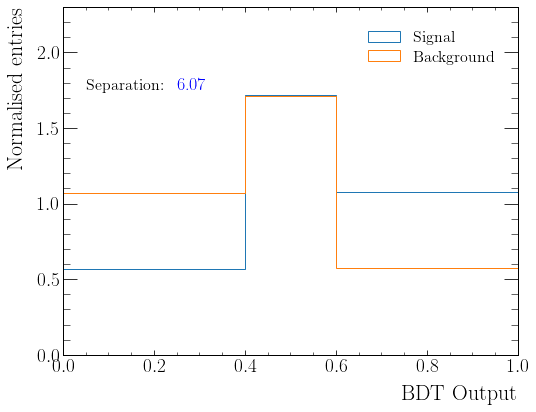

In [50]:

plt.figure(figsize=(8,6))
# Define custom bin edges
custom_bins = [0, 0.4, 0.6, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right', prop={'size': 16,'weight': 'bold'})  #fontsize won't work because prop will override it
plt.xlabel('BDT Output', fontsize=22)
plt.ylabel('Normalised entries', fontsize=22)
plt.ylim(0, 2.3) # Set y-axis from 0 to 2.0 (adjust as needed)
#plt.text(x=0.05, y=1.75,s=F'Separation: {separation*100:.2f}%', fontsize=16, fontweight='bold')
plt.text(x=0.05, y=1.75,s=F'Separation: ', fontsize=16, fontweight='bold')
plt.text(x=0.25, y=1.75,s=F'{separation*100:.2f}%', fontsize=18, color='blue')

#mplhep.atlas.label('Internal', data=False)   # true to remove Simulation
#plt.savefig(f'separation_fittedbins_19vars.pdf')


sig histogram values:  [0.00515428 0.23281972 0.77336752 1.25568342 1.58730469 1.84812703
 1.90868208 1.60170593 0.74491617 0.04223901]
bkg histogram values:  [0.0521865  0.79951133 1.61279936 1.80378816 1.88734069 1.53980429
 1.39029182 0.69322502 0.21847681 0.0025761 ]


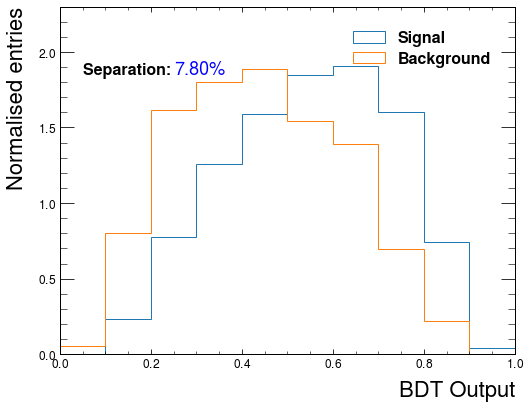

In [43]:
# Considering Negative Weights

plt.figure(figsize=(8,6))

bc_sig,_,_ = plt.hist(results_sig, weights=(df_sig['weight']),  range=(0,1), bins=nbins, histtype='step', density=True, label='Signal')
bc_bkg,_,_ = plt.hist(results_bkg, weights=(df_bkg['weight']), range=(0,1), bins=nbins, histtype='step', density=True, label='Background')
print('sig histogram values: ',bc_sig )
print('bkg histogram values: ',bc_bkg )

separation = 0.5 * np.sum(np.nan_to_num(((bc_sig/nbins - bc_bkg/nbins) ** 2) / (bc_sig/nbins + bc_bkg/nbins)))

plt.legend(loc='upper right', prop={'size': 16,'weight': 'bold'})  #fontsize won't work because prop will override it
plt.xlabel('BDT Output', fontsize=22)
plt.ylabel('Normalised entries', fontsize=22)

plt.ylim(0, 2.3) # Set y-axis from 0 to 2.0 (adjust as needed)
plt.text(x=0.05, y=1.85,s=F'Separation: ', fontsize=16, fontweight='bold')
plt.text(x=0.25, y=1.85,s=F'{separation*100:.2f}%', fontsize=18, color='blue')
#mplhep.atlas.label('Internal', data=False, loc=1)   # true to remove Simulation
plt.savefig(f'separation_10bins_19vars.pdf')


# DPG 2025 slides

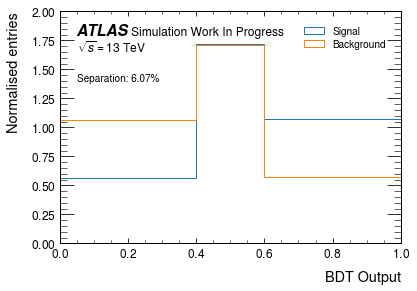

In [24]:

# Define custom bin edges
custom_bins = [0, 0.4, 0.6, 1]

# Create figure and axis explicitly
fig, ax = plt.subplots()

# Histogram plotting
bc_sig, bin_edges, _ = ax.hist(results_sig, weights=df_sig['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = ax.hist(results_bkg, weights=df_bkg['weight'], bins=custom_bins, histtype='step', density=True, label='Background')


# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)


mplhep.atlas.label('Work In Progress', data=False, ax=ax, fontsize=12)  # Explicitly pass ax

# Plotting details
ax.legend(loc='upper right')
ax.set_xlabel('BDT Output')
ax.set_ylabel('Normalised entries')
ax.text(x=0.05, y=1.4, s=f'Separation: {separation*100:.2f}%')
plt.show()

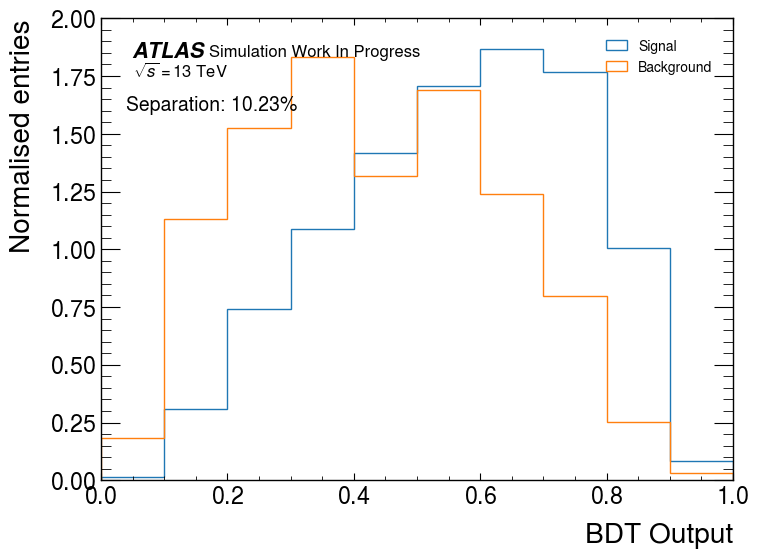

In [31]:

# Create figure and axis explicitly
fig, ax = plt.subplots()

# Plot histograms
bc_sig, _, _ = ax.hist(results_sig, weights=df_sig['weight'], range=(0,1), bins=nbins, 
                        histtype='step', density=True, label='Signal')
bc_bkg, _, _ = ax.hist(results_bkg, weights=df_bkg['weight'], range=(0,1), bins=nbins, 
                        histtype='step', density=True, label='Background')

# Compute separation
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig/nbins - bc_bkg/nbins) ** 2) / (bc_sig/nbins + bc_bkg/nbins)))

# Apply ATLAS label
mplhep.atlas.label('Work In Progress', data=False, ax=ax, fontsize=12)  # Explicitly pass ax

# Labels and text
#ax.legend(loc='upper right')
ax.legend(loc='upper right', fontsize=10, labelspacing=0.5, handlelength=1.5)
ax.set_xlabel('BDT Output')
ax.set_ylabel('Normalised entries')
ax.text(0.04, 1.6, f'Separation: {separation*100:.2f}%')

# Show or save figure
# plt.savefig('separation.pdf')
plt.show()

In [78]:
# Define the custom formatter function
def custom_formatter(x, pos):
    return f'{x * 0.1:.1f}'

In [ ]:
## !!!! KS test with fitted bins

# Working code - Per fold. Change no. of folds
# Unweighted  - with corrected Sumw2()
# Normalized with auc
folds = 4
fold = 2
fig, axes = plt.subplots(nrows=2,ncols=1,gridspec_kw={'height_ratios': [3, 1]}, sharex=True)
custom_bins = [0, 0.39, 0.6, 1]


# Example dummy data and plots:
results_sig_fold_test = results_sig_85_reweighted[df_sig_85_reweighted['eventNumber']%folds == fold]
results_bkg_fold_test = results_bkg_85_reweighted[df_bkg_85_reweighted['eventNumber']%folds == fold]
weights_sig_fold_test = df_sig_85_reweighted['weight'][df_sig_85_reweighted['eventNumber']%folds == fold]
weights_bkg_fold_test = df_bkg_85_reweighted['weight'][df_bkg_85_reweighted['eventNumber']%folds == fold]
y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
weights = np.concatenate([weights_sig_fold_test,weights_bkg_fold_test])

results_sig_fold_train = results_sig_85_reweighted[df_sig_85_reweighted['eventNumber']%folds != fold]
results_bkg_fold_train = results_bkg_85_reweighted[df_bkg_85_reweighted['eventNumber']%folds != fold]
weights_sig_fold_train = df_sig_85_reweighted['weight'][df_sig_85_reweighted['eventNumber']%folds != fold]
weights_bkg_fold_train = df_bkg_85_reweighted['weight'][df_bkg_85_reweighted['eventNumber']%folds != fold]
y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
weights = np.concatenate([weights_sig_fold_train,weights_bkg_fold_train])

"""
bc, bb = np.histogram(data1, weights=weights1, range=(-3,3), bins=10)
sumW2, bb = np.histogram(data1, weights=weights1**2, range=(-3,3), bins=10)
mplhep.histplot(bc,bb,yerr=np.sqrt(sumW2),density=True,label='10000 events, weight=0.1', histtype='errorbar')
"""
#bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, bins=np.linspace(0,1,11), density=True)


bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, range=(0,1), bins=custom_bins, density=True)
total_sig_train = len(results_sig_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_train,bb,yerr=np.sqrt(sumW2), density=True, label='sig (train)', histtype='step', ax=axes[0], color='red', alpha=0.3, linewidth=4)
bc_sig_train_e = np.sqrt(sumW2)

bc_sig_test, bb = np.histogram(results_sig_fold_test,  weights=weights_sig_fold_test, range=(0,1), bins=custom_bins, density=True)
total_sig_test = len(results_sig_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_sig_fold_test, weights=weights_sig_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_test,bb,yerr=np.sqrt(sumW2),density=True, label='sig (test)', histtype='errorbar', ax=axes[0], color='red', markersize=7)
bc_sig_test_e = np.sqrt(sumW2)

bc_bkg_train, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train, range=(0,1), bins=custom_bins, density=True)
total_bkg_train = len(results_bkg_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg_train,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (train)', histtype='step', ax=axes[0], color='blue', alpha=0.3, linewidth=4)
bc_bkg_train_e = np.sqrt(sumW2)


bc_bkg_test, bb = np.histogram(results_bkg_fold_test,  weights=weights_bkg_fold_test, range=(0,1), bins=custom_bins, density=True)
total_bkg_test = len(results_bkg_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_bkg_fold_test, weights=weights_bkg_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg_test,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (test)', histtype='errorbar', ax=axes[0], color='blue', markersize=7)
bc_bkg_test_e = np.sqrt(sumW2)

print(bb)


print("-----------------------------------------------")
# Example check if data is within expected range
print(bc_sig_train.min(), bc_sig_train.max())
print(bc_sig_test.min(), bc_sig_test.max())

print(len(bb), len(bc_sig_train), len(bc_bkg_train))
bc_bkg_test = np.where(bc_bkg_test == 0, 1e-1, bc_bkg_test)


corr_factor_sig = np.sum(bc_sig_train)/np.sum(bc_sig_test)
chi2_sig, p_sig = chisquare(bc_sig_train, bc_sig_test*corr_factor_sig)
corr_factor_bkg = np.sum(bc_bkg_train)/np.sum(bc_bkg_test)
chi2_bkg, p_bkg = chisquare(bc_bkg_train, bc_bkg_test*corr_factor_bkg)


axes[0].set_xlim(0,1)
axes[0].set_ylim(0,4)

#scale_and_format_y_axis(axes[0], scale_factor=0.1)  # Adjust scale_factor as needed

# Create the FuncFormatter object
formatter = mtick.FuncFormatter(custom_formatter)

# Apply the custom formatter to the y-axis
axes[0].yaxis.set_major_formatter(formatter)
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(1))   # removing this will lead to duplicate labels


axes[0].legend(title=F'Fold={fold}', loc='upper right')

#ax.set_xlabel('BDT score')
axes[0].set_ylabel('Fraction of events', labelpad=20)
mplhep.atlas.label('Internal', data=False, ax=axes[0])
axes[0].text(x=0.05, y=2.6,s=F'Signal: $\chi^2$ $p$-value={p_sig:.2f}\nBkg:     $\chi^2$ $p$-value={p_bkg:.2f}')
axes[0].tick_params(axis='both', labelsize=10)

print("Signal train histogram:", bc_sig_train)
print("Signal test histogram:", bc_sig_test)
print("Background train histogram:", bc_bkg_train)
print("Background test histogram:", bc_bkg_test)

print("-----------------------------------------------")




print("\nSignal train errors:", bc_sig_train_e)
print("Signal test errors:", bc_sig_test_e)
print("Background train errors:", bc_bkg_train_e)
print("Background test errors:", bc_bkg_test_e)

print("-----------------------------------------------")

ratio_sig = np.where(bc_sig_test == 0, 1, bc_sig_train / bc_sig_test)
ratio_bkg = np.where(bc_bkg_test == 0, 1, bc_bkg_train / bc_bkg_test)


print("\nSig ratio: ", ratio_sig)
print("Bkg ratio: ", ratio_bkg)


ratio_sig_e = np.sqrt((bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*(bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*bc_sig_test_e*bc_sig_test_e+(1/(1.0*bc_sig_test))*(1/(1.0*bc_sig_test))*bc_sig_train_e*bc_sig_train_e)
ratio_bkg_e = np.sqrt((bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*(bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*bc_bkg_test_e*bc_bkg_test_e+(1/(1.0*bc_bkg_test))*(1/(1.0*bc_bkg_test))*bc_bkg_train_e*bc_bkg_train_e)

print("\nSig Ratio uncertainties per bin: ", ratio_sig_e)



# Clip errors and add padding
max_error = 100  # Example maximum error threshold
clipped_errors_sig = np.clip(ratio_sig_e, 0, max_error)
clipped_errors_bkg = np.clip(ratio_bkg_e, 0, max_error)

print("Clipped errors:", clipped_errors_sig)
print("Clipped errors:", clipped_errors_bkg)

custom_bins = np.array([0, 0.382, 0.6, 1])


#bb_centers = (bb[:-1] + bb[1:]) / 2
bb_centers = (custom_bins[:-1] + custom_bins[1:]) / 2

mplhep.histplot(ratio_sig, custom_bins, histtype='step', ax=axes[1], color='red', linewidth=2)
mplhep.histplot(ratio_bkg, custom_bins, histtype='step', ax=axes[1], color='blue', linewidth=2)

#bin_width = bb[1] - bb[0] 
#bin_width = custom_bins[1] - custom_bins[0]  # Update bin width based on custom bins
bin_widths = np.diff(custom_bins)  # Using np.diff to calculate the distance between bin edges
print(bin_widths)

    
# Plot the uncertainty band using custom bin centers and the clipped errors
for center, err, width in zip(bb_centers, clipped_errors_sig, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='red', alpha=0.1, edgecolor='red', hatch='\\\\', align='center')

for center, err, width in zip(bb_centers, clipped_errors_bkg, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='blue', alpha=0.1, edgecolor='blue', hatch='\\\\', align='center')


#axes[1].set_dashes((5,2))

axes[1].axhline(1,0,1,linestyle='--',color='grey', linewidth=1)
axes[1].set_ylabel('train/test')
axes[1].set_xlabel('BDT score')
axes[1].tick_params(axis='both', labelsize=10)

axes[1].set_ylim(0.1,1.9)  # Adjust based on your ratio values
fig.tight_layout()
fig.subplots_adjust(hspace=0.02)
#fig.savefig(f'Test_Train_Chi_Squared_Unweighted_{fold}_Model7_85To70PerProcess_fittedBins.png')

-----------------------------------------------
0.570156600429227 1.7265703649126498
0.5565786534796923 1.6912229185029304
4 3 3
Signal train histogram: [0.5701566  1.72657036 1.06655826]
Signal test histogram: [0.55657865 1.69122292 1.09780989]
Background train histogram: [1.07666935 1.72766851 0.5594964 ]
Background test histogram: [1.03871322 1.67193616 0.6253187 ]
-----------------------------------------------

Signal train errors: [0.03106391 0.03821597 0.04232477]
Signal test errors: [0.01777692 0.02187367 0.02478245]
Background train errors: [0.6958286 0.5602885 0.4794666]
Background test errors: [0.34002468 0.3779503  0.2651248 ]
-----------------------------------------------

Sig ratio:  [1.02439538 1.02090052 0.97153275]
Bkg ratio:  [1.03654149 1.03333402 0.89473799]

Sig Ratio uncertainties per bin:  [0.06469566 0.02617161 0.0443554 ]
Clipped errors: [0.06469566 0.02617161 0.0443554 ]
Clipped errors: [0.75092804 0.40849206 0.85546691]
[0.4 0.2 0.4]


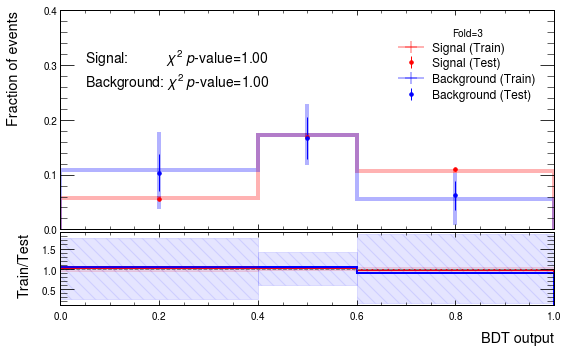

In [55]:
## !!!! KS test with fitted bins
# Define the custom formatter function
def custom_formatter(x, pos):
    return f'{x * 0.1:.1f}'
# Working code - Per fold. Change no. of folds
# Unweighted  - with corrected Sumw2()
# Normalized with auc
folds = 4
fold = 3
fig, axes = plt.subplots(nrows=2,ncols=1,gridspec_kw={'height_ratios': [3, 1]}, sharex=True,figsize=(8,5))
custom_bins = [0, 0.4, 0.6, 1]


# Example dummy data and plots:
results_sig_fold_test = results_sig[df_sig['eventNumber']%folds == fold]
results_bkg_fold_test = results_bkg[df_bkg['eventNumber']%folds == fold]
weights_sig_fold_test = df_sig['weight'][df_sig['eventNumber']%folds == fold]
weights_bkg_fold_test = df_bkg['weight'][df_bkg['eventNumber']%folds == fold]
y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
weights = np.concatenate([weights_sig_fold_test,weights_bkg_fold_test])

results_sig_fold_train = results_sig[df_sig['eventNumber']%folds != fold]
results_bkg_fold_train = results_bkg[df_bkg['eventNumber']%folds != fold]
weights_sig_fold_train = df_sig['weight'][df_sig['eventNumber']%folds != fold]
weights_bkg_fold_train = df_bkg['weight'][df_bkg['eventNumber']%folds != fold]
y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
weights = np.concatenate([weights_sig_fold_train,weights_bkg_fold_train])

"""
bc, bb = np.histogram(data1, weights=weights1, range=(-3,3), bins=10)
sumW2, bb = np.histogram(data1, weights=weights1**2, range=(-3,3), bins=10)
mplhep.histplot(bc,bb,yerr=np.sqrt(sumW2),density=True,label='10000 events, weight=0.1', histtype='errorbar')
"""
#bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, bins=np.linspace(0,1,11), density=True)


bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, range=(0,1), bins=custom_bins, density=True)
total_sig_train = len(results_sig_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_train,bb,yerr=np.sqrt(sumW2), density=True, label='Signal (Train)', histtype='step', ax=axes[0], color='red', alpha=0.3, linewidth=4)
bc_sig_train_e = np.sqrt(sumW2)

bc_sig_test, bb = np.histogram(results_sig_fold_test,  weights=weights_sig_fold_test, range=(0,1), bins=custom_bins, density=True)
total_sig_test = len(results_sig_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_sig_fold_test, weights=weights_sig_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_test,bb,yerr=np.sqrt(sumW2),density=True, label='Signal (Test)', histtype='errorbar', ax=axes[0], color='red', markersize=7)
bc_sig_test_e = np.sqrt(sumW2)

bc_bkg_train, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train, range=(0,1), bins=custom_bins, density=True)
total_bkg_train = len(results_bkg_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg_train,bb,yerr=np.sqrt(sumW2), density=True, label='Background (Train)', histtype='step', ax=axes[0], color='blue', alpha=0.3, linewidth=4)
bc_bkg_train_e = np.sqrt(sumW2)


bc_bkg_test, bb = np.histogram(results_bkg_fold_test,  weights=weights_bkg_fold_test, range=(0,1), bins=custom_bins, density=True)
total_bkg_test = len(results_bkg_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_bkg_fold_test, weights=weights_bkg_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg_test,bb,yerr=np.sqrt(sumW2), density=True, label='Background (Test)', histtype='errorbar', ax=axes[0], color='blue', markersize=7)
bc_bkg_test_e = np.sqrt(sumW2)




print("-----------------------------------------------")
# Example check if data is within expected range
print(bc_sig_train.min(), bc_sig_train.max())
print(bc_sig_test.min(), bc_sig_test.max())

print(len(bb), len(bc_sig_train), len(bc_bkg_train))
bc_bkg_test = np.where(bc_bkg_test == 0, 1e-1, bc_bkg_test)


corr_factor_sig = np.sum(bc_sig_train)/np.sum(bc_sig_test)
chi2_sig, p_sig = chisquare(bc_sig_train, bc_sig_test*corr_factor_sig)
corr_factor_bkg = np.sum(bc_bkg_train)/np.sum(bc_bkg_test)
chi2_bkg, p_bkg = chisquare(bc_bkg_train, bc_bkg_test*corr_factor_bkg)


axes[0].set_xlim(0,1)
axes[0].set_ylim(0,4)

#scale_and_format_y_axis(axes[0], scale_factor=0.1)  # Adjust scale_factor as needed

# Create the FuncFormatter object
formatter = mtick.FuncFormatter(custom_formatter)

# Apply the custom formatter to the y-axis
axes[0].yaxis.set_major_formatter(formatter)
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(1))   # removing this will lead to duplicate labels


axes[0].legend(title=F'Fold={fold}', loc='upper right', fontsize=12)

#ax.set_xlabel('BDT score')
axes[0].set_ylabel('Fraction of events', labelpad=22)
#mplhep.atlas.label('Internal', data=False, ax=axes[0])
axes[0].text(x=0.05, y=2.6,s=F'Signal:          $\chi^2$ $p$-value={p_sig:.2f}\nBackground: $\chi^2$ $p$-value={p_bkg:.2f}', fontsize=14)
axes[0].tick_params(axis='both', labelsize=10)

print("Signal train histogram:", bc_sig_train)
print("Signal test histogram:", bc_sig_test)
print("Background train histogram:", bc_bkg_train)
print("Background test histogram:", bc_bkg_test)

print("-----------------------------------------------")





print("\nSignal train errors:", bc_sig_train_e)
print("Signal test errors:", bc_sig_test_e)
print("Background train errors:", bc_bkg_train_e)
print("Background test errors:", bc_bkg_test_e)

print("-----------------------------------------------")

ratio_sig = np.where(bc_sig_test == 0, 1, bc_sig_train / bc_sig_test)
ratio_bkg = np.where(bc_bkg_test == 0, 1, bc_bkg_train / bc_bkg_test)


print("\nSig ratio: ", ratio_sig)
print("Bkg ratio: ", ratio_bkg)


ratio_sig_e = np.sqrt((bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*(bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*bc_sig_test_e*bc_sig_test_e+(1/(1.0*bc_sig_test))*(1/(1.0*bc_sig_test))*bc_sig_train_e*bc_sig_train_e)
ratio_bkg_e = np.sqrt((bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*(bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*bc_bkg_test_e*bc_bkg_test_e+(1/(1.0*bc_bkg_test))*(1/(1.0*bc_bkg_test))*bc_bkg_train_e*bc_bkg_train_e)

print("\nSig Ratio uncertainties per bin: ", ratio_sig_e)




# Clip errors and add padding
max_error = 100  # Example maximum error threshold
clipped_errors_sig = np.clip(ratio_sig_e, 0, max_error)
clipped_errors_bkg = np.clip(ratio_bkg_e, 0, max_error)

print("Clipped errors:", clipped_errors_sig)
print("Clipped errors:", clipped_errors_bkg)

custom_bins = np.array([0, 0.4, 0.6, 1])


#bb_centers = (bb[:-1] + bb[1:]) / 2
bb_centers = (custom_bins[:-1] + custom_bins[1:]) / 2

mplhep.histplot(ratio_sig, custom_bins, histtype='step', ax=axes[1], color='red', linewidth=2)
mplhep.histplot(ratio_bkg, custom_bins, histtype='step', ax=axes[1], color='blue', linewidth=2)

#bin_width = bb[1] - bb[0] 
#bin_width = custom_bins[1] - custom_bins[0]  # Update bin width based on custom bins
bin_widths = np.diff(custom_bins)  # Using np.diff to calculate the distance between bin edges
print(bin_widths)

    
# Plot the uncertainty band using custom bin centers and the clipped errors
for center, err, width in zip(bb_centers, clipped_errors_sig, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='red', alpha=0.1, edgecolor='red', hatch='\\\\', align='center')

for center, err, width in zip(bb_centers, clipped_errors_bkg, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='blue', alpha=0.1, edgecolor='blue', hatch='\\\\', align='center')


#axes[1].set_dashes((5,2))

axes[1].axhline(1,0,1,linestyle='--',color='grey', linewidth=1)
axes[1].set_ylabel('Train/Test')
axes[1].set_xlabel('BDT output')
axes[1].tick_params(axis='both', labelsize=10)

axes[1].set_ylim(0.1,1.9)  # Adjust based on your ratio values
fig.tight_layout()
fig.subplots_adjust(hspace=0.02)
fig.savefig(f'Test_Train_Chi_Squared_Unweighted_{fold}_Model6_fittedbins_19vars.png')

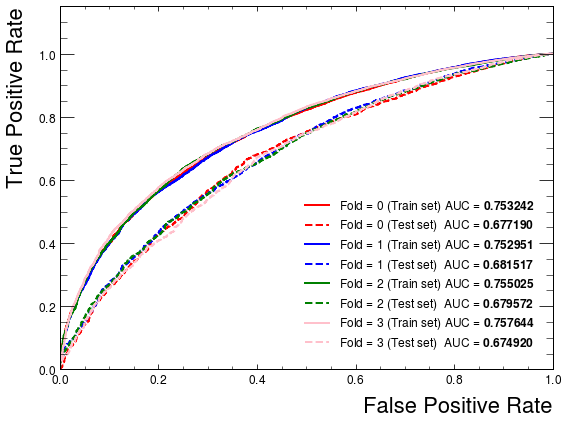

In [37]:

# Create a figure with increased size
plt.figure(figsize=(8,6)) # Increased plot size (you can adjust as needed)

nfolds = 4
colors = ['red','blue','green','pink']
for fold in range(nfolds):
    X_sig_train = df_sig[feature_cols][df_sig['eventNumber']%nfolds != fold]
    X_sig_test = df_sig[feature_cols][df_sig['eventNumber']%nfolds == fold]
    X_bkg_train = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds != fold]
    X_bkg_test = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds == fold]
    
    results_sig_fold_train = models[fold].predict_proba(X_sig_train)[:,1]
    results_bkg_fold_train = models[fold].predict_proba(X_bkg_train)[:,1]
    results_sig_fold_test = models[fold].predict_proba(X_sig_test)[:,1]
    results_bkg_fold_test = models[fold].predict_proba(X_bkg_test)[:,1]

    y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
    scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
    fpr, tpr, thresholds = metrics.roc_curve(y, scores, pos_label=1)
    AUC = metrics.roc_auc_score(y, scores)
    # Bold AUC using LaTeX math mode's \textbf{}
    plt.plot(fpr,tpr,label=F'Fold = {fold} (Train set) AUC = $\\bf{{{AUC:.6f}}}$', color=colors[fold])
    
    y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
    scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
    fpr, tpr, thresholds = metrics.roc_curve(y, scores, pos_label=1)
    AUC = metrics.roc_auc_score(y, scores)
    # Bold AUC using LaTeX math mode's \textbf{}
    plt.plot(fpr,tpr,label=F'Fold = {fold} (Test set)  AUC = $\\bf{{{AUC:.6f}}}$', color=colors[fold], linestyle='--')

plt.legend(fontsize=12) # Consider adjusting legend fontsize too

plt.xlim(0,1)
plt.ylim(0,1.15)
plt.xlabel('False Positive Rate', fontsize=22) # Set xlabel fontsize to 22
plt.ylabel('True Positive Rate', fontsize=22) # Set ylabel fontsize to 22
plt.savefig("auc.pdf")
plt.tight_layout() # Ensure elements fit
plt.show()

Features with Average Importance (Descending):
Feature Name: ph_conversion_type[:,0], Average Importance: 0.2261391580104828
Feature Name: ph_mlph_closest[:,1], Average Importance: 0.09982526954263449
Feature Name: dr_lep_ph1, Average Importance: 0.0683745052665472
Feature Name: ph_eta[:,1], Average Importance: 0.06300494074821472
Feature Name: dr_lep_ph0, Average Importance: 0.05268146190792322
Feature Name: event_nbjets70, Average Importance: 0.044096448458731174
Feature Name: ph_mlph_closest[:,0], Average Importance: 0.04177076416090131
Feature Name: ph_mphb70_closest[:,1], Average Importance: 0.04120528604835272
Feature Name: ph_eta[:,0], Average Importance: 0.04047429282218218
Feature Name: dr_ph, Average Importance: 0.039501559920609
Feature Name: ph_mphb70_closest[:,0], Average Importance: 0.0390129154548049
Feature Name: jet_pt[:,1], Average Importance: 0.037856741808354855
Feature Name: jet_pt[:,0], Average Importance: 0.033852691762149334
Feature Name: met_met, Average Import

<Figure size 864x576 with 0 Axes>

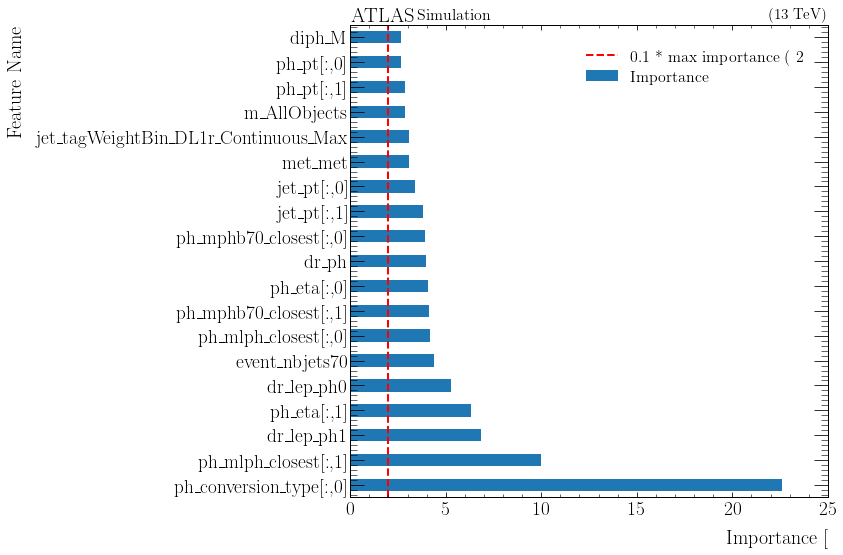

In [51]:
import matplotlib.pyplot as plt
import pandas as pd

def average_feature_importances(models, feature_cols):
  """
  This function calculates the average importance for each feature across all folds/models.

  Args:
      models: A list of XGBoost classifier models.
      feature_cols: A list of feature column names.

  Returns:
      A dictionary containing feature name and its average importance across all folds.
  """
  # Initialize a dictionary to store average importance
  average_importances = {feature: 0.0 for feature in feature_cols}

  # Iterate through each model and accumulate importance for each feature
  for model in models:
    importance_scores = model.feature_importances_  # Access feature importance attribute
    for feature, importance in zip(feature_cols, importance_scores):
      average_importances[feature] += importance

  # Calculate average importance by dividing by the total number of models
  num_models = len(models)
  for feature in average_importances:
    average_importances[feature] /= num_models

  # Sort features by importance in descending order
  sorted_importances = sorted(average_importances.items(), key=lambda x: x[1], reverse=True)
  return sorted_importances

# Assuming models and feature_cols are available (replace with your actual data)
average_importances = average_feature_importances(models, feature_cols)

# Print features with average importance (sorted by descending importance)
print("Features with Average Importance (Descending):")
for feature, importance in average_importances:
  print(f"Feature Name: {feature}, Average Importance: {importance}")

# Create DataFrame from sorted importance and plot as horizontal bar chart
importance_df = pd.DataFrame(average_importances, columns=['Feature', 'Importance'])
importance_df['Importance'] *= 100  # Scale importance to percentage

plt.figure(figsize=(12, 8))
importance_df.set_index('Feature').plot.barh(legend=False, figsize=(12, 8))
plt.xlabel('Importance [%]', fontsize=20)
plt.ylabel('Feature Name', fontsize=20)

# Optional: Add a threshold line (adjust threshold value as needed)
plt.axvline(2.0, color='red', linestyle='--', label='0.1 * max importance (~2%)')
plt.legend()
mplhep.atlas.label(data=False, loc=0)
#plt.savefig(f'Feature_importance_average_Model6_19vars.pdf')

plt.tight_layout()
plt.show()


<Figure size 1800x1440 with 0 Axes>

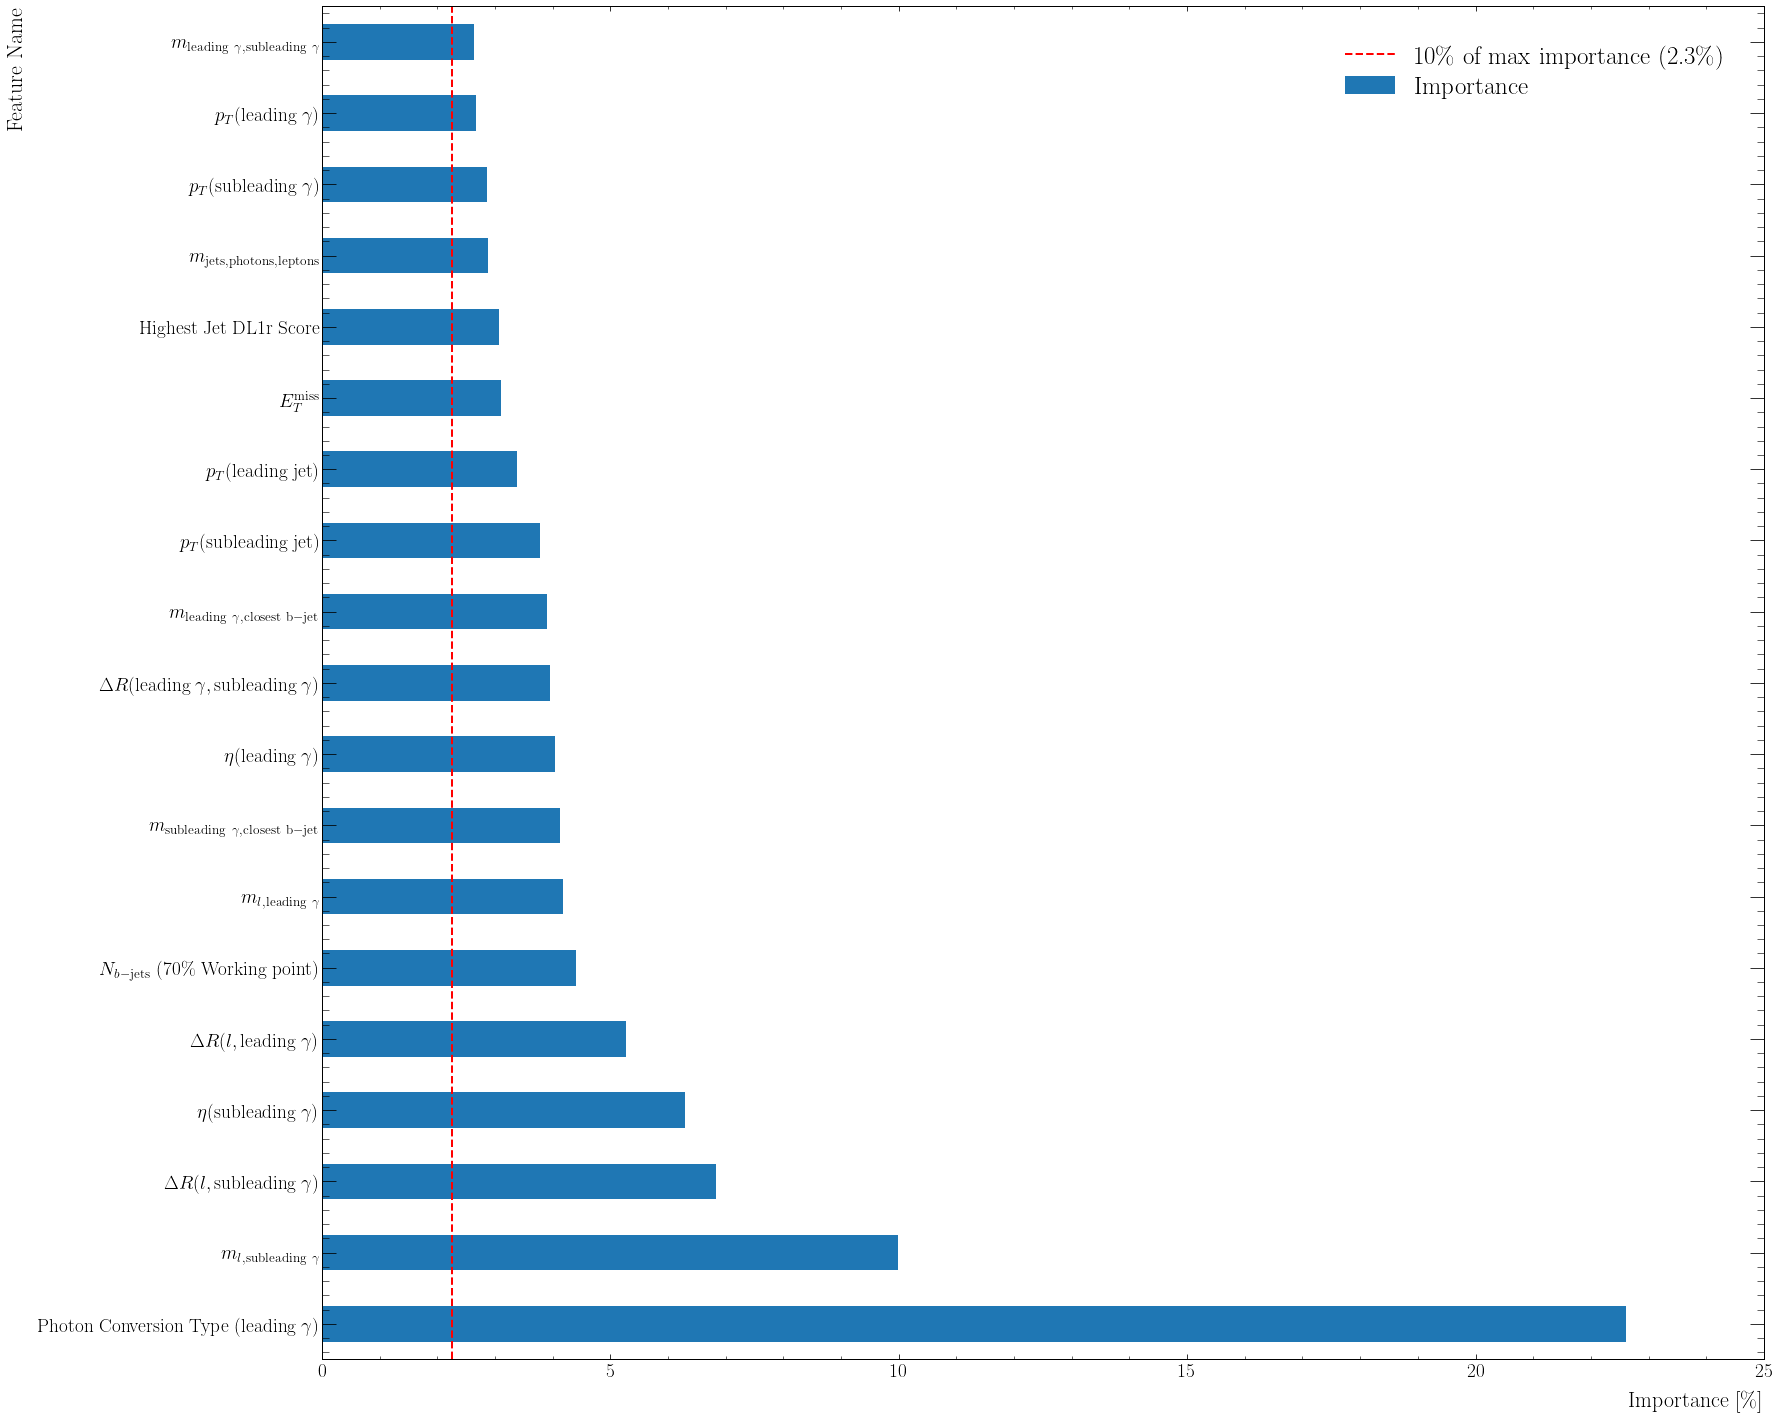

In [76]:
# Name changes in Feature importance


# Set Matplotlib to use LaTeX for text rendering
plt.rcParams.update({
    "text.usetex": True,
    #"font.family": "serif",
    #"font.serif": ["Computer Modern Roman"],
    "font.size": 16 # Adjust overall font size for better readability
})


# --- Mapping Dictionary for Display Names (Physics-Based) ---
"""
feature_display_names = {
    'jet_pt[:,0]': r'$p_T(leading jet)$',
    'jet_pt[:,1]': r'$p_T(subleading jet)$',
    'met_met': r'$E_T^{miss}$',
    'ph_eta[:,0]': r'$\eta(leading \gamma)$',
    'ph_eta[:,1]': r'$\eta(subleading \gamma)$',
    'ph_pt[:,0]': r'$p_T(leading \gamma)$',
    'ph_pt[:,1]': r'$p_T(subleading \gamma)$',
    'ph_mlph_closest[:,0]': r'$m_{l,leading \gamma}$ (closest)',
    'ph_mlph_closest[:,1]': r'$m_{l, subleading \gamma}$ (closest)',
    'diph_M': r'$m_{leading \gamma, subleading \gamma}$',
    'event_nbjets70': r'$N_{b\mathrm{-jets}}$',
    'dr_lep_ph0': r'$\Delta R(l, leading \gamma)$',
    'dr_lep_ph1': r'$\Delta R(l, subleading \gamma)$',
    'ph_conversion_type[:,0]': r'Conversion Type $(leading \gamma)$',
    'ph_mphb70_closest[:,0]': r'$m_{leading \gamma, b}$ (70 GeV closest)',
    'ph_mphb70_closest[:,1]': r'$m_{subleading \gamma, b}$ (70 GeV closest)',
    'm_AllObjects': r'$m_{all objects}$',
    'jet_tagWeightBin_DL1r_Continuous_Max': r'Max Jet DL1r Score',
    'dr_ph': r'$\Delta R(leading \gamma, subleading \gamma)$',
}
"""

feature_display_names = {
    'jet_pt[:,0]': r'$p_T(\mathrm{leading~jet})$',
    'jet_pt[:,1]': r'$p_T(\mathrm{subleading~jet})$',
    'met_met': r'$E_T^{\mathrm{miss}}$', # Corrected to \mathrm{miss}
    'ph_eta[:,0]': r'$\eta(\mathrm{leading~}\gamma)$',
    'ph_eta[:,1]': r'$\eta(\mathrm{subleading~}\gamma)$',
    'ph_pt[:,0]': r'$p_T(\mathrm{leading~}\gamma)$',
    'ph_pt[:,1]': r'$p_T(\mathrm{subleading~}\gamma)$',
    'ph_mlph_closest[:,0]': r'$m_{l,\mathrm{leading}~\gamma}$',
    'ph_mlph_closest[:,1]': r'$m_{l, \mathrm{subleading}~\gamma}$',
    'diph_M': r'$m_{\mathrm{leading}~\gamma, \mathrm{subleading}~\gamma}$',
    'event_nbjets70': r'$N_{b\mathrm{-jets}}$ ($\mathrm{70\%~Working~point}$)',
    'dr_lep_ph0': r'$\Delta R(l, \mathrm{leading}~\gamma)$',
    'dr_lep_ph1': r'$\Delta R(l, \mathrm{subleading}~\gamma)$',
    # 'Conversion Type' is outside math mode. 'leading gamma' inside uses \mathrm{}
    'ph_conversion_type[:,0]': r'Photon Conversion Type $(\mathrm{leading~}\gamma)$',
    'ph_mphb70_closest[:,0]': r'$m_{\mathrm{leading}~\gamma, \mathrm{closest~b-jet}}$',
    'ph_mphb70_closest[:,1]': r'$m_{\mathrm{subleading}~\gamma, \mathrm{closest~b-jet}}$',
    'm_AllObjects': r'$m_{\mathrm{jets,photons,leptons}}$',
    # This is pure text, no math mode here, so no \mathrm{} needed
    'jet_tagWeightBin_DL1r_Continuous_Max': r'Highest Jet DL1r Score',
    'dr_ph': r'$\Delta R(\mathrm{leading}~\gamma, \mathrm{subleading}~\gamma)$',
}

# --- Function to Calculate Average Feature Importances ---
def average_feature_importances(models, feature_cols):
    """
    Calculates the average importance for each feature across all folds/models.

    Args:
        models: A list of trained XGBoost classifier models.
        feature_cols: A list of feature column names, in the exact order used during training.

    Returns:
        A list of tuples (feature_name, average_importance) sorted by importance.
    """
    average_importances = {feature: 0.0 for feature in feature_cols}
    num_models = len(models)

    for model in models:
        importance_scores = model.feature_importances_
        for feature, importance in zip(feature_cols, importance_scores):
            average_importances[feature] += importance

    for feature in average_importances:
        average_importances[feature] /= num_models

    sorted_importances = sorted(average_importances.items(), key=lambda x: x[1], reverse=True)
    return sorted_importances


# --- YOUR ACTUAL MODELS LIST GOES HERE ---
# Populate this 'models' list with your trained XGBoostClassifier objects.
# For example:
# import joblib
# models = [joblib.load('path/to/your/model_fold_0.pkl'),
#           joblib.load('path/to/your/model_fold_1.pkl'),
#           # ... and so on for all your trained models
#          ]
#models = [] # <--- REPLACE THIS LINE WITH YOUR ACTUAL LIST OF TRAINED MODELS

# --- Calculate and Plot Feature Importances ---

# Calculate average importances across all models
average_importances = average_feature_importances(models, feature_cols)

# Apply the renaming for plotting
display_importances = [
    (feature_display_names.get(original_feature, original_feature), importance)
    for original_feature, importance in average_importances
]

# Create DataFrame for plotting from the renamed importances
importance_df = pd.DataFrame(display_importances, columns=['Feature', 'Importance'])
importance_df['Importance'] *= 100  # Scale importance to percentage

# Plotting
plt.figure(figsize=(25, 20))
ax = importance_df.set_index('Feature').plot.barh(legend=False, figsize=(25, 20))

plt.xlabel('Importance [\%]', fontsize=22)
plt.ylabel('Feature Name', fontsize=22)
#plt.title('BDT Feature Importances (Averaged over Folds)', fontsize=22) # Standard title instead of mplhep label

# Optional: Add a threshold line (10% of the max importance)
max_importance_percentage = importance_df['Importance'].max()
threshold_value = 0.1 * max_importance_percentage
plt.axvline(threshold_value, color='red', linestyle='--', label=f'10\% of max importance ({threshold_value:.1f}\%)')
plt.legend(fontsize=25)

plt.savefig(f'Feature_importance_average_Model6_19vars_renamed.pdf')
plt.tight_layout()
plt.show()

In [105]:
for i, model in enumerate(models):
    # Assuming model[0] has the feature importance scores
    feature_importances = models[i].feature_importances_

    # Create a list of tuples with feature name and importance
    feature_imp_list = zip(feature_cols, feature_importances)
    print(feature_imp_list) 
    # Sort the list based on importance in ascending order (key=lambda x: x[1])
    sorted_features = sorted(feature_imp_list, key=lambda x: x[1])
    print(f'for model: {i}')
    # Print the sorted features
    for feature, importance in sorted_features:
        print(f"Feature Name: {feature}, Importance: {importance}")
        
    print(F"No. of features: {len(sorted_features)}")

for model: 0
Feature Name: diph_M, Importance: 0.020778506994247437
Feature Name: m_AllObjects, Importance: 0.02209719642996788
Feature Name: ph_pt[:,0], Importance: 0.022784927859902382
Feature Name: ph_mlph_closest[:,0], Importance: 0.023761354386806488
Feature Name: jet_pt[:,0], Importance: 0.025089861825108528
Feature Name: ph_pt[:,1], Importance: 0.02620004117488861
Feature Name: met_met, Importance: 0.026568641886115074
Feature Name: jet_DL1r_bjetscore, Importance: 0.026715319603681564
Feature Name: ph_mphb70_closest[:,1], Importance: 0.027384640648961067
Feature Name: ph_eta[:,0], Importance: 0.030024560168385506
Feature Name: ph_mphb70_closest[:,0], Importance: 0.030101966112852097
Feature Name: jet_pt[:,1], Importance: 0.03012244589626789
Feature Name: dr_ph, Importance: 0.03096022829413414
Feature Name: ph_eta[:,1], Importance: 0.04277438297867775
Feature Name: dr_lep_ph0, Importance: 0.04580411687493324
Feature Name: ph_mlph_closest[:,1], Importance: 0.051252223551273346
Fea

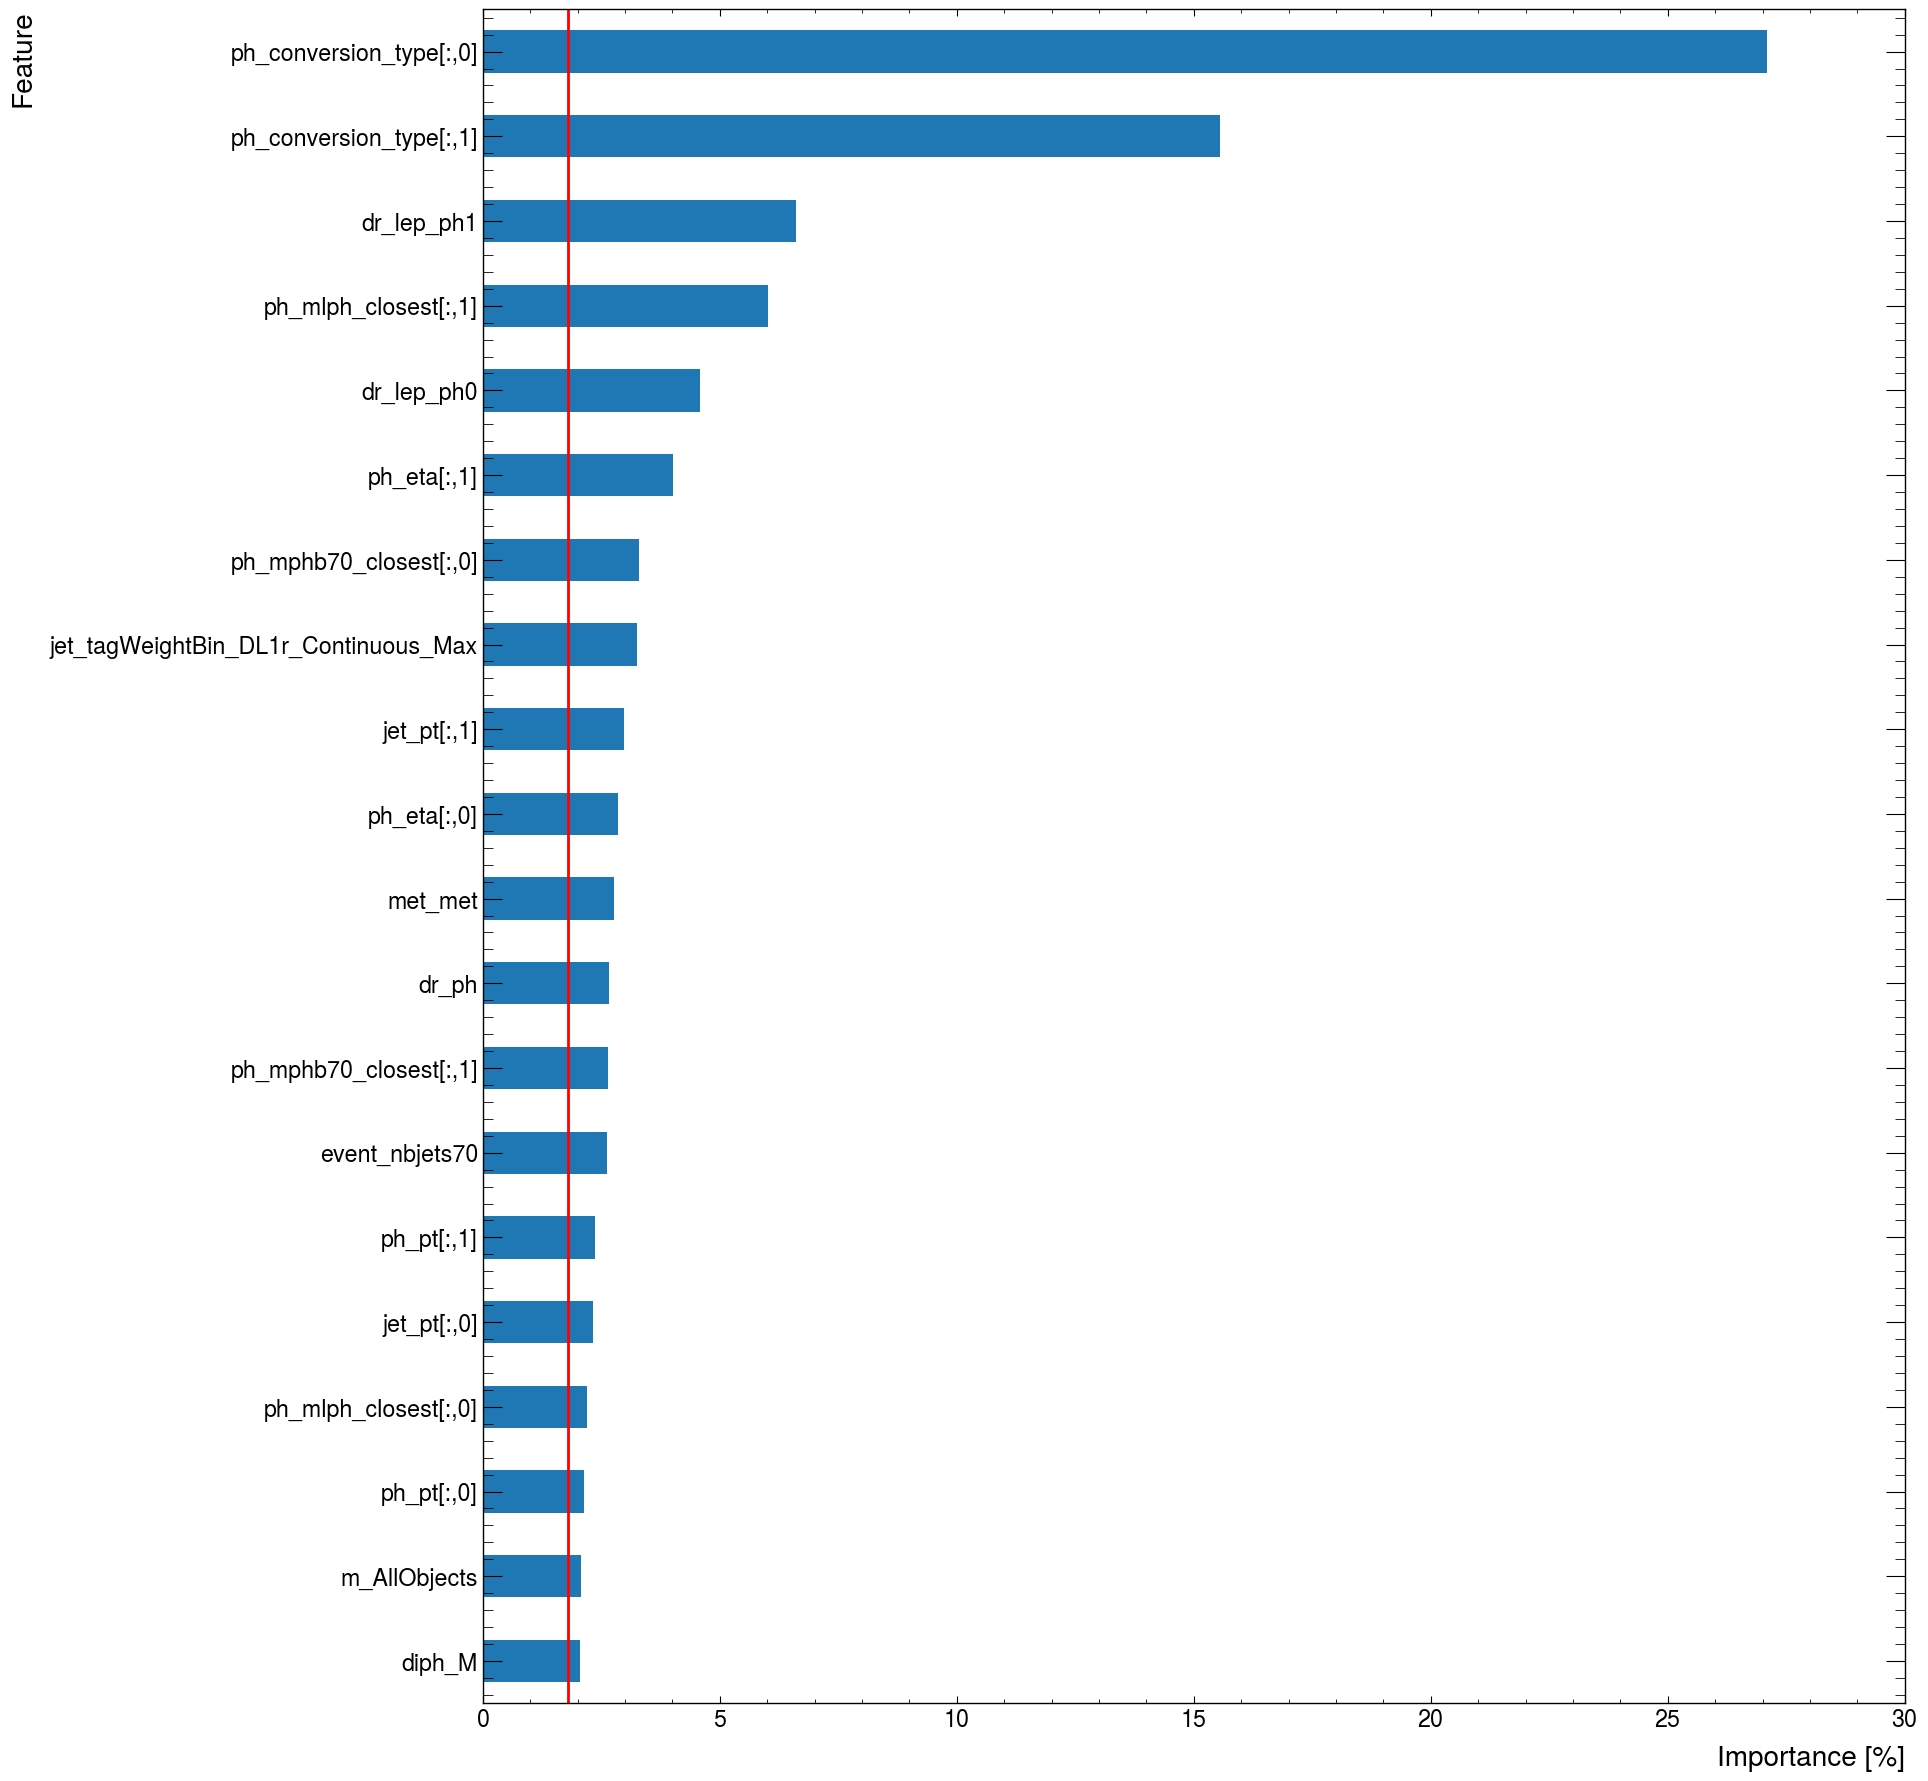

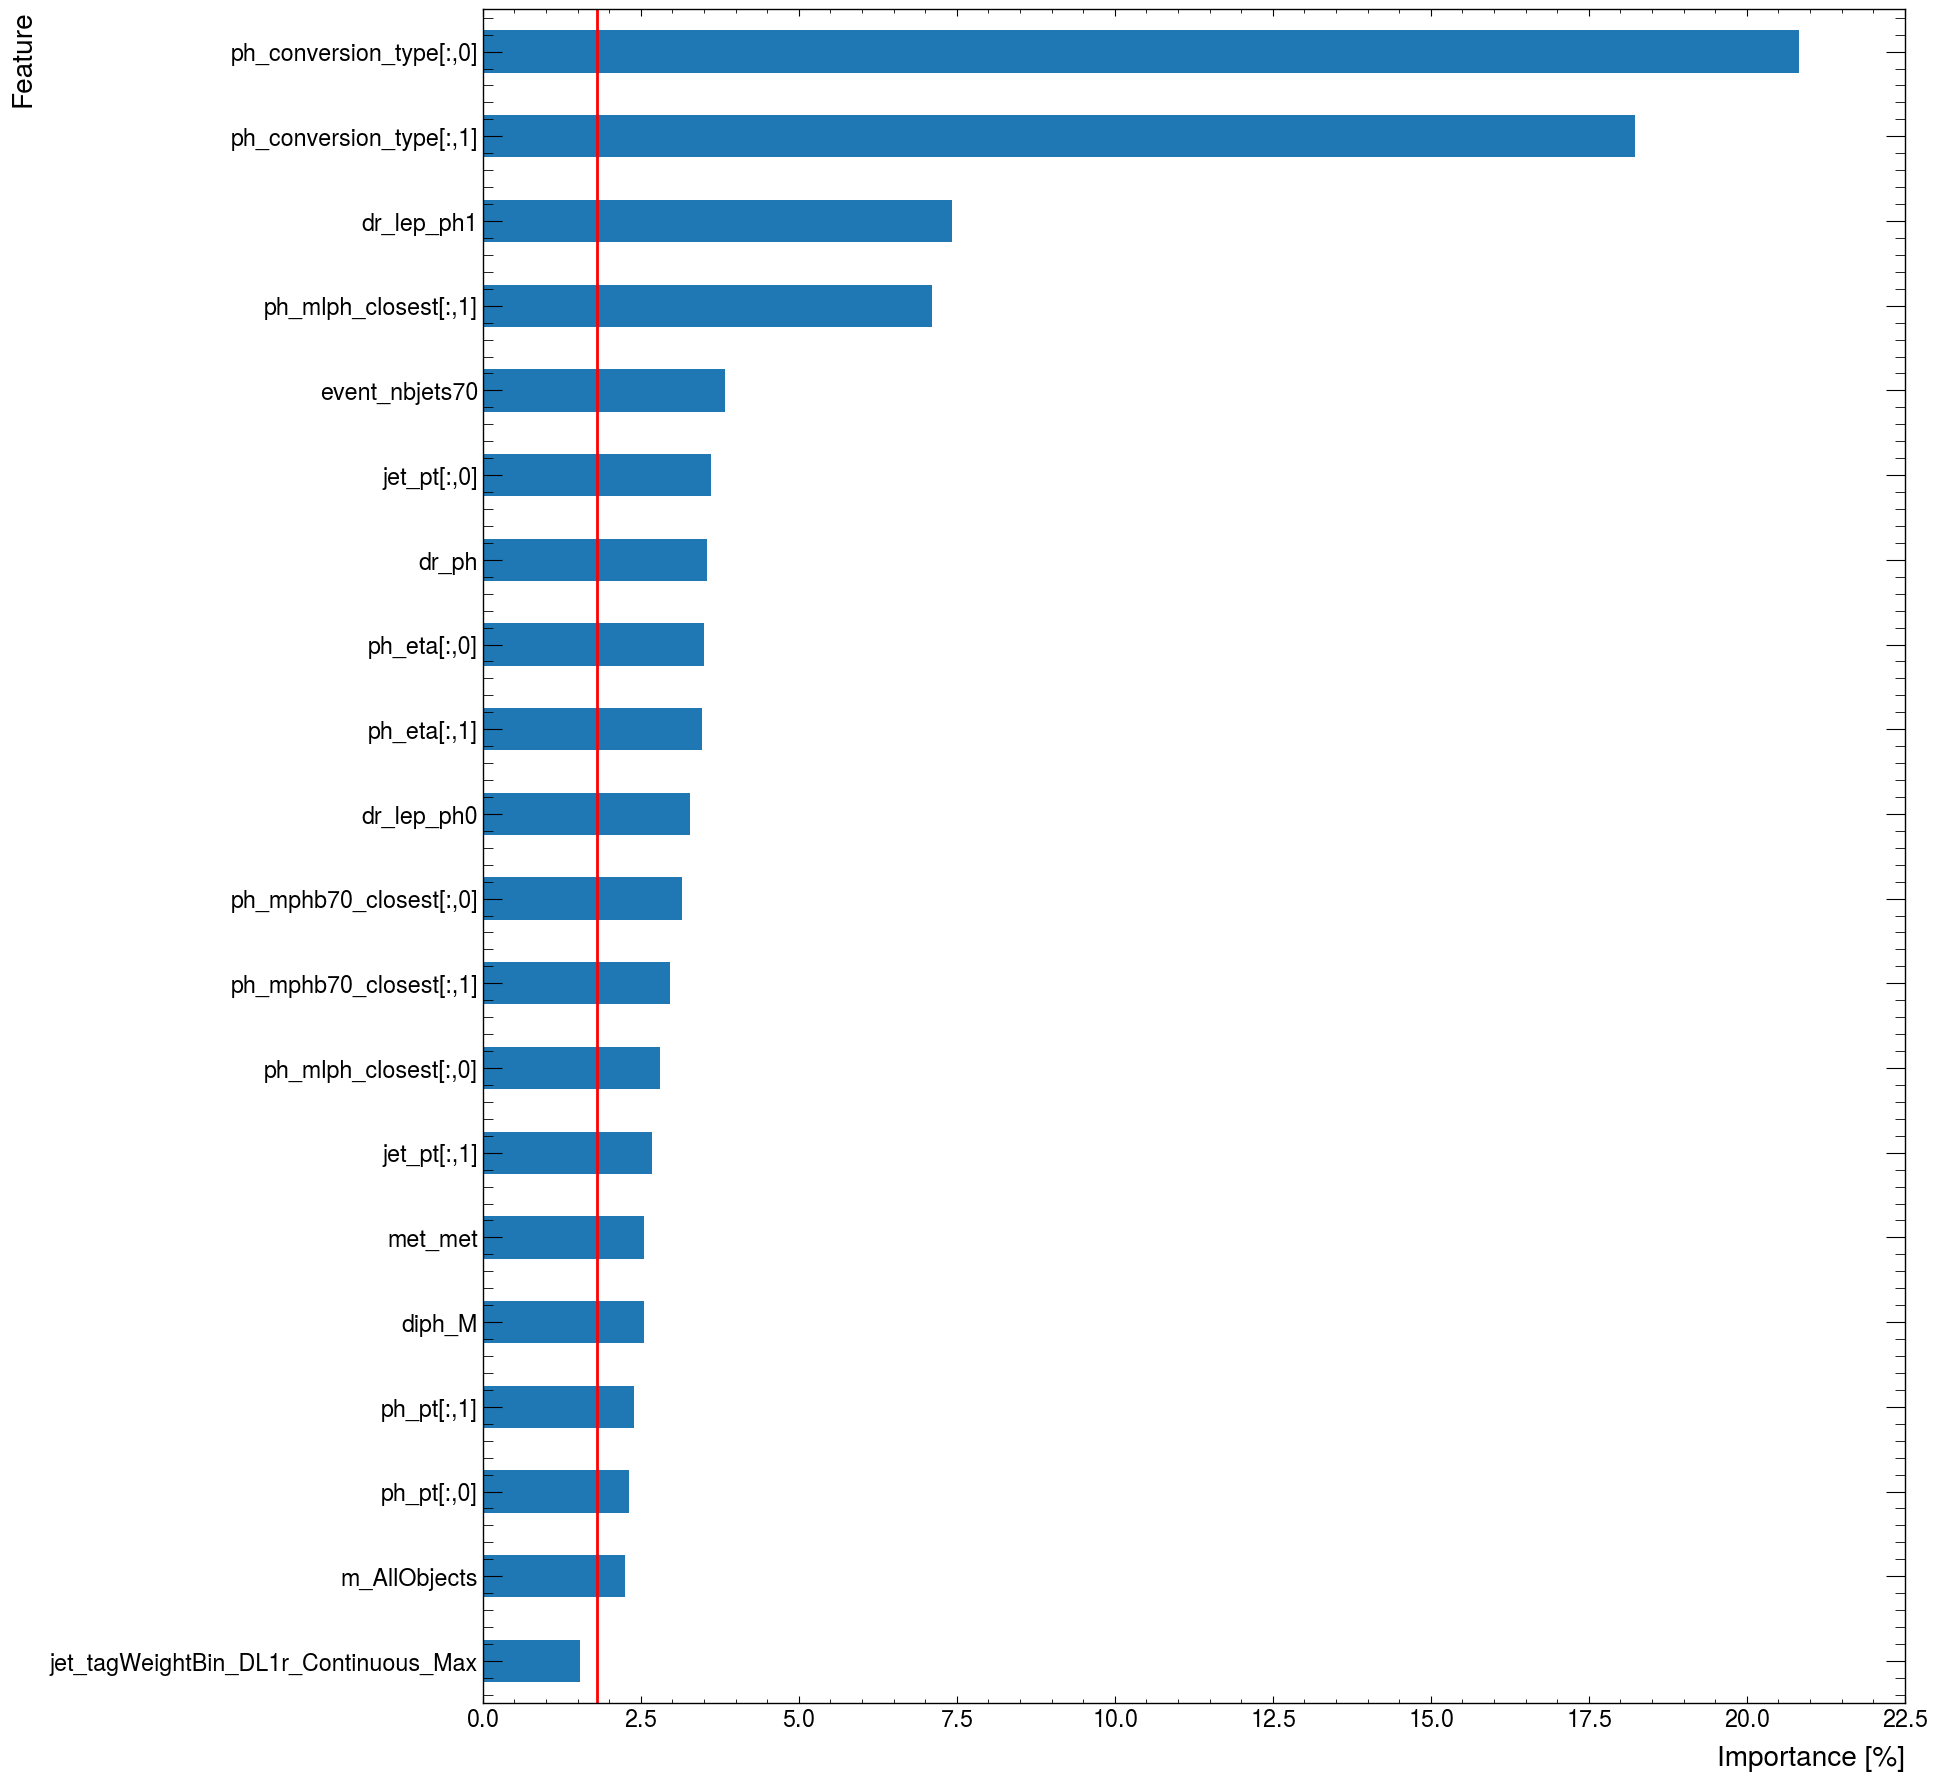

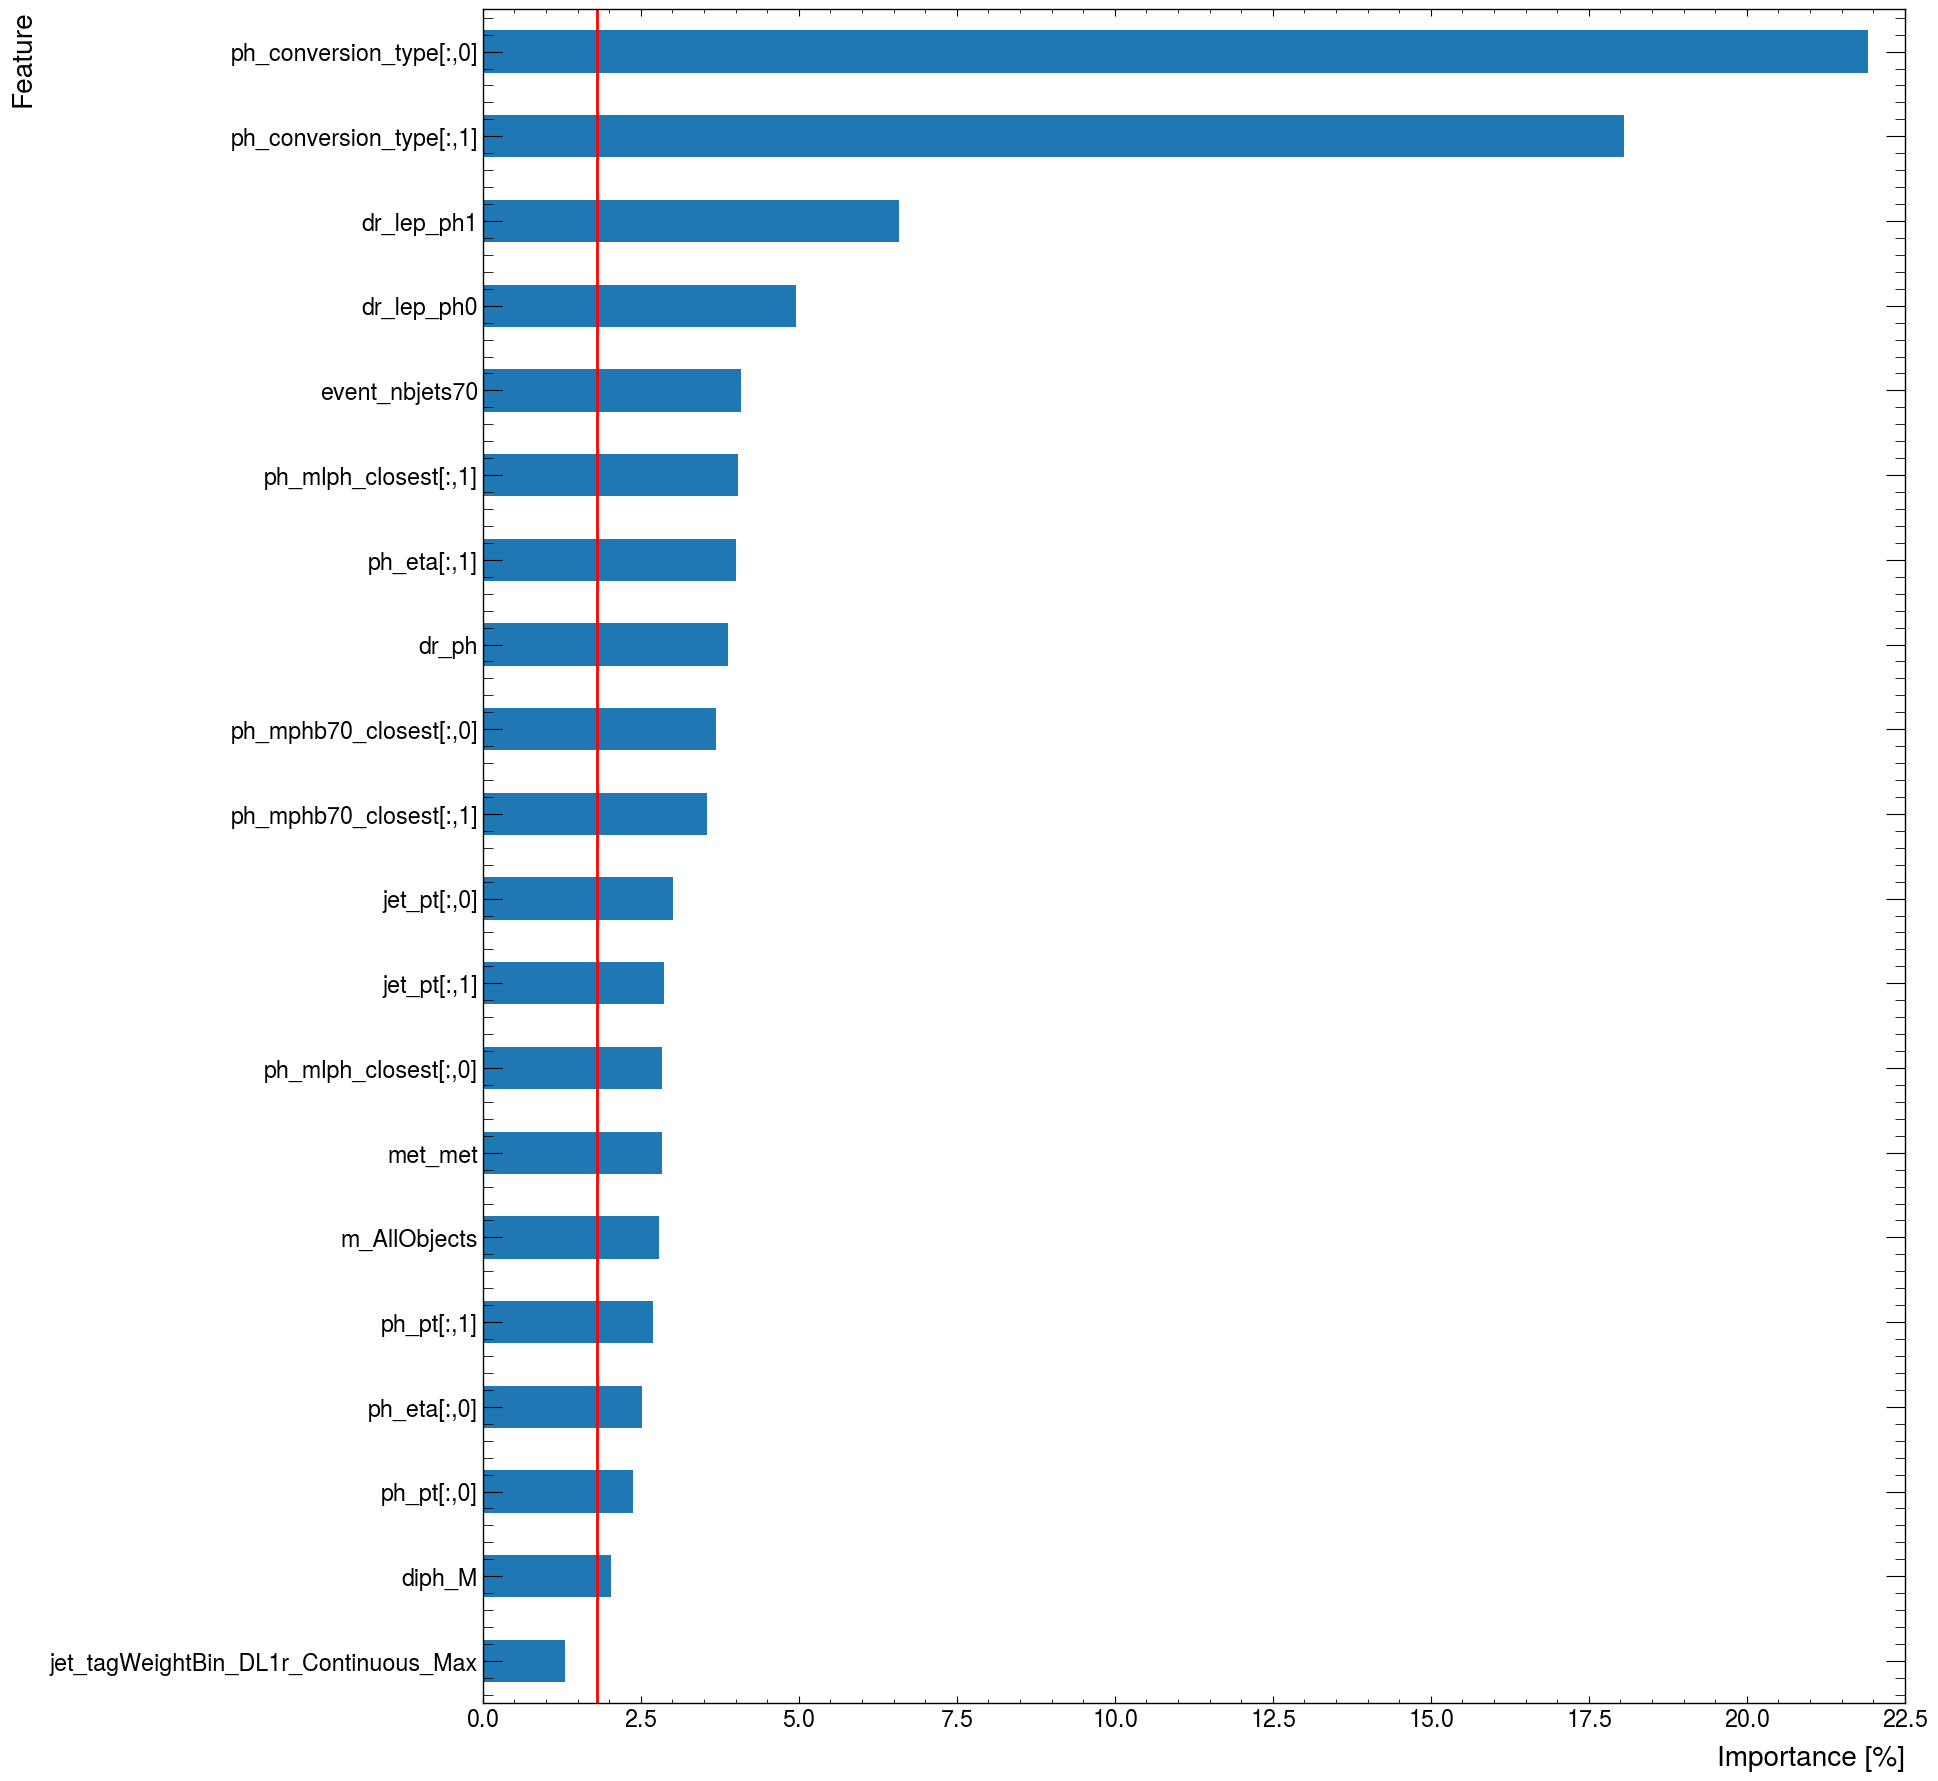

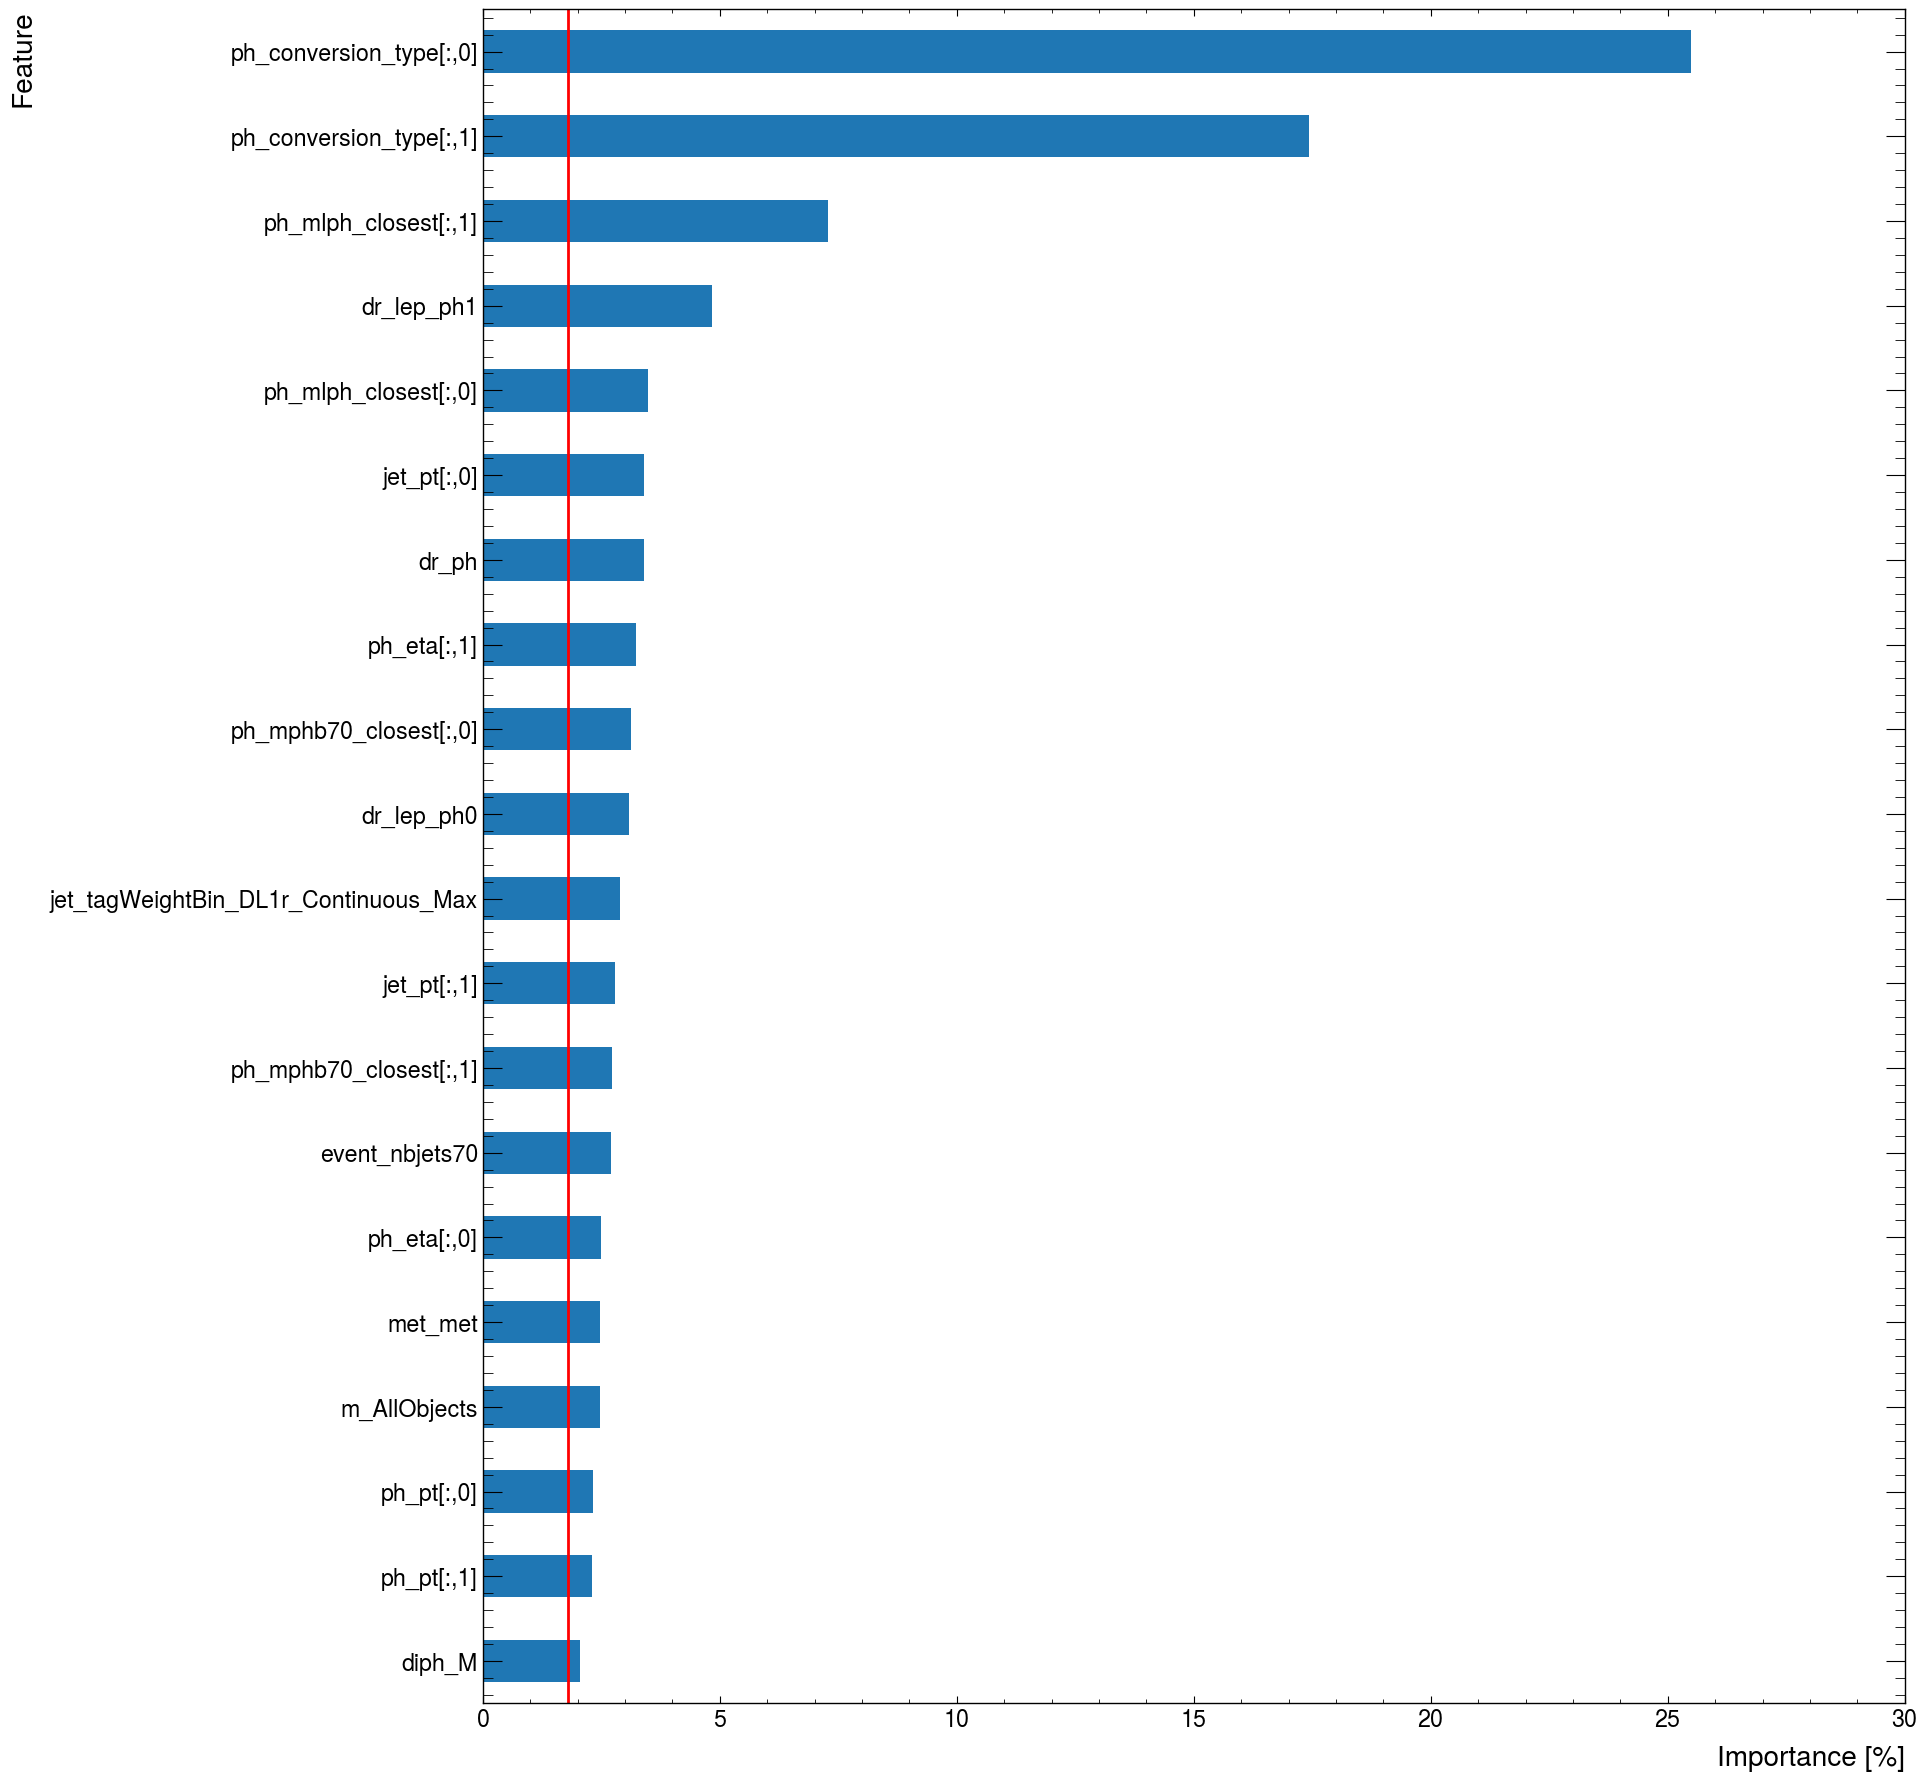

In [37]:
for fold in range(4):
    feature_importances = models[fold].feature_importances_
    feature_imp_list = zip(feature_cols, feature_importances)

    sorted_features = sorted(feature_imp_list, key=lambda x: x[1])
    df = pd.DataFrame(sorted_features, columns = ['Feature','Importance'])
    df['Importance'] = df['Importance'] * 100
    df.set_index('Feature').plot.barh(legend=False, figsize=(18,22))
    plt.xlabel('Importance [%]')
    plt.axvline(1.8,color='red')
   

In [26]:
# Define the custom formatter function
def custom_formatter(x, pos):
    return f'{x * 0.1:.1f}'

-----------------------------------------------
0.005032221013390708 1.919779404681463
0.005519536961499228 1.8754722039899063
11 10 10
Signal train histogram: [0.00503222 0.23725671 0.78106863 1.25727035 1.594384   1.8587518
 1.9197794  1.59999118 0.70817425 0.03829146]
Signal test histogram: [0.00551954 0.2195419  0.75032195 1.25093464 1.56612007 1.81633221
 1.8754722  1.60683772 0.85486719 0.05405213]
Background train histogram: [0.0369382  0.78929252 1.61554299 1.86490612 1.84646167 1.60886924
 1.35163077 0.68206922 0.20084137 0.00344805]
Background test histogram: [0.09723606 0.82970188 1.60469354 1.62322133 2.00811343 1.33575914
 1.50451175 0.72618374 0.27057901 0.1       ]
-----------------------------------------------

Signal train errors: [0.00146232 0.01002918 0.0181896  0.02305173 0.02598022 0.02802661
 0.02847928 0.02587675 0.01717112 0.00398309]
Signal test errors: [0.00085125 0.00558399 0.01030901 0.01333556 0.01490659 0.01600793
 0.01623895 0.0149904  0.01087793 0.00272

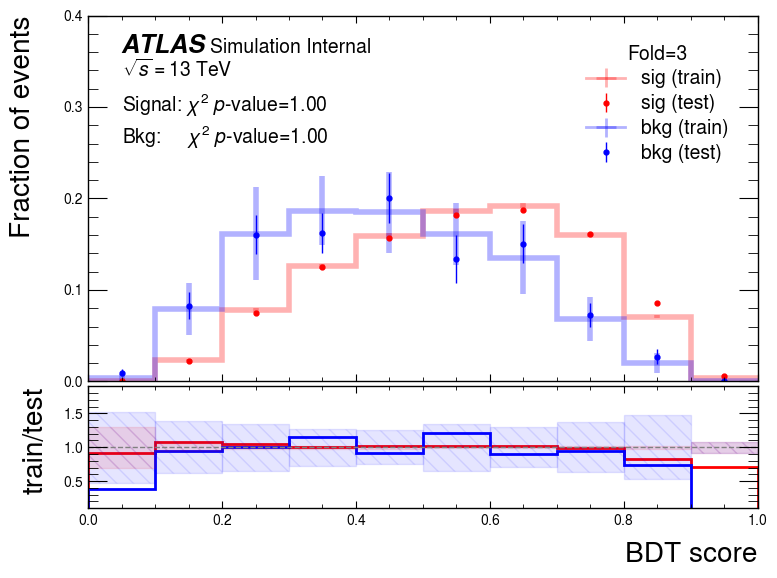

In [43]:
# Working code - Per fold. Change no. of folds
# Unweighted  - with corrected Sumw2()
# Normalized with auc
folds = 4
fold = 3
fig, axes = plt.subplots(nrows=2,ncols=1,gridspec_kw={'height_ratios': [3, 1]}, sharex=True)


# Example dummy data and plots:
results_sig_fold_test = results_sig[df_sig['eventNumber']%folds == fold]
results_bkg_fold_test = results_bkg[df_bkg['eventNumber']%folds == fold]
weights_sig_fold_test = df_sig['weight'][df_sig['eventNumber']%folds == fold]
weights_bkg_fold_test = df_bkg['weight'][df_bkg['eventNumber']%folds == fold]
y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
weights = np.concatenate([weights_sig_fold_test,weights_bkg_fold_test])

results_sig_fold_train = results_sig[df_sig['eventNumber']%folds != fold]
results_bkg_fold_train = results_bkg[df_bkg['eventNumber']%folds != fold]
weights_sig_fold_train = df_sig['weight'][df_sig['eventNumber']%folds != fold]
weights_bkg_fold_train = df_bkg['weight'][df_bkg['eventNumber']%folds != fold]
y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
weights = np.concatenate([weights_sig_fold_train,weights_bkg_fold_train])

"""
bc, bb = np.histogram(data1, weights=weights1, range=(-3,3), bins=10)
sumW2, bb = np.histogram(data1, weights=weights1**2, range=(-3,3), bins=10)
mplhep.histplot(bc,bb,yerr=np.sqrt(sumW2),density=True,label='10000 events, weight=0.1', histtype='errorbar')
"""
#bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, bins=np.linspace(0,1,11), density=True)


bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, range=(0,1), bins=10, density=True)
total_sig_train = len(results_sig_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train**2, range=(0,1), bins=10)
mplhep.histplot(bc_sig_train,bb,yerr=np.sqrt(sumW2), density=True, label='sig (train)', histtype='step', ax=axes[0], color='red', alpha=0.3, linewidth=4)
bc_sig_train_e = np.sqrt(sumW2)

bc_sig_test, bb = np.histogram(results_sig_fold_test,  weights=weights_sig_fold_test, range=(0,1), bins=10, density=True)
total_sig_test = len(results_sig_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_sig_fold_test, weights=weights_sig_fold_test**2, range=(0,1), bins=10)
mplhep.histplot(bc_sig_test,bb,yerr=np.sqrt(sumW2),density=True, label='sig (test)', histtype='errorbar', ax=axes[0], color='red', markersize=7)
bc_sig_test_e = np.sqrt(sumW2)

bc_bkg_train, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train, range=(0,1), bins=10, density=True)
total_bkg_train = len(results_bkg_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train**2, range=(0,1), bins=10)
mplhep.histplot(bc_bkg_train,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (train)', histtype='step', ax=axes[0], color='blue', alpha=0.3, linewidth=4)
bc_bkg_train_e = np.sqrt(sumW2)


bc_bkg_test, bb = np.histogram(results_bkg_fold_test,  weights=weights_bkg_fold_test, range=(0,1), bins=10, density=True)
total_bkg_test = len(results_bkg_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_bkg_fold_test, weights=weights_bkg_fold_test**2, range=(0,1), bins=10)
mplhep.histplot(bc_bkg_test,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (test)', histtype='errorbar', ax=axes[0], color='blue', markersize=7)
bc_bkg_test_e = np.sqrt(sumW2)




print("-----------------------------------------------")
# Example check if data is within expected range
print(bc_sig_train.min(), bc_sig_train.max())
print(bc_sig_test.min(), bc_sig_test.max())

print(len(bb), len(bc_sig_train), len(bc_bkg_train))
bc_bkg_test = np.where(bc_bkg_test == 0, 1e-1, bc_bkg_test)


corr_factor_sig = np.sum(bc_sig_train)/np.sum(bc_sig_test)
chi2_sig, p_sig = chisquare(bc_sig_train, bc_sig_test*corr_factor_sig)
corr_factor_bkg = np.sum(bc_bkg_train)/np.sum(bc_bkg_test)
chi2_bkg, p_bkg = chisquare(bc_bkg_train, bc_bkg_test*corr_factor_bkg)


axes[0].set_xlim(0,1)
axes[0].set_ylim(0,4)

#scale_and_format_y_axis(axes[0], scale_factor=0.1)  # Adjust scale_factor as needed

# Create the FuncFormatter object
formatter = mtick.FuncFormatter(custom_formatter)

# Apply the custom formatter to the y-axis
axes[0].yaxis.set_major_formatter(formatter)
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(1))   # removing this will lead to duplicate labels


axes[0].legend(title=F'Fold={fold}', loc='upper right')

#ax.set_xlabel('BDT score')
axes[0].set_ylabel('Fraction of events', labelpad=20)
mplhep.atlas.label('Internal', data=False, ax=axes[0])
axes[0].text(x=0.05, y=2.6,s=F'Signal: $\chi^2$ $p$-value={p_sig:.2f}\nBkg:     $\chi^2$ $p$-value={p_bkg:.2f}')
axes[0].tick_params(axis='both', labelsize=10)

print("Signal train histogram:", bc_sig_train)
print("Signal test histogram:", bc_sig_test)
print("Background train histogram:", bc_bkg_train)
print("Background test histogram:", bc_bkg_test)

print("-----------------------------------------------")




#y1 = bc_sig_train
#y1err = np.sqrt(sumW2) # calculated from sig train
#y2 = bc_sig_test
#y2err = np.sqrt(sumW2) # calculated from sig test






# Errors on histograms:
#bc_sig_train_e = np.sqrt(bc_sig_train/total_sig_train)*10  #np.sqrt(bc_sig_train)
#bc_sig_test_e = np.sqrt(bc_sig_test/total_sig_test)*10  #np.sqrt(bc_sig_test)
#bc_bkg_train_e = np.sqrt(bc_bkg_train/total_bkg_train)*10  #np.sqrt(bc_bkg_train)
#bc_bkg_test_e = np.sqrt(bc_bkg_test/total_bkg_test)*10  #np.sqrt(bc_bkg_test)





print("\nSignal train errors:", bc_sig_train_e)
print("Signal test errors:", bc_sig_test_e)
print("Background train errors:", bc_bkg_train_e)
print("Background test errors:", bc_bkg_test_e)

print("-----------------------------------------------")

ratio_sig = np.where(bc_sig_test == 0, 1, bc_sig_train / bc_sig_test)
ratio_bkg = np.where(bc_bkg_test == 0, 1, bc_bkg_train / bc_bkg_test)


print("\nSig ratio: ", ratio_sig)
print("Bkg ratio: ", ratio_bkg)


ratio_sig_e = np.sqrt((bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*(bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*bc_sig_test_e*bc_sig_test_e+(1/(1.0*bc_sig_test))*(1/(1.0*bc_sig_test))*bc_sig_train_e*bc_sig_train_e)
ratio_bkg_e = np.sqrt((bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*(bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*bc_bkg_test_e*bc_bkg_test_e+(1/(1.0*bc_bkg_test))*(1/(1.0*bc_bkg_test))*bc_bkg_train_e*bc_bkg_train_e)

print("\nSig Ratio uncertainties per bin: ", ratio_sig_e)



# Ratio plot
#ratio_sig = bc_sig_train/bc_sig_test # np.divide(bc_sig_train, bc_sig_test, out=np.zeros_like(bc_sig_train), where=bc_sig_test != 0)
#ratio_bkg = bc_bkg_train/bc_bkg_test #  np.divide(bc_bkg_train, bc_bkg_test, out=np.zeros_like(bc_bkg_train), where=bc_bkg_test != 0)
#print(bb)
#print(ratio_sig)
#print(ratio_bkg)
#print(len(bb), len(ratio_sig), len(ratio_bkg))

# Clip errors and add padding
max_error = 100  # Example maximum error threshold
clipped_errors_sig = np.clip(ratio_sig_e, 0, max_error)
clipped_errors_bkg = np.clip(ratio_bkg_e, 0, max_error)

print("Clipped errors:", clipped_errors_sig)
print("Clipped errors:", clipped_errors_bkg)




bb_centers = (bb[:-1] + bb[1:]) / 2
#axes[1].plot(bb_centers, ratio_sig, 'o', label='Sig', color='red', linestyle='None', markersize=5)
#axes[1].plot(bb_centers, ratio_bkg, 'o', label='Bkg', color='blue', linestyle='None', markersize=5)
#axes[1].axhline(1,0,1,linestyle='--',color='grey')

mplhep.histplot(ratio_sig, bb, histtype='step', ax=axes[1], color='red', linewidth=2)
mplhep.histplot(ratio_bkg, bb, histtype='step', ax=axes[1], color='blue', linewidth=2)


# Plot with clipped errors
#axes[1].fill_between(bb_centers, y1=(ratio_sig + clipped_errors_sig), y2=(ratio_sig - clipped_errors_sig), alpha=0.2, color='red')
#axes[1].fill_between(bb_centers, y1=(ratio_bkg + clipped_errors_bkg), y2=(ratio_bkg - clipped_errors_bkg), alpha=0.2, color='blue')

#axes[1].fill_between(bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), alpha=0.2, color='red', hatch='\\\\', zorder=1) 
#axes[1].fill_between(bb_centers, y1=(1 + clipped_errors_bkg), y2=(1 - clipped_errors_bkg), alpha=0.2, color='blue', hatch='/', zorder=1) 


# Plot the ratio uncertainty bands with hatch styles
#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), facecolor='none', edgecolor='red', hatch='\\\\', zorder=1, linewidth=0.0)
#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_bkg), y2=(1 - clipped_errors_bkg), facecolor='none', edgecolor='#CCCCFF', hatch='///', zorder=1, linewidth=0.0)


#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), facecolor='red', alpha=0.2, edgecolor='red', hatch='\\\\', zorder=1)

bin_width = bb[1] - bb[0] 
# Plot the uncertainty band in histogram style using bar
for center, err in zip(bb_centers, clipped_errors_sig):
    axes[1].bar(center, 2 * err, width=bin_width, bottom=1 - err, color='red', alpha=0.1, edgecolor='red', hatch='\\\\', align='center')
for center, err in zip(bb_centers, clipped_errors_bkg):
    axes[1].bar(center, 2 * err, width=bin_width, bottom=1 - err, color='blue', alpha=0.1, edgecolor='blue', hatch='\\\\', align='center')


#axes[1].set_dashes((5,2))

axes[1].axhline(1,0,1,linestyle='--',color='grey', linewidth=1)
axes[1].set_ylabel('train/test')
axes[1].set_xlabel('BDT score')
axes[1].tick_params(axis='both', labelsize=10)

axes[1].set_ylim(0.1,1.9)  # Adjust based on your ratio values
fig.tight_layout()
fig.subplots_adjust(hspace=0.02)
fig.savefig(f'Test_Train_Chi_Squared_Unweighted_{fold}_Model6_10bins_19vars.png')

-----------------------------------------------
0.005379851665305511 1.909546600248946
0.004475741891343253 1.906081738930576
11 10 10
Signal train histogram: [0.00537985 0.23601135 0.76173408 1.24727044 1.5786057  1.83626908
 1.9095466  1.61806662 0.76385876 0.04325762]
Signal test histogram: [0.00447574 0.22321912 0.80836163 1.28099026 1.61347211 1.88379666
 1.90608174 1.55249237 0.687936   0.03917501]
Background train histogram: [0.05885087 0.75553709 1.63712151 1.6418503  1.88029836 1.58302763
 1.46019926 0.72809339 0.25170392 0.00331706]
Background test histogram: [0.02901654 0.95239614 1.5282383  2.36679576 1.91182416 1.38952989
 1.14724459 0.57199834 0.10295643 0.1       ]
-----------------------------------------------

Signal train errors: [0.00147496 0.0100203  0.01798738 0.02299682 0.02590668 0.02786792
 0.02840388 0.02605057 0.01782708 0.00422843]
Signal test errors: [0.00082916 0.00559992 0.01065793 0.01343003 0.01503402 0.01628261
 0.01637048 0.01468626 0.00976584 0.00232

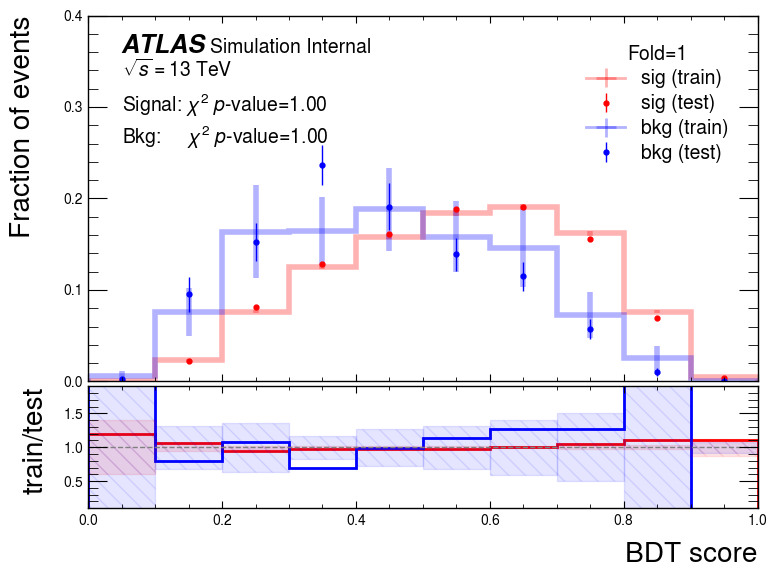

In [35]:
# Working code - Per fold. Change no. of folds
# Unweighted  - with corrected Sumw2()
# Normalized with auc
folds = 4
fold = 1
fig, axes = plt.subplots(nrows=2,ncols=1,gridspec_kw={'height_ratios': [3, 1]}, sharex=True)


# Example dummy data and plots:
results_sig_fold_test = results_sig[df_sig['eventNumber']%folds == fold]
results_bkg_fold_test = results_bkg[df_bkg['eventNumber']%folds == fold]
weights_sig_fold_test = df_sig['weight'][df_sig['eventNumber']%folds == fold]
weights_bkg_fold_test = df_bkg['weight'][df_bkg['eventNumber']%folds == fold]
y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
weights = np.concatenate([weights_sig_fold_test,weights_bkg_fold_test])

results_sig_fold_train = results_sig[df_sig['eventNumber']%folds != fold]
results_bkg_fold_train = results_bkg[df_bkg['eventNumber']%folds != fold]
weights_sig_fold_train = df_sig['weight'][df_sig['eventNumber']%folds != fold]
weights_bkg_fold_train = df_bkg['weight'][df_bkg['eventNumber']%folds != fold]
y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
weights = np.concatenate([weights_sig_fold_train,weights_bkg_fold_train])

"""
bc, bb = np.histogram(data1, weights=weights1, range=(-3,3), bins=10)
sumW2, bb = np.histogram(data1, weights=weights1**2, range=(-3,3), bins=10)
mplhep.histplot(bc,bb,yerr=np.sqrt(sumW2),density=True,label='10000 events, weight=0.1', histtype='errorbar')
"""
#bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, bins=np.linspace(0,1,11), density=True)


bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, range=(0,1), bins=10, density=True)
total_sig_train = len(results_sig_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train**2, range=(0,1), bins=10)
mplhep.histplot(bc_sig_train,bb,yerr=np.sqrt(sumW2), density=True, label='sig (train)', histtype='step', ax=axes[0], color='red', alpha=0.3, linewidth=4)
bc_sig_train_e = np.sqrt(sumW2)

bc_sig_test, bb = np.histogram(results_sig_fold_test,  weights=weights_sig_fold_test, range=(0,1), bins=10, density=True)
total_sig_test = len(results_sig_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_sig_fold_test, weights=weights_sig_fold_test**2, range=(0,1), bins=10)
mplhep.histplot(bc_sig_test,bb,yerr=np.sqrt(sumW2),density=True, label='sig (test)', histtype='errorbar', ax=axes[0], color='red', markersize=7)
bc_sig_test_e = np.sqrt(sumW2)

bc_bkg_train, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train, range=(0,1), bins=10, density=True)
total_bkg_train = len(results_bkg_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train**2, range=(0,1), bins=10)
mplhep.histplot(bc_bkg_train,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (train)', histtype='step', ax=axes[0], color='blue', alpha=0.3, linewidth=4)
bc_bkg_train_e = np.sqrt(sumW2)


bc_bkg_test, bb = np.histogram(results_bkg_fold_test,  weights=weights_bkg_fold_test, range=(0,1), bins=10, density=True)
total_bkg_test = len(results_bkg_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_bkg_fold_test, weights=weights_bkg_fold_test**2, range=(0,1), bins=10)
mplhep.histplot(bc_bkg_test,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (test)', histtype='errorbar', ax=axes[0], color='blue', markersize=7)
bc_bkg_test_e = np.sqrt(sumW2)




print("-----------------------------------------------")
# Example check if data is within expected range
print(bc_sig_train.min(), bc_sig_train.max())
print(bc_sig_test.min(), bc_sig_test.max())

print(len(bb), len(bc_sig_train), len(bc_bkg_train))
bc_bkg_test = np.where(bc_bkg_test == 0, 1e-1, bc_bkg_test)


corr_factor_sig = np.sum(bc_sig_train)/np.sum(bc_sig_test)
chi2_sig, p_sig = chisquare(bc_sig_train, bc_sig_test*corr_factor_sig)
corr_factor_bkg = np.sum(bc_bkg_train)/np.sum(bc_bkg_test)
chi2_bkg, p_bkg = chisquare(bc_bkg_train, bc_bkg_test*corr_factor_bkg)


axes[0].set_xlim(0,1)
axes[0].set_ylim(0,4)

#scale_and_format_y_axis(axes[0], scale_factor=0.1)  # Adjust scale_factor as needed

# Create the FuncFormatter object
formatter = mtick.FuncFormatter(custom_formatter)

# Apply the custom formatter to the y-axis
axes[0].yaxis.set_major_formatter(formatter)
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(1))   # removing this will lead to duplicate labels


axes[0].legend(title=F'Fold={fold}', loc='upper right')

#ax.set_xlabel('BDT score')
axes[0].set_ylabel('Fraction of events', labelpad=20)
mplhep.atlas.label('Internal', data=False, ax=axes[0])
axes[0].text(x=0.05, y=2.6,s=F'Signal: $\chi^2$ $p$-value={p_sig:.2f}\nBkg:     $\chi^2$ $p$-value={p_bkg:.2f}')
axes[0].tick_params(axis='both', labelsize=10)

print("Signal train histogram:", bc_sig_train)
print("Signal test histogram:", bc_sig_test)
print("Background train histogram:", bc_bkg_train)
print("Background test histogram:", bc_bkg_test)

print("-----------------------------------------------")




#y1 = bc_sig_train
#y1err = np.sqrt(sumW2) # calculated from sig train
#y2 = bc_sig_test
#y2err = np.sqrt(sumW2) # calculated from sig test






# Errors on histograms:
#bc_sig_train_e = np.sqrt(bc_sig_train/total_sig_train)*10  #np.sqrt(bc_sig_train)
#bc_sig_test_e = np.sqrt(bc_sig_test/total_sig_test)*10  #np.sqrt(bc_sig_test)
#bc_bkg_train_e = np.sqrt(bc_bkg_train/total_bkg_train)*10  #np.sqrt(bc_bkg_train)
#bc_bkg_test_e = np.sqrt(bc_bkg_test/total_bkg_test)*10  #np.sqrt(bc_bkg_test)





print("\nSignal train errors:", bc_sig_train_e)
print("Signal test errors:", bc_sig_test_e)
print("Background train errors:", bc_bkg_train_e)
print("Background test errors:", bc_bkg_test_e)

print("-----------------------------------------------")

ratio_sig = np.where(bc_sig_test == 0, 1, bc_sig_train / bc_sig_test)
ratio_bkg = np.where(bc_bkg_test == 0, 1, bc_bkg_train / bc_bkg_test)


print("\nSig ratio: ", ratio_sig)
print("Bkg ratio: ", ratio_bkg)


ratio_sig_e = np.sqrt((bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*(bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*bc_sig_test_e*bc_sig_test_e+(1/(1.0*bc_sig_test))*(1/(1.0*bc_sig_test))*bc_sig_train_e*bc_sig_train_e)
ratio_bkg_e = np.sqrt((bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*(bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*bc_bkg_test_e*bc_bkg_test_e+(1/(1.0*bc_bkg_test))*(1/(1.0*bc_bkg_test))*bc_bkg_train_e*bc_bkg_train_e)

print("\nSig Ratio uncertainties per bin: ", ratio_sig_e)



# Ratio plot
#ratio_sig = bc_sig_train/bc_sig_test # np.divide(bc_sig_train, bc_sig_test, out=np.zeros_like(bc_sig_train), where=bc_sig_test != 0)
#ratio_bkg = bc_bkg_train/bc_bkg_test #  np.divide(bc_bkg_train, bc_bkg_test, out=np.zeros_like(bc_bkg_train), where=bc_bkg_test != 0)
#print(bb)
#print(ratio_sig)
#print(ratio_bkg)
#print(len(bb), len(ratio_sig), len(ratio_bkg))

# Clip errors and add padding
max_error = 100  # Example maximum error threshold
clipped_errors_sig = np.clip(ratio_sig_e, 0, max_error)
clipped_errors_bkg = np.clip(ratio_bkg_e, 0, max_error)

print("Clipped errors:", clipped_errors_sig)
print("Clipped errors:", clipped_errors_bkg)




bb_centers = (bb[:-1] + bb[1:]) / 2
#axes[1].plot(bb_centers, ratio_sig, 'o', label='Sig', color='red', linestyle='None', markersize=5)
#axes[1].plot(bb_centers, ratio_bkg, 'o', label='Bkg', color='blue', linestyle='None', markersize=5)
#axes[1].axhline(1,0,1,linestyle='--',color='grey')

mplhep.histplot(ratio_sig, bb, histtype='step', ax=axes[1], color='red', linewidth=2)
mplhep.histplot(ratio_bkg, bb, histtype='step', ax=axes[1], color='blue', linewidth=2)


# Plot with clipped errors
#axes[1].fill_between(bb_centers, y1=(ratio_sig + clipped_errors_sig), y2=(ratio_sig - clipped_errors_sig), alpha=0.2, color='red')
#axes[1].fill_between(bb_centers, y1=(ratio_bkg + clipped_errors_bkg), y2=(ratio_bkg - clipped_errors_bkg), alpha=0.2, color='blue')

#axes[1].fill_between(bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), alpha=0.2, color='red', hatch='\\\\', zorder=1) 
#axes[1].fill_between(bb_centers, y1=(1 + clipped_errors_bkg), y2=(1 - clipped_errors_bkg), alpha=0.2, color='blue', hatch='/', zorder=1) 


# Plot the ratio uncertainty bands with hatch styles
#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), facecolor='none', edgecolor='red', hatch='\\\\', zorder=1, linewidth=0.0)
#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_bkg), y2=(1 - clipped_errors_bkg), facecolor='none', edgecolor='#CCCCFF', hatch='///', zorder=1, linewidth=0.0)


#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), facecolor='red', alpha=0.2, edgecolor='red', hatch='\\\\', zorder=1)

bin_width = bb[1] - bb[0] 
# Plot the uncertainty band in histogram style using bar
for center, err in zip(bb_centers, clipped_errors_sig):
    axes[1].bar(center, 2 * err, width=bin_width, bottom=1 - err, color='red', alpha=0.1, edgecolor='red', hatch='\\\\', align='center')
for center, err in zip(bb_centers, clipped_errors_bkg):
    axes[1].bar(center, 2 * err, width=bin_width, bottom=1 - err, color='blue', alpha=0.1, edgecolor='blue', hatch='\\\\', align='center')


#axes[1].set_dashes((5,2))

axes[1].axhline(1,0,1,linestyle='--',color='grey', linewidth=1)
axes[1].set_ylabel('train/test')
axes[1].set_xlabel('BDT score')
axes[1].tick_params(axis='both', labelsize=10)

axes[1].set_ylim(0.1,1.9)  # Adjust based on your ratio values
fig.tight_layout()
fig.subplots_adjust(hspace=0.02)
#fig.savefig(f'Test_Train_Chi_Squared_Unweighted_{fold}.png')

In [19]:
len(results_sig_fold_train)

NameError: name 'results_sig_fold_train' is not defined

In [28]:
feature_display_names = {
    'jet_pt[:,0]': r'$p_T(\mathrm{leading~jet})$',
    'jet_pt[:,1]': r'$p_T(\mathrm{subleading~jet})$',
    'met_met': r'$E_T^{\mathrm{miss}}$', # Corrected to \mathrm{miss}
    'ph_eta[:,0]': r'$\eta(\mathrm{leading~}\gamma)$',
    'ph_eta[:,1]': r'$\eta(\mathrm{subleading~}\gamma)$',
    'ph_pt[:,0]': r'$p_T(\mathrm{leading~}\gamma)$',
    'ph_pt[:,1]': r'$p_T(\mathrm{subleading~}\gamma)$',
    'ph_mlph_closest[:,0]': r'$m_{l,\mathrm{leading}~\gamma}$',
    'ph_mlph_closest[:,1]': r'$m_{l, \mathrm{subleading}~\gamma}$',
    'diph_M': r'$m_{\mathrm{leading}~\gamma, \mathrm{subleading}~\gamma}$',
    'event_nbjets70': r'$N_{b\mathrm{-jets}}$ ($\mathrm{70\%~Working~point}$)',
    'dr_lep_ph0': r'$\Delta R(l, \mathrm{leading}~\gamma)$',
    'dr_lep_ph1': r'$\Delta R(l, \mathrm{subleading}~\gamma)$',
    # 'Conversion Type' is outside math mode. 'leading gamma' inside uses \mathrm{}
    'ph_conversion_type[:,0]': r'Photon Conversion Type $(\mathrm{leading~}\gamma)$',
    'ph_mphb70_closest[:,0]': r'$m_{\mathrm{leading}~\gamma, \mathrm{closest~b-jet}}$',
    'ph_mphb70_closest[:,1]': r'$m_{\mathrm{subleading}~\gamma, \mathrm{closest~b-jet}}$',
    'm_AllObjects': r'$m_{\mathrm{jets,photons,leptons}}$',
    # This is pure text, no math mode here, so no \mathrm{} needed
    'jet_tagWeightBin_DL1r_Continuous_Max': r'Highest Jet DL1r Score',
    'dr_ph': r'$\Delta R(\mathrm{leading}~\gamma, \mathrm{subleading}~\gamma)$',
}


In [25]:
bkg_corr_matrix = df_bkg[feature_cols].corr()
sig_corr_matrix = df_sig[feature_cols].corr()

#bkg_corr_matrix.to_csv('bkg_correlation_matrix.csv', index=True)  # Save to CSV


In [29]:
# Renaming features (human-understandable)
df_sig = df_sig.rename(columns=feature_display_names)
df_bkg = df_bkg.rename(columns=feature_display_names)

In [34]:
bkg_corr_matrix = df_bkg[ list(feature_display_names.values()) ].corr()
sig_corr_matrix = df_sig[ list(feature_display_names.values()) ].corr()

In [37]:
sig_corr_matrix.head()

,$p_T(\mathrm{leading~jet})$,$p_T(\mathrm{subleading~jet})$,$E_T^{\mathrm{miss}}$,$\eta(\mathrm{leading~}\gamma)$,$\eta(\mathrm{subleading~}\gamma)$,$p_T(\mathrm{leading~}\gamma)$,$p_T(\mathrm{subleading~}\gamma)$,"$m_{l,\mathrm{leading}~\gamma}$","$m_{l, \mathrm{subleading}~\gamma}$","$m_{\mathrm{leading}~\gamma, \mathrm{subleading}~\gamma}$",$N_{b\mathrm{-jets}}$ ($\mathrm{70\%~Working~point}$),"$\Delta R(l, \mathrm{leading}~\gamma)$","$\Delta R(l, \mathrm{subleading}~\gamma)$",Photon Conversion Type $(\mathrm{leading~}\gamma)$,"$m_{\mathrm{leading}~\gamma, \mathrm{closest~b-jet}}$","$m_{\mathrm{subleading}~\gamma, \mathrm{closest~b-jet}}$","$m_{\mathrm{jets,photons,leptons}}$",Highest Jet DL1r Score,"$\Delta R(\mathrm{leading}~\gamma, \mathrm{subleading}~\gamma)$"
$p_T(\mathrm{leading~jet})$,1.000000,0.717506,0.339126,-0.001649,-0.000260,0.261540,0.168891,0.184482,0.156533,0.164108,0.042762,-0.062370,-0.015347,-0.002083,0.317909,0.280240,0.615360,0.009348,-0.050051
$p_T(\mathrm{subleading~jet})$,0.717506,1.000000,0.227801,-0.003165,-0.000536,0.194932,0.132448,0.144100,0.122559,0.131132,0.063097,-0.037423,-0.007893,-0.000306,0.285992,0.259439,0.614201,0.018875,-0.031193
$E_T^{\mathrm{miss}}$,0.339126,0.227801,1.000000,-0.000130,0.001584,0.194973,0.108188,0.136774,0.071420,0.121387,-0.004161,0.047685,0.011205,-0.000835,0.135918,0.103818,0.219280,-0.006367,-0.008567
$\eta(\mathrm{leading~}\gamma)$,-0.001649,-0.003165,-0.000130,1.000000,0.283606,-0.000204,-0.001544,-0.000732,-0.004303,-0.003040,-0.000954,0.000145,-0.004114,-0.003942,-0.001113,-0.001591,-0.002678,0.000056,-0.002363
$\eta(\mathrm{subleading~}\gamma)$,-0.000260,-0.000536,0.001584,0.283606,1.000000,0.001639,0.000277,0.000949,0.002152,0.003337,-0.003005,0.000041,0.002514,-0.001770,0.000288,-0.000310,0.002023,-0.001369,0.001454


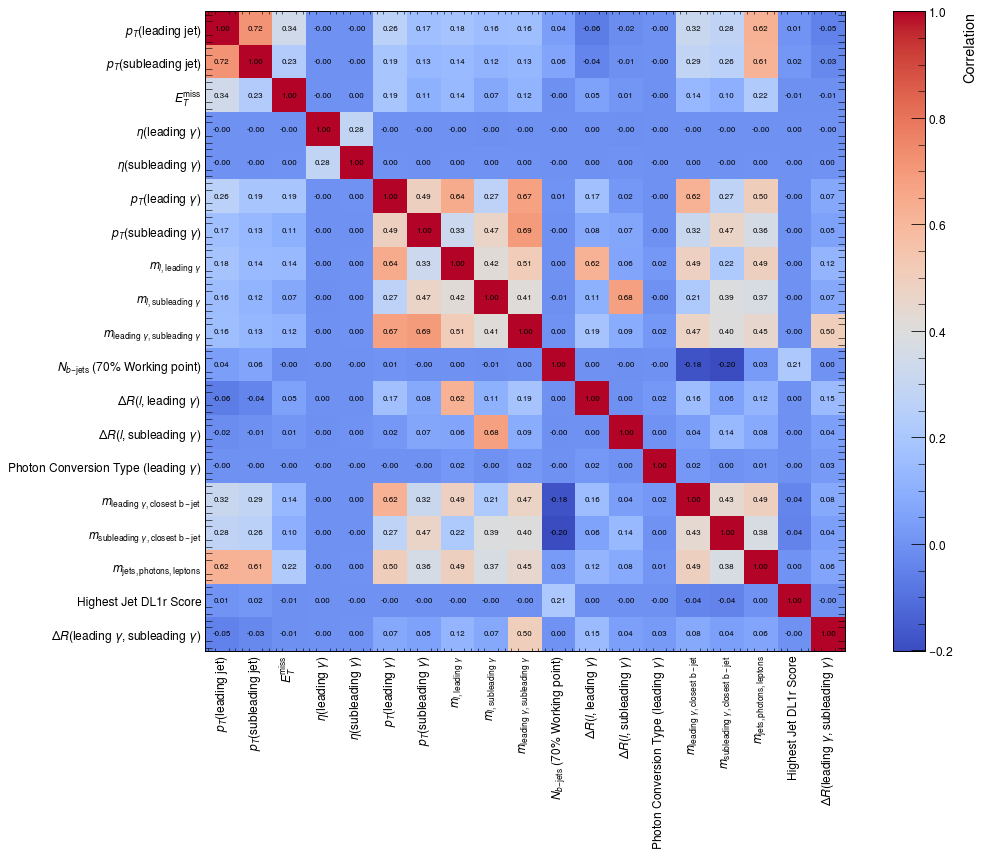

In [39]:
labels = sig_corr_matrix.columns  # already pretty names
corr = sig_corr_matrix.values

fig, ax = plt.subplots(figsize=(16, 12))
im = ax.imshow(corr, cmap='coolwarm', aspect='equal')
fig.colorbar(im, ax=ax, label='Correlation')

# tick labels
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=90)
ax.set_yticklabels(labels)

# annotate cells
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{corr[i, j]:.2f}",
                ha='center', va='center', fontsize=8)

ax.set_facecolor('white')
ax.tick_params(bottom=False, left=False, top=False, right=False)
fig.tight_layout()
plt.show()


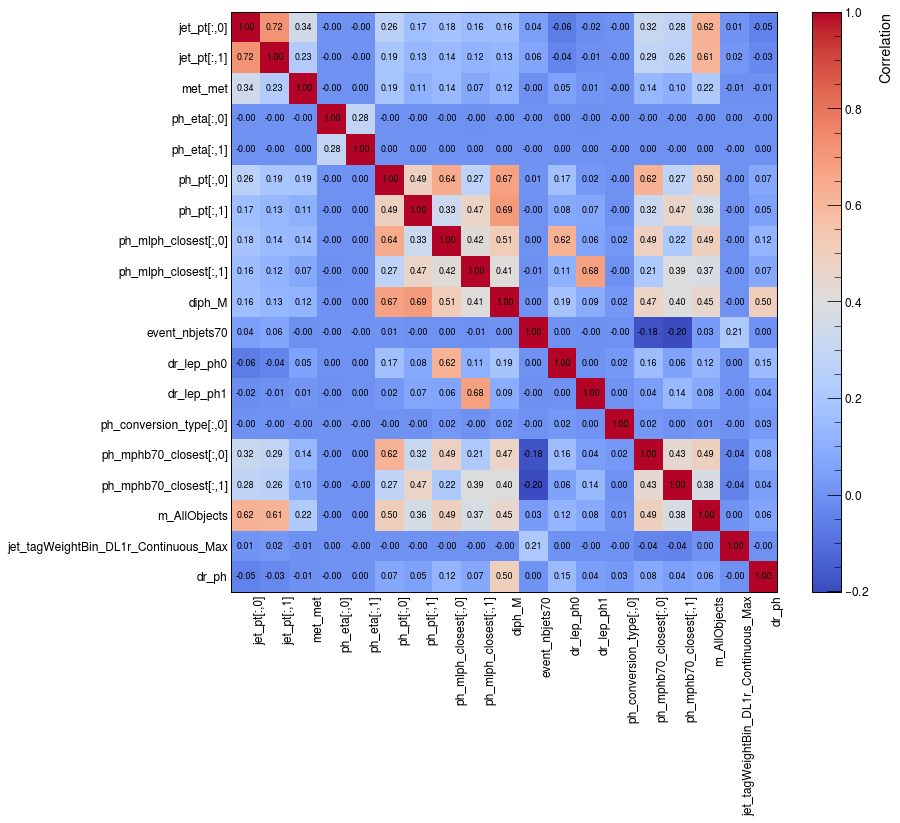

In [35]:
fig,ax = plt.subplots(figsize=(12, 10))  # Adjust width and height for desired size

# Create heatmap with coolwarm colormap and white background
corr = sig_corr_matrix.values  # Assuming sig_corr_matrix is your correlation matrix

# Create heatmap
heatmap = plt.imshow(corr, cmap='coolwarm', aspect='auto')

# Add colorbar
plt.colorbar(heatmap, label='Correlation')

# Add white background to the plot area
ax.set_facecolor('white')  # 'gca' gets current axis

# Add annotations for each cell (replace '.1g' with desired format if needed)
for i in range(len(corr)):
    for j in range(len(corr[0])):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha='center', va='center', fontsize=9)  # Adjust formatting

        
#plt.xticks(rotation=45, ha='right', fontsize=9)  # Adjust rotation, alignment, and size
#plt.yticks(fontsize=9)
plt.xticks(range(len(feature_display_names)), list(feature_display_names.values()), rotation=90)
plt.yticks(range(len(feature_display_names)), list(feature_display_names.values()))
ax.set_xticks(np.arange(len(feature_display_names))+0.5,feature_display_names)
ax.set_yticks(np.arange(len(feature_display_names)),feature_display_names)

plt.tick_params(which='both', bottom=False, top=False, left=False, right=False)  # Set visibility for all sides

#plt.savefig('sig_correlation_heatmap_seaborn_large_white_Model6.png', dpi=500, bbox_inches='tight')


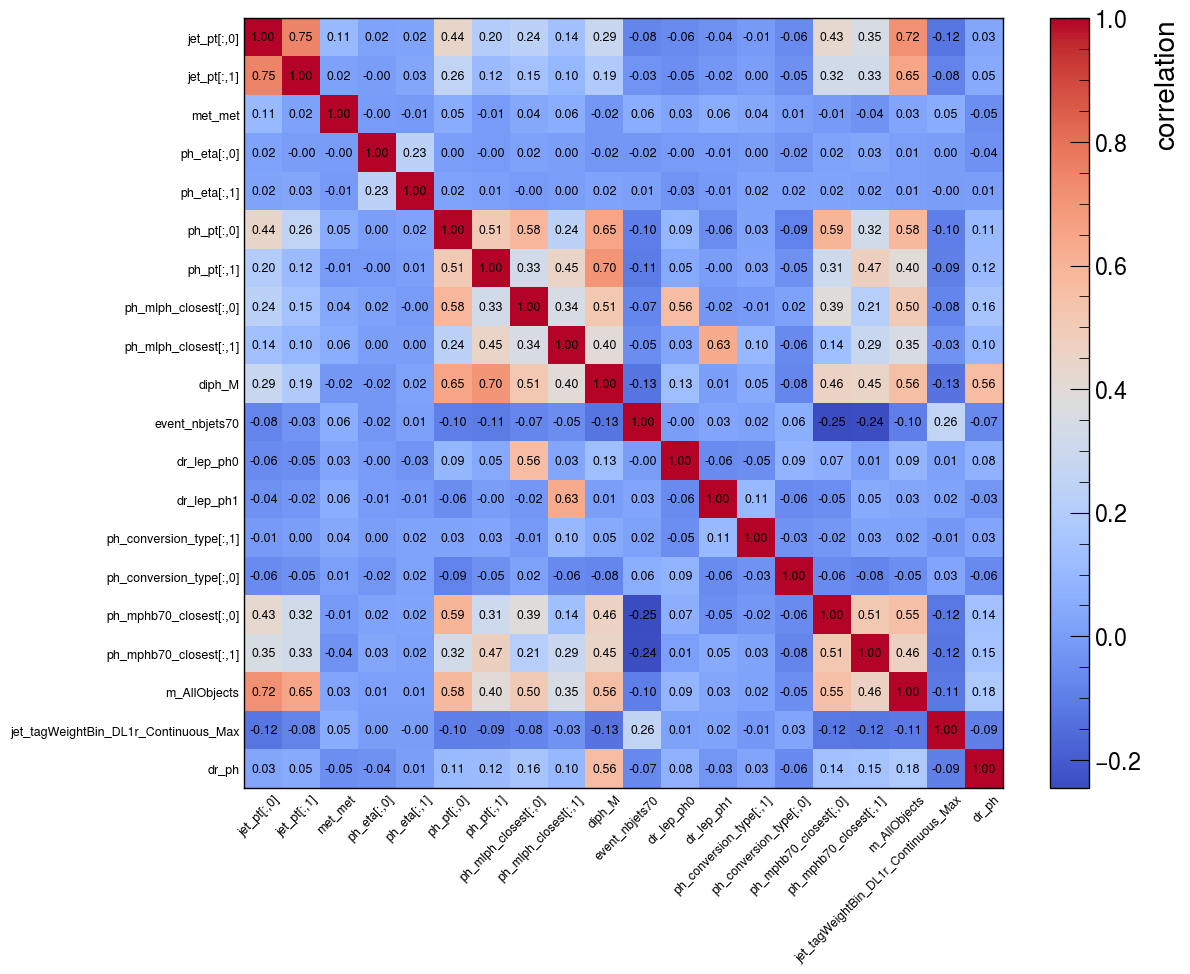

In [24]:
fig,ax = plt.subplots(figsize=(12, 10))  # Adjust width and height for desired size

# Create heatmap with coolwarm colormap and white background
corr = bkg_corr_matrix.values  # Assuming bkg_corr_matrix is your correlation matrix

# Create heatmap
heatmap = plt.imshow(corr, cmap='coolwarm', aspect='auto')

# Add colorbar
plt.colorbar(heatmap, label='correlation')

# Add white background to the plot area
ax.set_facecolor('white')  # 'gca' gets current axis

# Add annotations for each cell (replace '.1g' with desired format if needed)
for i in range(len(corr)):
    for j in range(len(corr[0])):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha='center', va='center', fontsize=9)  # Adjust formatting

        
plt.xticks(rotation=45, ha='right', fontsize=9)  # Adjust rotation, alignment, and size
plt.yticks(fontsize=9)
ax.set_xticks(np.arange(len(feature_cols))+0.5,feature_cols)
ax.set_yticks(np.arange(len(feature_cols)),feature_cols)

plt.tick_params(which='both', bottom=False, top=False, left=False, right=False)  # Set visibility for all sides


plt.savefig('bkg_correlation_heatmap_seaborn_large_white_Model6.png', dpi=500, bbox_inches='tight')



In [45]:
print(len(corr))

5


In [32]:
xgboost.__version__

'2.0.2'